# Step 6: Data Analysis

In [1]:
# !pip install dataframe_image
# !pip install upsetplot
# !pip install dfstyle

In [2]:
import os
from collections import Counter
import seaborn as sns
import pandas as pd
# import dataframe_image as dfi
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from datetime import date, datetime as dt
import time,datetime
import re
import unicodedata
import ast  # Module to handle literal_eval function

In [3]:
from upsetplot import generate_counts
from upsetplot import plot
from upsetplot import from_memberships
from upsetplot import UpSet
from matplotlib import pyplot
from itertools import combinations

In [4]:
from mpl_toolkits.axes_grid1.inset_locator import zoomed_inset_axes
from mpl_toolkits.axes_grid1.inset_locator import mark_inset
from matplotlib.ticker import MaxNLocator

%matplotlib notebook

In [5]:
data_dir = 'data/' # data directory
result_dir = 'result/'

In [6]:
# Create 'result/RetractionIndexingAgreement_ITEM' directory to store RetractionIndexingAgreement Score
if not os.path.exists(result_dir+'RetractionIndexingAgreement_ITEM/'):
        os.mkdir(result_dir+'RetractionIndexingAgreement_ITEM/')

In [7]:
def convert_unicode(string: str) -> str:
    """
    It takes a string and passes it through different encoding parameter phases
    E.g. '10.\u200b1105/\u200btpc.\u200b010357' ->  '10.1105/tpc.010357'
    
    :param string: variable to be encoded
    :return: the actual string value devoided of encoded character
    """
    
    string = unicodedata.normalize('NFKD', string).encode('iso-8859-1', 'ignore').decode('iso-8859-1')
    string = unicodedata.normalize('NFKD', string).encode('latin1', 'ignore').decode('latin1')
    string = unicodedata.normalize('NFKD', string).encode('cp1252', 'ignore').decode('cp1252')
    return string


def filtered_out(df, unionList):
    """
    Filters out DOI that are outside of union list coverage
    """
    return df[df['DOI'].isin(set(unionList['DOI']))]

In [8]:
# Supply the date of coverage check for all the sources from Step 3 pipeline ({source}_coverednotindexed_{date}.csv)
date_coverage = {
            'ads': '2024-08-15',
            'bci': '2024-08-02',
            'bioabs': '2024-08-13',
            'ccc': '2024-08-05',
            'compendex': '2024-07-29',
            'geobase': '2024-07-29',
            'georef':'2024-07-30',
            'ieee':'2024-08-11', 
            'inspec': '2024-08-02',
            'medline': '2024-08-05',
            'pubmed': '2024-07-26',
            'sciencedirect': '2024-08-05',
            'scopus': '2024-08-02',
            'webofsciencecore': '2024-07-30',
            'zoorec': '2024-08-05',
   
            'retractionwatch': '2024-07-03'
            }


# Supply the date of  retracted items were collected from each source and unionlist created date
getdate = {'scopus': '2024-07-05',
            'retractionwatch': '2024-07-03',
            'pubmed': '2024-07-03',
            'geobase': '2024-07-05',
            'compendex': '2024-07-09',
            'bci': '2024-07-03',
            'bioabs': '2024-07-03',
            'ccc': '2024-07-03',
            'medline': '2024-07-03',
            'webofsciencecore': '2024-07-03',
           
            'unionlist':'2024-07-09'} 

## 1.  Generate New Unionlist For Items Coverage in Sources
- For each source, we import results items not indexed as retracted publication but were found in that source (i.e. coverage)  <- _notindexed

In [10]:
"""
Read in the unionlist of retracted items with their retracted years <- unionlist_indexed
"""

unionlist_indexed = pd.read_csv(data_dir+'unionlist/unionlist_completed_'+getdate['unionlist']+'.csv') #.drop('Unnamed: 0',axis=1)
unionlist_indexed['source'] = unionlist_indexed['source'].apply(lambda x: x.replace("  ", " "))

# Deduplicating source value 
unionlist_indexed['source'] = unionlist_indexed['source'].apply(lambda x: '; '.join(sorted(set(x.split('; ')))))
unionlist_indexed['source'] = unionlist_indexed['source'].apply(lambda x: x.strip())

unionlist_indexed #.head(5)

,DOI,Author,Title,Year,Journal,source,PubMedID,clean_title,RetractionYear,MainCategory
0,10.1001/archdermatol.2012.1796,NaN,"Notice of Retraction: ""Early Depth Assessment ...",2012,ARCHIVES OF DERMATOLOGY,CCC; WoS_Core,22556314.0,"notice of retraction ""early depth assessment o...",0,Health Sciences
1,10.1001/archdermatol.2012.418,Kyomi Mihara;Hajime Shindo;Hiroya Mihara;Minak...,Early depth assessment of local burns by dermo...,2012,Archives of dermatology,Medline; PubMed; Retraction Watch,22508774.0,early depth assessment of local burns by dermo...,2012,Health Sciences
2,10.1001/archinte.165.15.1737,Yoshihiro Sato;Tomohiro Kanoko;Kei Satoh;Jun I...,The prevention of hip fracture with risedronat...,2005,ARCHIVES OF INTERNAL MEDICINE,BCI; BIOABS; CCC; Medline; PubMed; Retraction ...,16087821.0,the prevention of hip fracture with risedronat...,2016,Health Sciences
3,10.1001/archinte.165.15.1743,Yoshihiro Sato;Jun Iwamoto;Tomohiro Kanoko;Kei...,Risedronate sodium therapy for prevention of h...,2005,Archives of Internal Medicine,BCI; BIOABS; CCC; Medline; PubMed; Retraction ...,16087822.0,risedronate sodium therapy for prevention of h...,2016,Health Sciences
4,10.1001/archinte.165.18.2142,Demosthenes B Panagiotakos;Daan Kromhout;Aless...,The Relation Between Pulse Pressure and Cardio...,2005,JAMA Internal Medicine,BCI; BIOABS; CCC; Medline; PubMed; Retraction ...,16217005.0,the relation between pulse pressure and cardio...,2006,Health Sciences
...,...,...,...,...,...,...,...,...,...,...
58591,nodoi_600,Xuelian Yin;Guang Yang;Dongjie Ma;Zhejun Su,Inhibition of cancer cell growth in cisplatin-...,2020,Journal of B.U.ON. : official journal of the B...,PubMed,32277651.0,inhibition of cancer cell growth in cisplatinr...,0,Health Science
58592,nodoi_601,Yue Wang;Mingyin Zhou;Dong Shang,Berberine inhibits human gastric cancer cell g...,2020,Journal of B.U.ON. : official journal of the B...,PubMed,32277648.0,berberine inhibits human gastric cancer cell g...,0,Health Science
58593,nodoi_602,Yuanyu Wu;Xiaoyu Wan;Xin Zhao;Zheyu Song;Zhong...,MicroRNA-143 suppresses the proliferation and ...,2020,American journal of translational research,PubMed,32269719.0,microrna143 suppresses the proliferation and m...,2021,"Life Sciences,Health Sciences"
58594,nodoi_603,Liyuan Fan;Juan Wang;Qiang Cao;Xiuping Ding;Ba...,Aberrant miR-1246 expression promotes radiores...,2020,American journal of cancer research,PubMed,32064170.0,aberrant mir1246 expression promotes radioresi...,2020,"Life Sciences,Health Sciences"


### Loading coverage items not indexed for each source

In [11]:
"""
Read in items that were covered but not indexed as retracted publication from each sources
<- source_notindexed
"""

compendex_notindexed= pd.read_csv(data_dir+'coverednotindexed/compendex_coverednotindexed_'+date_coverage['compendex']+'.csv').drop('Unnamed: 0',axis=1)
compendex_notindexed['source']=  'Compendex'

geobase_notindexed= pd.read_csv(data_dir+'coverednotindexed/geobase_coverednotindexed_'+date_coverage['geobase']+'.csv').drop('Unnamed: 0',axis=1)
geobase_notindexed['source']=  'GEOBASE'

ieee_notindexed= pd.read_csv(data_dir+'coverednotindexed/ieee_coverednotindexed_'+date_coverage['ieee']+'.csv').drop('Unnamed: 0',axis=1)
ieee_notindexed['source']=  'IEEE'

inspec_notindexed= pd.read_csv(data_dir+'coverednotindexed/inspec_coverednotindexed_'+date_coverage['inspec']+'.csv').drop('Unnamed: 0',axis=1)
inspec_notindexed['source']=  'Inspec'

pubmed_notindexed = pd.read_csv(data_dir+'coverednotindexed/pubmed_coverednotindexed_'+date_coverage['pubmed']+'.csv').drop('Unnamed: 0',axis=1)
pubmed_notindexed['source']=  'PubMed'

scopus_notindexed= pd.read_csv(data_dir+'coverednotindexed/scopus_coverednotindexed_'+date_coverage['scopus']+'.csv').drop('Unnamed: 0',axis=1)
scopus_notindexed['source']=  'Scopus'

sciencedirect_notindexed= pd.read_csv(data_dir+'coverednotindexed/sciencedirect_coverednotindexed_'+date_coverage['sciencedirect']+'.csv')
sciencedirect_notindexed['source']=  'ScienceDirect'

ads_notindexed= pd.read_csv(data_dir+'coverednotindexed/ads_coverednotindexed_'+date_coverage['ads']+'.csv')
ads_notindexed['source']=  'ADS'

bci_notindexed= pd.read_csv(data_dir+'coverednotindexed/bci_coverednotindexed_'+date_coverage['bci']+'.csv')
bci_notindexed['source']=  'BCI'

bioabs_notindexed= pd.read_csv(data_dir+'coverednotindexed/bioabs_coverednotindexed_'+date_coverage['bioabs']+'.csv')
bioabs_notindexed['source']=  'BIOABS'

ccc_notindexed= pd.read_csv(data_dir+'coverednotindexed/ccc_coverednotindexed_'+date_coverage['ccc']+'.csv').drop('Unnamed: 0',axis=1)
ccc_notindexed['source']=  'CCC'

georef_notindexed= pd.read_csv(data_dir+'coverednotindexed/georef_coverednotindexed_'+date_coverage['georef']+'.csv')
georef_notindexed['source']=  'GeoRef'

medline_notindexed= pd.read_csv(data_dir+'coverednotindexed/medline_coverednotindexed_'+date_coverage['medline']+'.csv')
medline_notindexed['source']=  'Medline'

zoorec_notindexed= pd.read_csv(data_dir+'coverednotindexed/zoorec_coverednotindexed_'+date_coverage['zoorec']+'.csv').drop('Unnamed: 0',axis=1)
zoorec_notindexed['source']=  'ZOOREC'

woscore_notindexed= pd.read_csv(data_dir+'coverednotindexed/webofsciencecore_coverednotindexed_'+date_coverage['webofsciencecore']+'.csv')
woscore_notindexed['source']=  'WoS_Core'

In [12]:
"""
Filtering DOIs that are not within union list coverage
-- It is possible for a source to return a DOI that is not included in the union list coverage when performing an API coverage check on a non-indexed item
"""
ads_notindexed = filtered_out(ads_notindexed,unionlist_indexed)
bci_notindexed = filtered_out(bci_notindexed,unionlist_indexed)
bioabs_notindexed = filtered_out(bioabs_notindexed,unionlist_indexed)
ccc_notindexed = filtered_out(ccc_notindexed,unionlist_indexed)
compendex_notindexed = filtered_out(compendex_notindexed,unionlist_indexed)
geobase_notindexed = filtered_out(geobase_notindexed,unionlist_indexed)
georef_notindexed = filtered_out(georef_notindexed,unionlist_indexed)
ieee_notindexed = filtered_out(ieee_notindexed,unionlist_indexed)
inspec_notindexed = filtered_out(inspec_notindexed,unionlist_indexed)
medline_notindexed = filtered_out(medline_notindexed,unionlist_indexed)
pubmed_notindexed = filtered_out(pubmed_notindexed,unionlist_indexed)
sciencedirect_notindexed = filtered_out(sciencedirect_notindexed,unionlist_indexed)
scopus_notindexed = filtered_out(scopus_notindexed,unionlist_indexed)
woscore_notindexed = filtered_out(woscore_notindexed,unionlist_indexed)
zoorec_notindexed = filtered_out(zoorec_notindexed,unionlist_indexed)

In [13]:
"""
Merge all the items covered but not indexed as retracted publications from each source with the
unionlist of indexed items <- unionlist_covers
"""

merged_withdoi = pd.concat([unionlist_indexed,
                            ads_notindexed,
                            bci_notindexed,
                            bioabs_notindexed, 
                            ccc_notindexed,
                            compendex_notindexed,
                            geobase_notindexed,
                            georef_notindexed,
                            ieee_notindexed,
                            inspec_notindexed,
                            medline_notindexed,
                            pubmed_notindexed,
                            sciencedirect_notindexed,
                            scopus_notindexed,
                            woscore_notindexed,
                            zoorec_notindexed,
                            ])

unionlist_covers= merged_withdoi.groupby('DOI').agg({'Author':'first', 
                              'Title': 'first',
                              'Year': 'first', 
                              'Journal': 'first',
                              'PubMedID':'first',
                              'source':'; '.join 
                              }).reset_index()
unionlist_covers["PubMedID"] = unionlist_covers["PubMedID"].fillna(0)
unionlist_covers = unionlist_covers.astype({"PubMedID": "int64"})
unionlist_covers.fillna('', inplace=True)
unionlist_covers.head()


,DOI,Author,Title,Year,Journal,PubMedID,source
0,10.1001/archdermatol.2012.1796,,"Notice of Retraction: ""Early Depth Assessment ...",2012,ARCHIVES OF DERMATOLOGY,22556314,CCC; WoS_Core; Medline; PubMed; Scopus
1,10.1001/archdermatol.2012.418,Kyomi Mihara;Hajime Shindo;Hiroya Mihara;Minak...,Early depth assessment of local burns by dermo...,2012,Archives of dermatology,22508774,Medline; PubMed; Retraction Watch; CCC
2,10.1001/archinte.165.15.1737,Yoshihiro Sato;Tomohiro Kanoko;Kei Satoh;Jun I...,The prevention of hip fracture with risedronat...,2005,ARCHIVES OF INTERNAL MEDICINE,16087821,BCI; BIOABS; CCC; Medline; PubMed; Retraction ...
3,10.1001/archinte.165.15.1743,Yoshihiro Sato;Jun Iwamoto;Tomohiro Kanoko;Kei...,Risedronate sodium therapy for prevention of h...,2005,Archives of Internal Medicine,16087822,BCI; BIOABS; CCC; Medline; PubMed; Retraction ...
4,10.1001/archinte.165.18.2142,Demosthenes B Panagiotakos;Daan Kromhout;Aless...,The Relation Between Pulse Pressure and Cardio...,2005,JAMA Internal Medicine,16217005,BCI; BIOABS; CCC; Medline; PubMed; Retraction ...


In [14]:
"""
Deduplicate the 'source' in the unionlist_covers dataframe (i.e. that entails covered all items) and 
call the source field 'source_new'.
"""

# Deduplicating source value 
unionlist_covers['source'] = unionlist_covers['source'].apply(lambda x: '; '.join(sorted(set(x.split('; ')))))

# Renaming column
unionlist_covers.rename(columns={'source': 'source_new'}, inplace=True)
print(unionlist_covers.info())
unionlist_covers

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58596 entries, 0 to 58595
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   DOI         58596 non-null  object
 1   Author      58596 non-null  object
 2   Title       58596 non-null  object
 3   Year        58596 non-null  int64 
 4   Journal     58596 non-null  object
 5   PubMedID    58596 non-null  int64 
 6   source_new  58596 non-null  object
dtypes: int64(2), object(5)
memory usage: 3.1+ MB
None


,DOI,Author,Title,Year,Journal,PubMedID,source_new
0,10.1001/archdermatol.2012.1796,,"Notice of Retraction: ""Early Depth Assessment ...",2012,ARCHIVES OF DERMATOLOGY,22556314,CCC; Medline; PubMed; Scopus; WoS_Core
1,10.1001/archdermatol.2012.418,Kyomi Mihara;Hajime Shindo;Hiroya Mihara;Minak...,Early depth assessment of local burns by dermo...,2012,Archives of dermatology,22508774,CCC; Medline; PubMed; Retraction Watch
2,10.1001/archinte.165.15.1737,Yoshihiro Sato;Tomohiro Kanoko;Kei Satoh;Jun I...,The prevention of hip fracture with risedronat...,2005,ARCHIVES OF INTERNAL MEDICINE,16087821,BCI; BIOABS; CCC; Medline; PubMed; Retraction ...
3,10.1001/archinte.165.15.1743,Yoshihiro Sato;Jun Iwamoto;Tomohiro Kanoko;Kei...,Risedronate sodium therapy for prevention of h...,2005,Archives of Internal Medicine,16087822,BCI; BIOABS; CCC; Medline; PubMed; Retraction ...
4,10.1001/archinte.165.18.2142,Demosthenes B Panagiotakos;Daan Kromhout;Aless...,The Relation Between Pulse Pressure and Cardio...,2005,JAMA Internal Medicine,16217005,BCI; BIOABS; CCC; Medline; PubMed; Retraction ...
...,...,...,...,...,...,...,...
58591,nodoi_95,J Boldt;B Zickmann;A Thiel;C Herold;F Dapper;G...,[Hyperosmolar volume replacement in heart surg...,1990,Der Anaesthesist,1699443,PubMed
58592,nodoi_96,E Tseng;S M Potter;M F Picciano,Dietary protein source and plasma lipid profil...,1990,Pediatrics,2242108,PubMed
58593,nodoi_97,A Jendryczko;M Drózdz,[Mitochondrial DNA mutations as a factor of th...,1990,Przeglad lekarski,2287751,PubMed
58594,nodoi_98,M Quik;R Afar;S Geertsen;T Audhya;G Goldstein;...,"Thymopoietin, a thymic polypeptide, regulates ...",1990,Molecular pharmacology,1967819,PubMed


In [15]:
unionlist_indexed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58596 entries, 0 to 58595
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   DOI             58596 non-null  object 
 1   Author          57056 non-null  object 
 2   Title           58588 non-null  object 
 3   Year            58596 non-null  int64  
 4   Journal         58596 non-null  object 
 5   source          58596 non-null  object 
 6   PubMedID        25997 non-null  float64
 7   clean_title     58587 non-null  object 
 8   RetractionYear  58596 non-null  int64  
 9   MainCategory    56413 non-null  object 
dtypes: float64(1), int64(2), object(7)
memory usage: 4.5+ MB



## Section 2: Calculation of RetractionIndexAgreement by Source

In [16]:
"""
Merge unionlist_covers (that details covered items) and unionlist_indexed (that detailed indexed retracted items)
Call 'source' column in unionlist_indexed 'source_old'
"""

unionlist3 = pd.merge(unionlist_covers, 
                      unionlist_indexed[['DOI','source','MainCategory','RetractionYear']].rename(columns={'source':'source_old'}), 
                      on='DOI')

# Store 'source_old' & 'source_old' value as sorted list
unionlist3['source_old'] = unionlist3['source_old'].apply(lambda x: sorted(x.split('; ')))#.astype(str)
unionlist3['source_new'] = unionlist3['source_new'].apply(lambda x: sorted(x.split('; ')))#.astype(str)

# Convert Year to int
unionlist3['Year']= unionlist3['Year'].astype(int)

# Fill RetractionYear NA with 0
unionlist3['RetractionYear']= unionlist3['RetractionYear'].fillna(0).astype(int)

# Convert PubMedID to String
unionlist3['PubMedID']=unionlist3['PubMedID'].replace(0,'').astype(str).str.strip()

# Calculate time until retraction
unionlist3['TimetoRetraction']= (unionlist3['RetractionYear'] - unionlist3['Year'])
unionlist3 # .head()

,DOI,Author,Title,Year,Journal,PubMedID,source_new,source_old,MainCategory,RetractionYear,TimetoRetraction
0,10.1001/archdermatol.2012.1796,,"Notice of Retraction: ""Early Depth Assessment ...",2012,ARCHIVES OF DERMATOLOGY,22556314,"[CCC, Medline, PubMed, Scopus, WoS_Core]","[CCC, WoS_Core]",Health Sciences,0,-2012
1,10.1001/archdermatol.2012.418,Kyomi Mihara;Hajime Shindo;Hiroya Mihara;Minak...,Early depth assessment of local burns by dermo...,2012,Archives of dermatology,22508774,"[CCC, Medline, PubMed, Retraction Watch]","[Medline, PubMed, Retraction Watch]",Health Sciences,2012,0
2,10.1001/archinte.165.15.1737,Yoshihiro Sato;Tomohiro Kanoko;Kei Satoh;Jun I...,The prevention of hip fracture with risedronat...,2005,ARCHIVES OF INTERNAL MEDICINE,16087821,"[BCI, BIOABS, CCC, Medline, PubMed, Retraction...","[BCI, BIOABS, CCC, Medline, PubMed, Retraction...",Health Sciences,2016,11
3,10.1001/archinte.165.15.1743,Yoshihiro Sato;Jun Iwamoto;Tomohiro Kanoko;Kei...,Risedronate sodium therapy for prevention of h...,2005,Archives of Internal Medicine,16087822,"[BCI, BIOABS, CCC, Medline, PubMed, Retraction...","[BCI, BIOABS, CCC, Medline, PubMed, Retraction...",Health Sciences,2016,11
4,10.1001/archinte.165.18.2142,Demosthenes B Panagiotakos;Daan Kromhout;Aless...,The Relation Between Pulse Pressure and Cardio...,2005,JAMA Internal Medicine,16217005,"[BCI, BIOABS, CCC, Medline, PubMed, Retraction...","[BCI, BIOABS, CCC, Medline, PubMed, Retraction...",Health Sciences,2006,1
...,...,...,...,...,...,...,...,...,...,...,...
58591,nodoi_95,J Boldt;B Zickmann;A Thiel;C Herold;F Dapper;G...,[Hyperosmolar volume replacement in heart surg...,1990,Der Anaesthesist,1699443,[PubMed],[PubMed],Health Science,2020,30
58592,nodoi_96,E Tseng;S M Potter;M F Picciano,Dietary protein source and plasma lipid profil...,1990,Pediatrics,2242108,[PubMed],[PubMed],Health Sciences,1990,0
58593,nodoi_97,A Jendryczko;M Drózdz,[Mitochondrial DNA mutations as a factor of th...,1990,Przeglad lekarski,2287751,[PubMed],[PubMed],Health Sciences,1997,7
58594,nodoi_98,M Quik;R Afar;S Geertsen;T Audhya;G Goldstein;...,"Thymopoietin, a thymic polypeptide, regulates ...",1990,Molecular pharmacology,1967819,[PubMed],[PubMed],Life Sciences,1993,3


In [17]:
"""
Remove sources from sources_new that have no indexed items for initial calculations
"""
unionlist3_adjusted = unionlist3.copy(deep=True)

# Removing 'ADS','GeoRef','IEEE','Inspec','ScienceDirect', 'ZOOREC' since they have no indexed retracted items
removed_sources_new= ['ADS','GeoRef','IEEE','Inspec','ScienceDirect', 'ZOOREC']
unionlist3_adjusted['source_new']= unionlist3_adjusted['source_new'].apply(lambda x: [item for item in x if item not in removed_sources_new])

unionlist3_adjusted['source_new']= unionlist3_adjusted.source_new.astype(str)

unionlist3_adjusted['source_old']= unionlist3_adjusted.source_old.astype(str)

unionlist3_adjusted # .head()

,DOI,Author,Title,Year,Journal,PubMedID,source_new,source_old,MainCategory,RetractionYear,TimetoRetraction
0,10.1001/archdermatol.2012.1796,,"Notice of Retraction: ""Early Depth Assessment ...",2012,ARCHIVES OF DERMATOLOGY,22556314,"['CCC', 'Medline', 'PubMed', 'Scopus', 'WoS_Co...","['CCC', 'WoS_Core']",Health Sciences,0,-2012
1,10.1001/archdermatol.2012.418,Kyomi Mihara;Hajime Shindo;Hiroya Mihara;Minak...,Early depth assessment of local burns by dermo...,2012,Archives of dermatology,22508774,"['CCC', 'Medline', 'PubMed', 'Retraction Watch']","['Medline', 'PubMed', 'Retraction Watch']",Health Sciences,2012,0
2,10.1001/archinte.165.15.1737,Yoshihiro Sato;Tomohiro Kanoko;Kei Satoh;Jun I...,The prevention of hip fracture with risedronat...,2005,ARCHIVES OF INTERNAL MEDICINE,16087821,"['BCI', 'BIOABS', 'CCC', 'Medline', 'PubMed', ...","['BCI', 'BIOABS', 'CCC', 'Medline', 'PubMed', ...",Health Sciences,2016,11
3,10.1001/archinte.165.15.1743,Yoshihiro Sato;Jun Iwamoto;Tomohiro Kanoko;Kei...,Risedronate sodium therapy for prevention of h...,2005,Archives of Internal Medicine,16087822,"['BCI', 'BIOABS', 'CCC', 'Medline', 'PubMed', ...","['BCI', 'BIOABS', 'CCC', 'Medline', 'PubMed', ...",Health Sciences,2016,11
4,10.1001/archinte.165.18.2142,Demosthenes B Panagiotakos;Daan Kromhout;Aless...,The Relation Between Pulse Pressure and Cardio...,2005,JAMA Internal Medicine,16217005,"['BCI', 'BIOABS', 'CCC', 'Medline', 'PubMed', ...","['BCI', 'BIOABS', 'CCC', 'Medline', 'PubMed', ...",Health Sciences,2006,1
...,...,...,...,...,...,...,...,...,...,...,...
58591,nodoi_95,J Boldt;B Zickmann;A Thiel;C Herold;F Dapper;G...,[Hyperosmolar volume replacement in heart surg...,1990,Der Anaesthesist,1699443,['PubMed'],['PubMed'],Health Science,2020,30
58592,nodoi_96,E Tseng;S M Potter;M F Picciano,Dietary protein source and plasma lipid profil...,1990,Pediatrics,2242108,['PubMed'],['PubMed'],Health Sciences,1990,0
58593,nodoi_97,A Jendryczko;M Drózdz,[Mitochondrial DNA mutations as a factor of th...,1990,Przeglad lekarski,2287751,['PubMed'],['PubMed'],Health Sciences,1997,7
58594,nodoi_98,M Quik;R Afar;S Geertsen;T Audhya;G Goldstein;...,"Thymopoietin, a thymic polypeptide, regulates ...",1990,Molecular pharmacology,1967819,['PubMed'],['PubMed'],Life Sciences,1993,3


In [18]:
# Starting Calculations
# Set up the formula for the calculation
count_sources_covering_item = unionlist3_adjusted.source_new.apply(ast.literal_eval).apply(len)

count_sources_indexing_item_as_retracted = unionlist3_adjusted.source_old.apply(ast.literal_eval).apply(len)

RetractionIndexingDiscrepancy_ITEM = count_sources_indexing_item_as_retracted / count_sources_covering_item

# Add the calculation score to dataframe
unionlist3_adjusted['RetractionIndexingAgreement_ITEM(%)'] = ((RetractionIndexingDiscrepancy_ITEM)*100).astype(float)
unionlist3_adjusted = unionlist3_adjusted.sort_index()

# Saving file to unionlist folder
unionlist3_adjusted.to_csv(data_dir+f"unionlist/unionlist_completed_ria_{getdate['unionlist']}.csv",index=False)

unionlist3_adjusted

,DOI,Author,Title,Year,Journal,PubMedID,source_new,source_old,MainCategory,RetractionYear,TimetoRetraction,RetractionIndexingAgreement_ITEM(%)
0,10.1001/archdermatol.2012.1796,,"Notice of Retraction: ""Early Depth Assessment ...",2012,ARCHIVES OF DERMATOLOGY,22556314,"['CCC', 'Medline', 'PubMed', 'Scopus', 'WoS_Co...","['CCC', 'WoS_Core']",Health Sciences,0,-2012,40.0
1,10.1001/archdermatol.2012.418,Kyomi Mihara;Hajime Shindo;Hiroya Mihara;Minak...,Early depth assessment of local burns by dermo...,2012,Archives of dermatology,22508774,"['CCC', 'Medline', 'PubMed', 'Retraction Watch']","['Medline', 'PubMed', 'Retraction Watch']",Health Sciences,2012,0,75.0
2,10.1001/archinte.165.15.1737,Yoshihiro Sato;Tomohiro Kanoko;Kei Satoh;Jun I...,The prevention of hip fracture with risedronat...,2005,ARCHIVES OF INTERNAL MEDICINE,16087821,"['BCI', 'BIOABS', 'CCC', 'Medline', 'PubMed', ...","['BCI', 'BIOABS', 'CCC', 'Medline', 'PubMed', ...",Health Sciences,2016,11,87.5
3,10.1001/archinte.165.15.1743,Yoshihiro Sato;Jun Iwamoto;Tomohiro Kanoko;Kei...,Risedronate sodium therapy for prevention of h...,2005,Archives of Internal Medicine,16087822,"['BCI', 'BIOABS', 'CCC', 'Medline', 'PubMed', ...","['BCI', 'BIOABS', 'CCC', 'Medline', 'PubMed', ...",Health Sciences,2016,11,87.5
4,10.1001/archinte.165.18.2142,Demosthenes B Panagiotakos;Daan Kromhout;Aless...,The Relation Between Pulse Pressure and Cardio...,2005,JAMA Internal Medicine,16217005,"['BCI', 'BIOABS', 'CCC', 'Medline', 'PubMed', ...","['BCI', 'BIOABS', 'CCC', 'Medline', 'PubMed', ...",Health Sciences,2006,1,87.5
...,...,...,...,...,...,...,...,...,...,...,...,...
58591,nodoi_95,J Boldt;B Zickmann;A Thiel;C Herold;F Dapper;G...,[Hyperosmolar volume replacement in heart surg...,1990,Der Anaesthesist,1699443,['PubMed'],['PubMed'],Health Science,2020,30,100.0
58592,nodoi_96,E Tseng;S M Potter;M F Picciano,Dietary protein source and plasma lipid profil...,1990,Pediatrics,2242108,['PubMed'],['PubMed'],Health Sciences,1990,0,100.0
58593,nodoi_97,A Jendryczko;M Drózdz,[Mitochondrial DNA mutations as a factor of th...,1990,Przeglad lekarski,2287751,['PubMed'],['PubMed'],Health Sciences,1997,7,100.0
58594,nodoi_98,M Quik;R Afar;S Geertsen;T Audhya;G Goldstein;...,"Thymopoietin, a thymic polypeptide, regulates ...",1990,Molecular pharmacology,1967819,['PubMed'],['PubMed'],Life Sciences,1993,3,100.0


In [19]:
"""
Export of Retraction Indexing Agreement Score into 'RetractionIndexingAgreement_ITEM' folder
v = unique retraction indexing agreement scores from unionlist3_adjusted, stored as an array
c = count of items with unique retraction indexing agreement score, stored as an array
s = v variable stored as a list
"""

v, c = np.unique(unionlist3_adjusted['RetractionIndexingAgreement_ITEM(%)'], return_counts=True)
s = v.tolist()

for i in s:
    exp = unionlist3_adjusted[unionlist3_adjusted['RetractionIndexingAgreement_ITEM(%)']== i]
    exp.to_csv(result_dir+'/RetractionIndexingAgreement_ITEM/RetractionIndexingAgreement_ITEM_' + str(i) + '.csv' )

unionlist3_adjusted.to_csv(result_dir+'/RetractionIndexingAgreement_ITEM/RetractionIndexingAgreement_ITEM_all.csv')

In [20]:
v,c

(array([ 10.        ,  11.11111111,  12.5       ,  14.28571429,
         16.66666667,  20.        ,  22.22222222,  25.        ,
         28.57142857,  30.        ,  33.33333333,  37.5       ,
         40.        ,  42.85714286,  44.44444444,  50.        ,
         55.55555556,  57.14285714,  60.        ,  62.5       ,
         66.66666667,  70.        ,  71.42857143,  75.        ,
         77.77777778,  80.        ,  83.33333333,  85.71428571,
         87.5       ,  88.88888889,  90.        , 100.        ]),
 array([    1,    10,   102,   244,   184,   635,     3,  1699,   242,
            5,  2243,   170,  1715,   489,    18,  7224,    90,  1058,
         2173,   776,  2961,    45,   861,  3202,   263,  4372,  3265,
         1204,  3534,   137,    11, 19660]))

### 2.1  Calculation of RetractionIndexAgreement for Each Source

In [21]:
def count_source(df: pd.DataFrame, source_name: str) -> tuple:
    """
    :param df: DataFrame to work on
    :param source_name: source to lookup to determine count
    
    :return: tuple of no_inOLD, no_inNEW
    """
    
    no_inOLD= len(set(df[(df['source_old'].str.contains(source_name, na=False))]['DOI'])) #.count()[0]
    
    no_inNEW= len(set(df[(df['source_new'].str.contains(source_name, na=False))]['DOI'])) #.count()[0]
    
    return  no_inOLD, no_inNEW

In [22]:
"""
Counting # of items indexed and covered in each source
"""

bci_count= count_source(unionlist3_adjusted, 'BCI')

bioabs_count= count_source(unionlist3_adjusted, 'BIOABS')

ccc_count= count_source(unionlist3_adjusted, 'CCC')

compendex_count= count_source(unionlist3_adjusted, 'Compendex')

geobase_count= count_source(unionlist3_adjusted, 'GEOBASE')

pubmed_count= count_source(unionlist3_adjusted, 'PubMed')

medline_count= count_source(unionlist3_adjusted, 'Medline')

scopus_count= count_source(unionlist3_adjusted, 'Scopus')

webofsciencecore_count= count_source(unionlist3_adjusted, 'WoS_Core')

retractionwatch_count= count_source(unionlist3_adjusted, 'Retraction Watch')

ads_count= (0, len(ads_notindexed))
georef_count= (0, len(georef_notindexed))
ieee_count= (0, len(ieee_notindexed))
inspec_count=  (0, len(inspec_notindexed))
sciencedirect_count= (0, len(sciencedirect_notindexed))
zoorec_count= (0, len(zoorec_notindexed))


In [23]:
"""
Set up variables to be used for labeling and narrowing down sources with retraction indexing from unionlist
"""

all_sources = ['ADS','BCI','BIOABS','CCC','Compendex','GEOBASE', 'GeoRef', 'IEEE','INSPEC','MEDLINE',
                   'PubMed', 'Retraction Watch', 'ScienceDirect', 'Scopus', 'Web of Science Core', 'ZOOREC'] 

# Web of Science Core listed in unionlist as WoS_Core
# Biological Abstracts listed in unionlist as BIOABS
# MEDLINE listed in unionlist as Medline

sources_indexed= ['BCI','BIOABS','CCC','Compendex', 'GEOBASE', 'Medline',
                   'PubMed', 'Retraction Watch', 'Scopus', 'WoS_Core']


In [24]:
"""
Calculating # items not indexed as retracted for each source -> not_covered list
"""
not_covered= [len(unionlist3_adjusted)- len(bci_notindexed)- bci_count[0],
                len(unionlist3_adjusted)- len(bioabs_notindexed)- bioabs_count[0],
                len(unionlist3_adjusted)- len(ccc_notindexed)- ccc_count[0],
                len(unionlist3_adjusted)- len(compendex_notindexed)- compendex_count[0],
                len(unionlist3_adjusted)- len(geobase_notindexed)- geobase_count[0],
                len(unionlist3_adjusted)- len(medline_notindexed)- medline_count[0],
                len(unionlist3_adjusted)- len(pubmed_notindexed)- pubmed_count[0],
                len(unionlist3_adjusted)- len(scopus_notindexed)- scopus_count[0],
                len(unionlist3_adjusted)- len(woscore_notindexed)- webofsciencecore_count[0]]

In [25]:
"""
- Computing the Retraction Indexing Agreement score for sources (indexed sources only)
- Putting results of # indexed, coverednotindexed, not_covered
"""

table = pd.DataFrame()
table['source']= ['BCI', 'BIOABS', 'CCC','Compendex',  'GEOBASE', 'MEDLINE', 'PubMed', 'Scopus', 'Web of Science Core']
table['indexed_as_retracted']= [bci_count[0],
                                bioabs_count[0],
                                ccc_count[0], 
                                compendex_count[0], 
                                geobase_count[0], 
                                medline_count[0], 
                                pubmed_count[0], 
                                scopus_count[0], 
                                webofsciencecore_count[0]]

table['covered_but_not_indexed_as_retracted'] = [len(bci_notindexed), 
                                                 len(bioabs_notindexed), 
                                                 len(ccc_notindexed),
                                                 len(compendex_notindexed),
                                                 len(geobase_notindexed),
                                                 len(medline_notindexed),
                                                 len(pubmed_notindexed),
                                                 len(scopus_notindexed),
                                                 len(woscore_notindexed)]

table['not_covered'] = not_covered

# Calculate the retraction agreement between sources that have retraction indexing
ria_source=[]

for i in range(0,9):
    D = table['indexed_as_retracted'][i] + table['covered_but_not_indexed_as_retracted'][i]   
    ria_source.append(round(((table['indexed_as_retracted'][i]/D)*100), 2))

table['RetractionIndexingAgreement_SOURCE(%)'] = [ria_source[0],
                                                  ria_source[1], 
                                                  ria_source[2], 
                                                  ria_source[3], 
                                                  ria_source[4], 
                                                  ria_source[5], 
                                                  ria_source[6], 
                                                  ria_source[7], 
                                                  ria_source[8]]
 #set first column as index
table = table.sort_values(by='source')#.set_index(table.columns[0])
table = table.reset_index()
table =table.drop('index',axis=1)
table


,source,indexed_as_retracted,covered_but_not_indexed_as_retracted,not_covered,RetractionIndexingAgreement_SOURCE(%)
0,BCI,10294,3123,45179,76.72
1,BIOABS,10166,3034,45396,77.02
2,CCC,13257,26393,18946,33.44
3,Compendex,19266,7155,32175,72.92
4,GEOBASE,1039,449,57108,69.83
5,MEDLINE,22304,2810,33482,88.81
6,PubMed,22766,3194,32636,87.70
7,Scopus,30888,20743,6965,59.82
8,Web of Science Core,31959,6386,20251,83.35


In [26]:
all_sources

['ADS',
 'BCI',
 'BIOABS',
 'CCC',
 'Compendex',
 'GEOBASE',
 'GeoRef',
 'IEEE',
 'INSPEC',
 'MEDLINE',
 'PubMed',
 'Retraction Watch',
 'ScienceDirect',
 'Scopus',
 'Web of Science Core',
 'ZOOREC']

In [27]:
"""
Computing the Retraction Indexing Agreement score for all sources
"""
overview_RIA_source= pd.DataFrame()
overview_RIA_source['Source']= all_sources

sources_count= [ads_count,
                bci_count,
                bioabs_count, 
                ccc_count,
                compendex_count, 
                geobase_count, 
                georef_count, 
                ieee_count,
                inspec_count, 
                medline_count, 
                pubmed_count, 
                retractionwatch_count,
                sciencedirect_count, 
                scopus_count, 
                webofsciencecore_count, 
                zoorec_count]

total_unionlist = len(unionlist3_adjusted)


indexed_as_retracted=[]
covered_notindexed=[]
not_coveredinUnionlist=[]

for source in sources_count:
    indexed_as_retracted.append(source[0])
    covered_notindexed.append(source[1] - source[0])
    not_coveredinUnionlist.append(total_unionlist - (source[1]))

overview_RIA_source['Indexed_as_retracted'] = indexed_as_retracted
overview_RIA_source['Covered_notindexed'] = covered_notindexed
overview_RIA_source['Not_coveredinUnionlist'] = not_coveredinUnionlist


# Calculating RIA Score for Sources
overview_RIA_source['RetractionIndexingAgreement_SOURCE(%)']= \
       round(((overview_RIA_source['Indexed_as_retracted'] / \
               (overview_RIA_source['Indexed_as_retracted'] + overview_RIA_source['Covered_notindexed'])) *100),2)


# Uncomment for confirmation -  all the rows must be equal to the total records of the Unionlist
# overview_RIA_source['Total'] = overview_RIA_source['Indexed_as_retracted']+\
#                                 overview_RIA_source['Covered_notindexed'] + overview_RIA_source['Not_coveredinUnionlist']

overview_RIA_source

,Source,Indexed_as_retracted,Covered_notindexed,Not_coveredinUnionlist,RetractionIndexingAgreement_SOURCE(%)
0,ADS,0,6645,51951,0.00
1,BCI,10294,3123,45179,76.72
2,BIOABS,10166,3034,45396,77.02
3,CCC,13257,26384,18955,33.44
4,Compendex,19266,7155,32175,72.92
5,GEOBASE,1039,449,57108,69.83
6,GeoRef,0,216,58380,0.00
7,IEEE,0,11840,46756,0.00
8,INSPEC,0,15162,43434,0.00
9,MEDLINE,22304,2809,33483,88.81


In [28]:
"""
Save overview_RIA_source result to folder
- uncomment last line to save 
"""

overview_RIA_source.to_csv(result_dir+'RIA_score_sources_data.csv')

In [29]:
"""
Double-checking result in RIA_score for 'CCC'
"""

# Confirming the calculation
c= unionlist3_adjusted[unionlist3_adjusted['source_new'].apply(lambda x: 'CCC' in x)].count()[0]
i= unionlist3_adjusted[unionlist3_adjusted['source_old'].apply(lambda x: 'CCC' in x)].count()[0]
print(c,'\t',i)
print((i/c)*100)
print(c - i)

39641 	 13257
33.44264776367902
26384


/var/folders/yk/fnf1_8ns45l37dy9skp83h5r0000gn/T/ipykernel_76076/171482187.py:6: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  c= unionlist3_adjusted[unionlist3_adjusted['source_new'].apply(lambda x: 'CCC' in x)].count()[0]
/var/folders/yk/fnf1_8ns45l37dy9skp83h5r0000gn/T/ipykernel_76076/171482187.py:7: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  i= unionlist3_adjusted[unionlist3_adjusted['source_old'].apply(lambda x: 'CCC' in x)].count()[0]


### 2.2  Calculation of RetractionIndexAgreement by Sources

In [30]:
"""
Partitioning the data source by size
"""

# ADS, GeoRef, IEEE, INSPEC, ScienceDirect, ZOOREC
overview_RIA_source_1 = overview_RIA_source.iloc[[0,6,7,8,12,15],:]

# Sources that index retracted publications, excluding Retraction Watch
#overview_RIA_source.iloc[[1,2,3,4,5,6,10,11,14,15],:].copy()

# BCI, BIOABS, CCC, GEOBASE
overview_RIA_source_2_1 = overview_RIA_source.iloc[[1,2,3,5],:].copy()

# Compendex, MEDLINE, PubMed, Retraction Watch, Scopus, Web of Science Core
overview_RIA_source_2_2 = overview_RIA_source.iloc[[4,9,10,11,13,14],:].copy()
overview_RIA_source_2_2

,Source,Indexed_as_retracted,Covered_notindexed,Not_coveredinUnionlist,RetractionIndexingAgreement_SOURCE(%)
4,Compendex,19266,7155,32175,72.92
9,MEDLINE,22304,2809,33483,88.81
10,PubMed,22766,3193,32637,87.70
11,Retraction Watch,43311,0,15285,100.00
13,Scopus,30888,20743,6965,59.82
14,Web of Science Core,31959,6386,20251,83.35


In [31]:
# %matplotlib notebook
%matplotlib inline

##### Uncomment the last line of cell "plt.savefig(...)" to graph results for every analysis

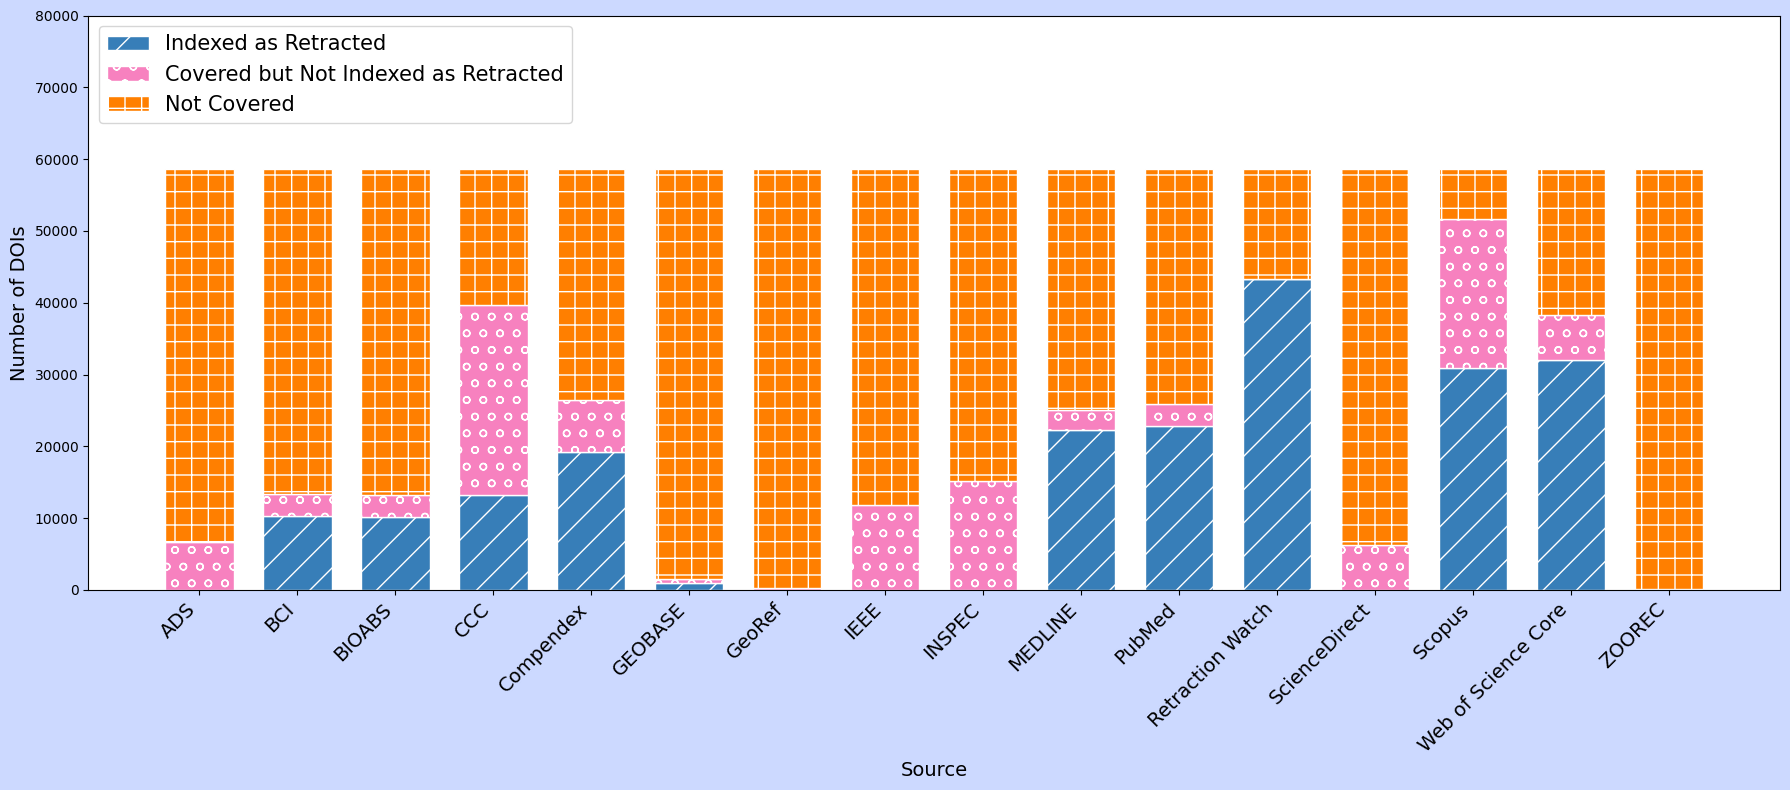

In [32]:
"""
Overall Plot of "Indexed as Retracted", "Covered but Not Indexed as Retracted", "Not Covered"
"""

fig0, ax0 = plt.subplots(figsize=(18, 8))

table = overview_RIA_source.copy()

# Define data for plotting
x = np.arange(len(table['Source']))
y1 = table['Indexed_as_retracted']
y2 = table['Covered_notindexed']
y3 = table['Not_coveredinUnionlist']

# Set the width of the bars
bar_width = 0.7

# Set the positions of the bars on the x-axis
r1 = np.arange(len(table['Source']))

# Plot the bars for Group1
plt.bar(r1, y1, color='#377eb8', hatch='/', width=bar_width, edgecolor='white', label='Indexed as Retracted')

# Plot the bars for Group2 on top of Group1
plt.bar(r1, y2, bottom=y1, color='#f781bf', hatch='o', width=bar_width, edgecolor='white', label='Covered but Not Indexed as Retracted')

# Plot the bars for Group3 on top of Group1 and Group2
plt.bar(r1, y3, bottom=y1 + y2, color='#ff7f00', hatch='+', width=bar_width, edgecolor='white', label='Not Covered')

# Axis labels
sources_adjusted = all_sources

plt.xticks(r1, sources_adjusted, rotation=45, ha="right")  # Rotate labels for better visibility
plt.xlabel("Source", fontsize=14)
plt.ylabel("Number of DOIs", fontsize=14)

ax0.tick_params(axis='x', labelsize=14)

plt.legend(["Indexed as Retracted", "Covered but Not Indexed as Retracted", "Not Covered"],fontsize=15, loc='upper left')

fig0.patch.set_facecolor('#ccd9ff')  # Set the background color of the figure

ax0.set_yticks(range(0, 90000, 10000)) #70900

# Show the plot
plt.tight_layout()
# plt.show()

# Save result to folder
plt.savefig(result_dir+'recordsineachsource.png')


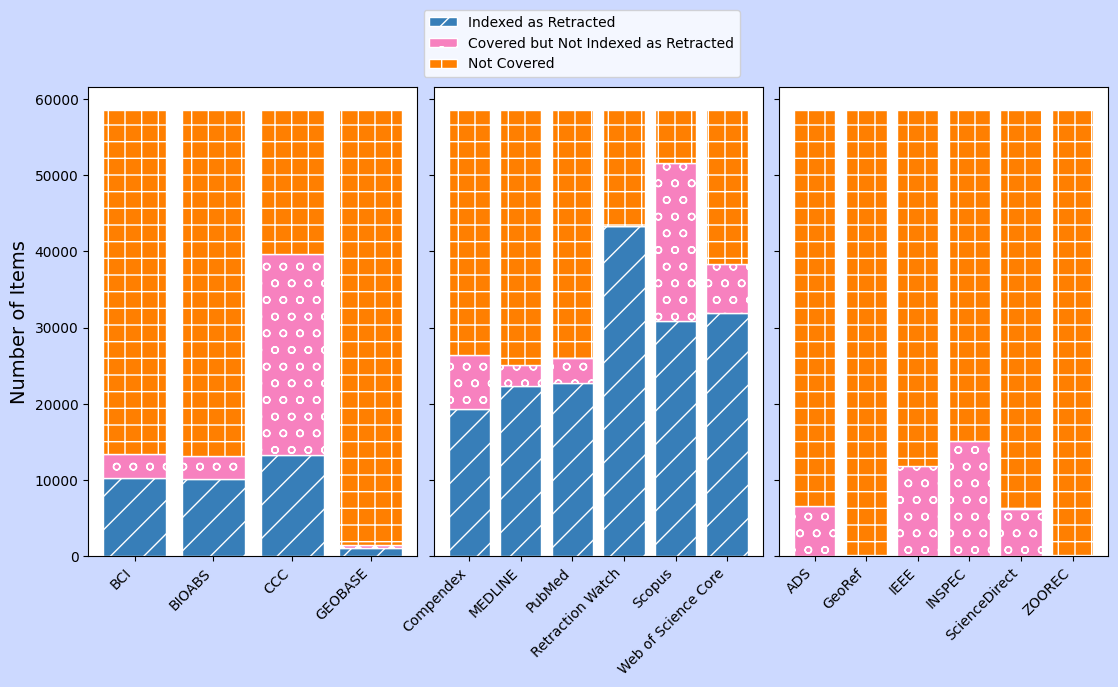

In [33]:
"""
Subplot: Overall Plot of "Indexed as Retracted", "Covered but Not Indexed as Retracted", "Not Covered"
"""

fig0_1, ax0_1 = plt.subplots(1, 3, figsize=(12, 7), sharey=True)
fig0_1.subplots_adjust(hspace=0.5, wspace=0.05) # Space between charts

# Set the width of the bars
bar_width = 0.8


# First Subplot
table001 = overview_RIA_source_2_1.copy()

# Set the positions of the bars on the x-axis
r1_0 = np.arange(len(table001['Source']))

# Define data for plotting
y1_0 = table001['Indexed_as_retracted']
y2_0 = table001['Covered_notindexed']
y3_0 = table001['Not_coveredinUnionlist']

ax0_1[0].bar(r1_0, y1_0, color='#377eb8', hatch='/', width=bar_width, edgecolor='white', label='Indexed as Retracted')
ax0_1[0].bar(r1_0, y2_0, bottom=y1_0, color='#f781bf', hatch='o', width=bar_width, edgecolor='white', label='Covered but Not Indexed as Retracted')
ax0_1[0].bar(r1_0, y3_0, bottom=y1_0 + y2_0, color='#ff7f00', hatch='+', width=bar_width, edgecolor='white', label='Not Covered')

# Set x-axis ticks with labels from 'Source' column
ax0_1[0].set_xticks(r1_0)
ax0_1[0].set_xticklabels(table001['Source'], rotation=45, ha="right")


# Second Subplot
table002 = overview_RIA_source_2_2.copy()
r1_1 = np.arange(len(table002['Source']))

# Define data for plotting
y1_1 = table002['Indexed_as_retracted']
y2_1 = table002['Covered_notindexed']
y3_1 = table002['Not_coveredinUnionlist']

ax0_1[1].bar(r1_1, y1_1, color='#377eb8', hatch='/', width=bar_width, edgecolor='white', label='Indexed as Retracted')
ax0_1[1].bar(r1_1, y2_1, bottom=y1_1, color='#f781bf', hatch='o', width=bar_width, edgecolor='white', label='Covered but Not Indexed as Retracted')
ax0_1[1].bar(r1_1, y3_1, bottom=y1_1 + y2_1, color='#ff7f00', hatch='+', width=bar_width, edgecolor='white', label='Not Covered')

# Set x-axis ticks with labels from 'Source' column
ax0_1[1].set_xticks(r1_1)
ax0_1[1].set_xticklabels(table002['Source'], rotation=45, ha="right")


# Third Subplot
table003 = overview_RIA_source.iloc[[0,6,7,8,12,15],:].copy()
r1_2 = np.arange(len(table003['Source']))

# Define data for plotting
y1_2 = table003['Indexed_as_retracted']
y2_2 = table003['Covered_notindexed']
y3_2 = table003['Not_coveredinUnionlist']

ax0_1[2].bar(r1_2, y1_2, color='#377eb8', hatch='/', width=bar_width, edgecolor='white', label='Indexed as Retracted')
ax0_1[2].bar(r1_2, y2_2, bottom=y1_2, color='#f781bf', hatch='o', width=bar_width, edgecolor='white', label='Covered but Not Indexed as Retracted')
ax0_1[2].bar(r1_2, y3_2, bottom=y1_2 + y2_2, color='#ff7f00', hatch='+', width=bar_width, edgecolor='white', label='Not Covered')

# Set x-axis ticks with labels from 'Source' column
ax0_1[2].set_xticks(r1_2)
ax0_1[2].set_xticklabels(table003['Source'], rotation=45, ha="right")

fig0_1.patch.set_facecolor('#ccd9ff')

ax0_1[0].set_ylabel("Number of Items", fontsize=14)
plt.subplots_adjust(left=0.1, right=.95, top=0.87, bottom=0.2) #top=0.95

# Change outline colors
axes = [ax0_1[0], ax0_1[1], ax0_1[2]]
for ax in axes:
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_visible(True)


# Add legend above the graphs at the center
plt.legend(["Indexed as Retracted", "Covered but Not Indexed as Retracted", "Not Covered"], fontsize=10, loc='upper center', bbox_to_anchor=(-0.6, 1.18), ncol=1)
# Save result to folder
plt.savefig(result_dir+'recordsineachsource_subplot.png')
plt.show()



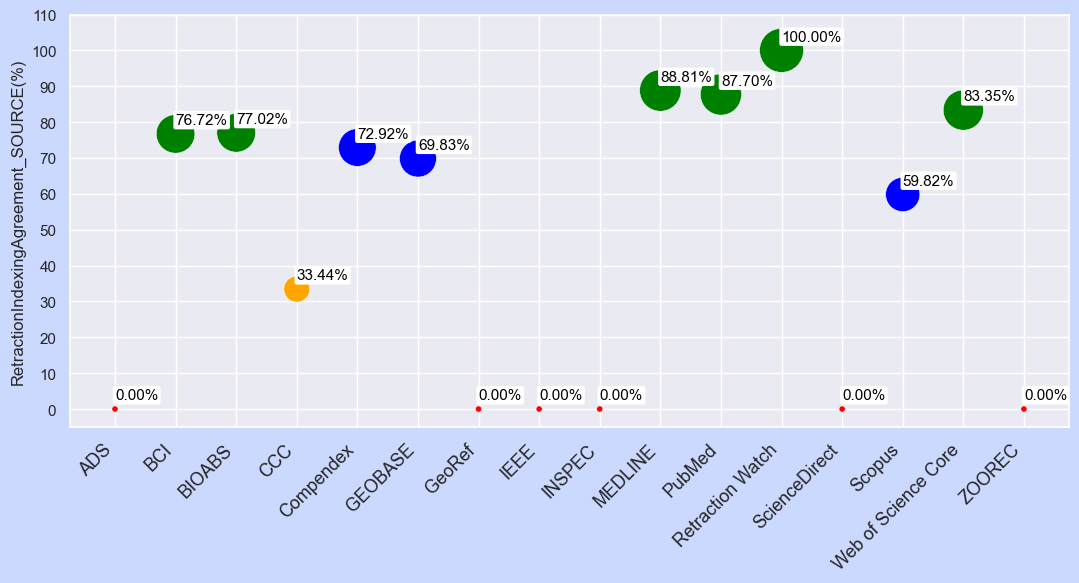

In [34]:
"""
Retraction Indexing Agreement Score by Source 
"""

sns.set_theme()
fig01_1, ax01_1 = plt.subplots(figsize=(11, 6))

cmap01_1 = {
    'red': 25,
    'orange': 50,
    'blue': 75,
    'green': 100}

def get_color(value):
    for color, threshold in cmap01_1.items():
        if value <= threshold:
            return color

# Use the colormap to assign colors based on the percentages
overview_RIA_source['Color'] = overview_RIA_source['RetractionIndexingAgreement_SOURCE(%)'].apply(get_color)

# Assigning color to Sources
mycolor_01_1 = dict(zip(overview_RIA_source['Source'], overview_RIA_source['Color']))

overview_RIA_source.drop(['Color'],axis=1, inplace=True)

sns.scatterplot(data=overview_RIA_source, x="Source", y="RetractionIndexingAgreement_SOURCE(%)", hue="Source",
                palette=mycolor_01_1,
                size="RetractionIndexingAgreement_SOURCE(%)", legend=False, sizes=(20, 1000), ax=ax01_1)

ax01_1.set_yticks(range(0, 115, 10))
fig01_1.patch.set_facecolor('#ccd9ff')  # Set the background color of the figure
# ax01_1.set_title('Source RetractionIndexingAgreement Score', size=15)
plt.xticks(rotation=45, ha="right")  # Rotate labels for better visibility

# plt.xlabel("Source", fontsize=14)

ax01_1.tick_params(axis='x', labelsize=13)
plt.xlabel("Source", fontsize=14)


# Annotate points with percentages and add a background
for i, point in enumerate(overview_RIA_source.iterrows()):
    x = point[1]["Source"]
    y = point[1]["RetractionIndexingAgreement_SOURCE(%)"]
    label = f"{y:.2f}%"  # Format percentage label
    plt.annotate(label, (x, y), textcoords="offset points", xytext=(0, 7), ha='left', fontsize=11, color='black',
                 bbox=dict(facecolor='white', edgecolor='white', boxstyle='round,pad=0.1'))
    
fig01_1.patch.set_facecolor('#ccd9ff')

# Remove 'Source Label'
ax01_1.set_xlabel('') 

plt.tight_layout()
# Save results to folder
plt.savefig(result_dir+'ria_scores_colored1.png')
plt.show()



In [35]:
overview_RIA_source.iloc[[1,2,3,4,5,9,10,13,14],:]

,Source,Indexed_as_retracted,Covered_notindexed,Not_coveredinUnionlist,RetractionIndexingAgreement_SOURCE(%)
1,BCI,10294,3123,45179,76.72
2,BIOABS,10166,3034,45396,77.02
3,CCC,13257,26384,18955,33.44
4,Compendex,19266,7155,32175,72.92
5,GEOBASE,1039,449,57108,69.83
9,MEDLINE,22304,2809,33483,88.81
10,PubMed,22766,3193,32637,87.70
13,Scopus,30888,20743,6965,59.82
14,Web of Science Core,31959,6386,20251,83.35


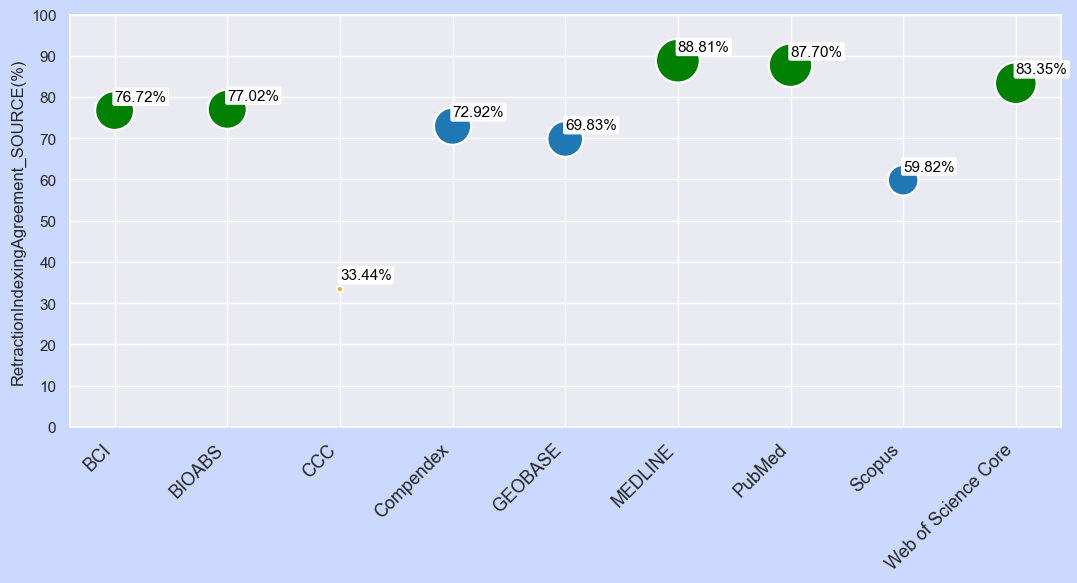

In [36]:
"""
Retraction Indexing Agreement Score by source (excluding non-indexed source only & Retraction Watch )
"""

# Selecting source that indexed retracted publication only (excluding RetractionWatch)
overview_RIA_source_2= overview_RIA_source.iloc[[1,2,3,4,5,9,10,13,14],:].copy()

sns.set_theme()
fig01_2, ax01_2 = plt.subplots(figsize=(11, 6))

cmap01_1 = {
    'red': 25,
    'orange': 50,
    '#1f77b4': 75,
    'green': 100}

def get_color(value):
    for color, threshold in cmap01_1.items():
        if value <= threshold:
            return color

# Use the colormap to assign colors based on the percentages
overview_RIA_source_2['Color'] = overview_RIA_source_2['RetractionIndexingAgreement_SOURCE(%)'].apply(get_color)

# Assigning color to Sources
mycolor_01_1 = dict(zip(overview_RIA_source_2['Source'], overview_RIA_source_2['Color']))

overview_RIA_source_2.drop(['Color'],axis=1, inplace=True)

sns.scatterplot(data=overview_RIA_source_2, x="Source", y="RetractionIndexingAgreement_SOURCE(%)", hue="Source",
                palette=mycolor_01_1,
                size="RetractionIndexingAgreement_SOURCE(%)", legend=False, sizes=(20, 1000), ax=ax01_2)

ax01_2.set_yticks(range(0, 105, 10))
fig01_2.patch.set_facecolor('#ccd9ff')  # Set the background color of the figure
# ax01_2.set_title('Source RetractionIndexingAgreement Score', size=15)
plt.xticks(rotation=45, ha="right")  # Rotate labels for better visibility

# plt.xlabel("Source", fontsize=14)

ax01_2.tick_params(axis='x', labelsize=13)
plt.xlabel("Source", fontsize=14)


# Annotate points with percentages and add a background
for i, point in enumerate(overview_RIA_source.iterrows()):
    x = point[1]["Source"]
    y = point[1]["RetractionIndexingAgreement_SOURCE(%)"]
    label = f"{y:.2f}%"  # Format percentage label
    plt.annotate(label, (x, y), textcoords="offset points", xytext=(0, 7), ha='left', fontsize=11, color='black',
                 bbox=dict(facecolor='white', edgecolor='white', boxstyle='round,pad=0.1'))

    
fig01_2.patch.set_facecolor('#ccd9ff')

# Remove 'Source Label'
ax01_2.set_xlabel('') 

plt.tight_layout() 

# Save results to folder
plt.savefig(result_dir+'ria_scores_colored2.png')
plt.show()



### 2.3  Exclusive Retracted Items Indexing Across Sources

In [37]:
sources_indexed

['BCI',
 'BIOABS',
 'CCC',
 'Compendex',
 'GEOBASE',
 'Medline',
 'PubMed',
 'Retraction Watch',
 'Scopus',
 'WoS_Core']

In [38]:
# Pre-compute indexed sets for all sources
indexed_sets = {
    s: set(unionlist3_adjusted[unionlist3_adjusted['source_old'].str.contains(s)]['DOI'])
    for s in sources_indexed
}
indexed_sets

{'BCI': {'10.1111/jcmm.14644',
  '10.1213/ane.0b013e31817b7732',
  '10.3892/etm.2017.4602',
  '10.2131/jts.42.233',
  '10.1016/j.plantsci.2010.06.015',
  '10.1093/cvr/cvac157.038',
  '10.1097/md.0000000000007072',
  '10.1538/expanim.55.349',
  '10.2147/ott.s118391',
  '10.1159/000099177',
  '10.1155/2022/7850659',
  '10.1016/j.lfs.2022.120906',
  '10.1016/j.toxlet.2013.03.001',
  '10.4238/vol9-1gmr758',
  '10.1186/s12935-019-1076-7',
  '10.1007/s10549-008-0009-2',
  '10.3233/cbm-170732',
  '10.1080/10408410802383610',
  '10.1155/2018/1096079',
  '10.1007/s13277-013-0995-5',
  '10.1016/j.ecocom.2018.10.002',
  '10.1016/j.brainresbull.2009.05.018',
  '10.1155/2022/7348344',
  '10.3760/cma.j.issn.0366-6999.20132144',
  '10.1007/s13197-022-05460-x',
  '10.1186/s12974-020-1725-8',
  '10.3727/096504017x15140544654946',
  '10.1016/j.rvsc.2017.03.019',
  '10.1139/bcb-2016-0232',
  '10.1371/journal.pone.0113401',
  '10.3389/fenvs.2022.919413',
  '10.1016/j.cell.2010.09.011',
  '10.1155/2022/967

In [39]:
exclusive = []
for source in sources_indexed:
    others = set().union(*[v for k, v in indexed_sets.items() if k != source])
    exclusive_dois = indexed_sets[source] - others  # only this source has these
    exclusive.append({
        'source': source,
        'total_indexed': len(indexed_sets[source]),
        'exclusive_n': len(exclusive_dois),
        'exclusive_pct': round(len(exclusive_dois) / len(indexed_sets[source]) * 100, 2) if indexed_sets[source] else 0
        
    })

df_excl = pd.DataFrame(exclusive).sort_values('exclusive_n', ascending=True)
df_excl = df_excl.replace({'WoS_Core':'Web of Science Core', 'Medline':'MEDLINE'})

In [40]:
df_excl

,source,total_indexed,exclusive_n,exclusive_pct
0,BCI,10294,0,0.00
1,BIOABS,10166,0,0.00
2,CCC,13257,3,0.02
4,GEOBASE,1039,5,0.48
5,MEDLINE,22304,8,0.04
3,Compendex,19266,523,2.71
6,PubMed,22766,655,2.88
9,Web of Science Core,31959,1282,4.01
8,Scopus,30888,2080,6.73
7,Retraction Watch,43311,6750,15.58


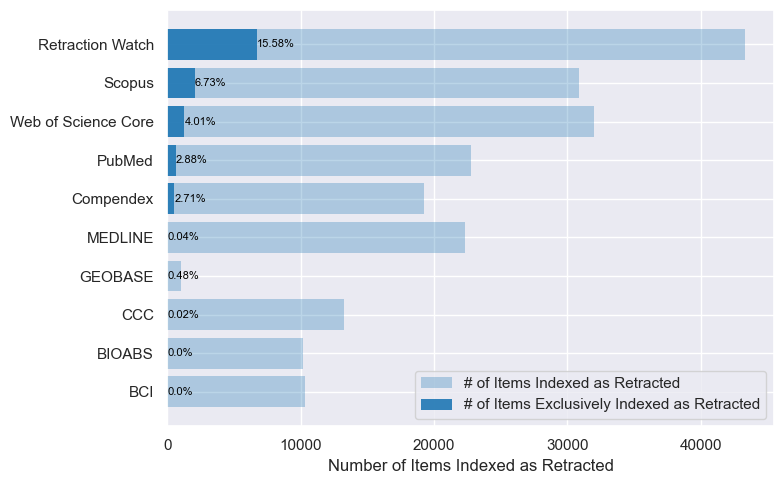

In [41]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(df_excl.source, df_excl.total_indexed, color='#1f77b4', alpha=0.3, label='# of Items Indexed as Retracted',
        edgecolor='none')
ax.barh(df_excl.source, df_excl.exclusive_n, color='#1f77b4', alpha=0.9, label='# of Items Exclusively Indexed as Retracted',
        edgecolor='none')

for _, row in df_excl.iterrows():
    ax.text(row.exclusive_n + 1, row.source, f"{row.exclusive_pct}%",
            va='center', fontsize=8, color='black') #color='#1a9850'

ax.set_xlabel('Number of Items Indexed as Retracted')
# ax.set_title('Items Indexed As Retracted By Only One Source')
ax.legend(loc='lower right')

plt.savefig(result_dir+"exclusively_indexed_items_per_source.png", dpi=300,bbox_inches="tight")
plt.tight_layout()
plt.show()

### 2.4  Pairwise Calculation of RetractionIndexAgreement Between Two Sources

In [42]:
"""
Calculating pairwise RetractionIndexAgreement between two sources
(i) Pair up sources to check their pairwise RetractionIndexAgreement -> unique_pairs
(ii) Calculating pairwise RetractionIndexAgreement 
"""

from itertools import combinations

sources_indexed = ['BCI', 'BIOABS', 'CCC', 'Compendex', 'GEOBASE', 'Medline',
                   'PubMed', 'Retraction Watch', 'Scopus', 'WoS_Core']

pairswise2_RIA_Scores = []

for source1, source2 in combinations(sources_indexed, 2):

    source1_covered = set(unionlist3_adjusted[unionlist3_adjusted['source_new'].str.contains(source1)]['DOI'])
    source2_covered = set(unionlist3_adjusted[unionlist3_adjusted['source_new'].str.contains(source2)]['DOI'])

    source1_indexed = set(unionlist3_adjusted[unionlist3_adjusted['source_old'].str.contains(source1)]['DOI'])
    source2_indexed = set(unionlist3_adjusted[unionlist3_adjusted['source_old'].str.contains(source2)]['DOI'])

    joint_covered = source1_covered & source2_covered
    pairwise_covered = len(joint_covered)
    pairwise_indexed = len(source1_indexed & source2_indexed)

    # How much each source indexes within jointly covered papers
    s1_indexed_pairwise_cov = source1_indexed & joint_covered
    s2_indexed_pairwise_cov = source2_indexed & joint_covered

    s1_in_pairwise_covered = len(s1_indexed_pairwise_cov)
    s2_in_pairwise_covered = len(s2_indexed_pairwise_cov)

    ## items covered by both, indexed-as-retracted by s2 only (s1 did not flag) and vice versa
    s1_not_indexed_but_s2  = len(s2_indexed_pairwise_cov - s1_indexed_pairwise_cov) # 
    s2_not_indexed_but_s1 = len(s1_indexed_pairwise_cov - s2_indexed_pairwise_cov)

    ## Total disagreed not indexed in both sources
    total_disagrement = s1_not_indexed_but_s2 + s2_not_indexed_but_s1

    ## Coverage rate
    s1_coverage_rate = (s1_in_pairwise_covered / pairwise_covered * 100) if pairwise_covered > 0 else 0
    s2_coverage_rate = (s2_in_pairwise_covered / pairwise_covered * 100) if pairwise_covered > 0 else 0

    # Direction and size of gap
    
    indexingAgreement_score = round((pairwise_indexed / pairwise_covered) * 100, 2) if pairwise_covered > 0 else 0

    pairswise2_RIA_Scores.append([
        source1, source2, pairwise_indexed, pairwise_covered, indexingAgreement_score,
        s1_not_indexed_but_s2, s2_not_indexed_but_s1, total_disagrement, 
        s1_coverage_rate, s2_coverage_rate
    ])


df_pairwise2_ria = pd.DataFrame(pairswise2_RIA_Scores, 
                  columns=['source1','source2','pairwise_indexed','pairwise_covered',
                           'RetractionIndexingAgreement_SOURCE(%)','s1_not_indexed_but_s2','s2_not_indexed_but_s1',
                           'total_disagreement','s1_coverage_rate','s2_coverage_rate'])

df_pairwise2_ria.replace({'WoS_Core': 'Web of Science Core',
                         'Medline': 'MEDLINE'}, inplace=True)


df_pairwise2_ria = df_pairwise2_ria.round(2)

In [43]:
df_pairwise2_ria.to_csv(result_dir+'pairwise_ria_score_sources_data.csv')
df_pairwise2_ria

,source1,source2,pairwise_indexed,pairwise_covered,RetractionIndexingAgreement_SOURCE(%),s1_not_indexed_but_s2,s2_not_indexed_but_s1,total_disagreement,s1_coverage_rate,s2_coverage_rate
0,BCI,BIOABS,10150,13180,77.01,15,9,24,77.08,77.12
1,BCI,CCC,6010,13056,46.03,903,4034,4937,76.93,52.95
2,BCI,Compendex,570,1407,40.51,261,389,650,68.16,59.06
3,BCI,GEOBASE,227,594,38.22,125,199,324,71.72,59.26
4,BCI,MEDLINE,9210,12416,74.18,2096,500,2596,78.21,91.06
5,BCI,PubMed,9097,12386,73.45,2083,619,2702,78.44,90.26
6,BCI,Retraction Watch,9218,11267,81.81,2049,0,2049,81.81,100.00
7,BCI,Scopus,5860,12976,45.16,1311,4214,5525,77.64,55.26
8,BCI,Web of Science Core,10266,13270,77.36,1177,1,1178,77.37,86.23
9,BIOABS,CCC,5966,12849,46.43,890,3957,4847,77.23,53.36


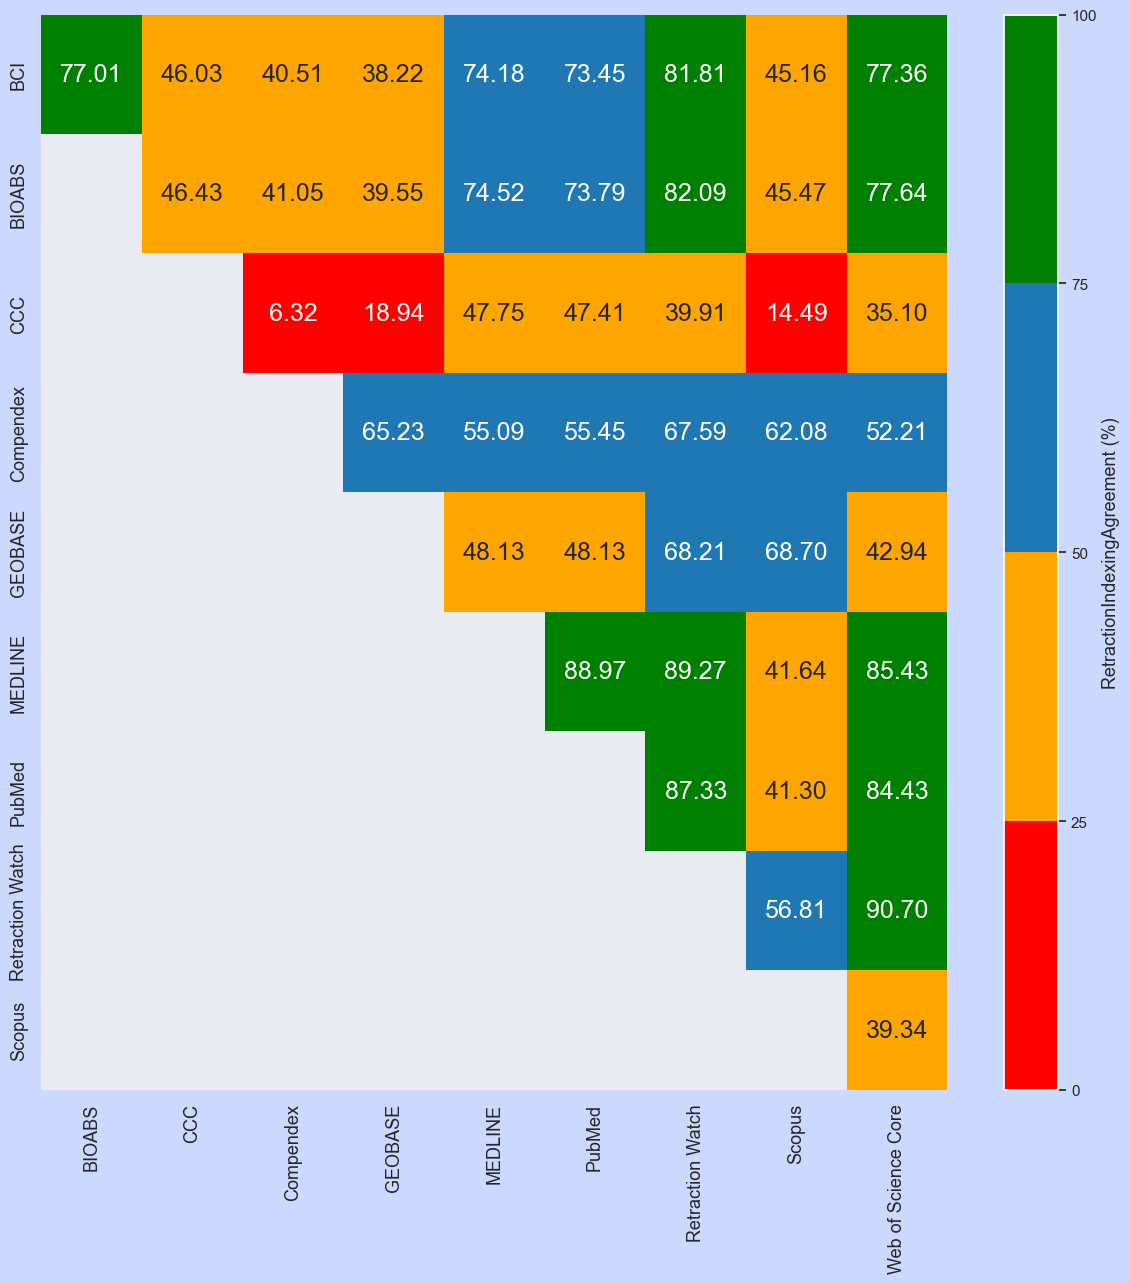

In [44]:
"""
HeatMap for Pairwise Retraction Indexing Agreement Between Pair Sources
"""
pairwise_ria= df_pairwise2_ria[['source1','source2','RetractionIndexingAgreement_SOURCE(%)']].copy()

from matplotlib.colors import ListedColormap
# Assuming pairwise_ria has the required data

heatmap_data = pairwise_ria.pivot(index='source1', columns='source2', values='RetractionIndexingAgreement_SOURCE(%)')

# Create a figure and axis
fig02, ax02 = plt.subplots(figsize=(12, 13))

cmap = ListedColormap(['red', 'orange', '#1f77b4', 'green'])

# Create the heatmap using Seaborn and the ax object
cax = sns.heatmap(heatmap_data, annot=True, cmap=cmap, fmt='.2f', linewidths=0.0, vmin=0, vmax=100, 
                  ax=ax02, annot_kws={"size": 18})

# Set labels and title
ax02.set_xlabel('')
ax02.set_ylabel('')

# ax02.set_title('Pairwise RetractionIndexingAgreement Between Sources', size=15)

# Set the font size of x-axis and y-axis labels
ax02.tick_params(axis='x', labelsize=13)  # Font size for x-axis labels
ax02.tick_params(axis='y', labelsize=13)  # Font size for y-axis labels

# Hide the default color bar
cax.collections[0].colorbar.remove()

# Show the colorbar and set its label
cbar = cax.figure.colorbar(cax.collections[0], ax=ax02, ticks=[0, 25, 50, 75, 100])
cbar.set_label('RetractionIndexingAgreement (%)',fontsize= 13)

# Set the background color of the figure
fig02.patch.set_facecolor('#ccd9ff')

plt.subplots_adjust(left=0.05, right=1.05, top=0.95, bottom=0.05)  # Remove space outside the plot

ax02.grid(False)

plt.tight_layout() 

# Save to folder
plt.savefig(result_dir+'pairwise_RetractionIndexingAgreement_sources.png')

plt.show()


In [45]:
df_pairwise2_ria

,source1,source2,pairwise_indexed,pairwise_covered,RetractionIndexingAgreement_SOURCE(%),s1_not_indexed_but_s2,s2_not_indexed_but_s1,total_disagreement,s1_coverage_rate,s2_coverage_rate
0,BCI,BIOABS,10150,13180,77.01,15,9,24,77.08,77.12
1,BCI,CCC,6010,13056,46.03,903,4034,4937,76.93,52.95
2,BCI,Compendex,570,1407,40.51,261,389,650,68.16,59.06
3,BCI,GEOBASE,227,594,38.22,125,199,324,71.72,59.26
4,BCI,MEDLINE,9210,12416,74.18,2096,500,2596,78.21,91.06
5,BCI,PubMed,9097,12386,73.45,2083,619,2702,78.44,90.26
6,BCI,Retraction Watch,9218,11267,81.81,2049,0,2049,81.81,100.00
7,BCI,Scopus,5860,12976,45.16,1311,4214,5525,77.64,55.26
8,BCI,Web of Science Core,10266,13270,77.36,1177,1,1178,77.37,86.23
9,BIOABS,CCC,5966,12849,46.43,890,3957,4847,77.23,53.36


In [46]:
!pip install adjustText

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


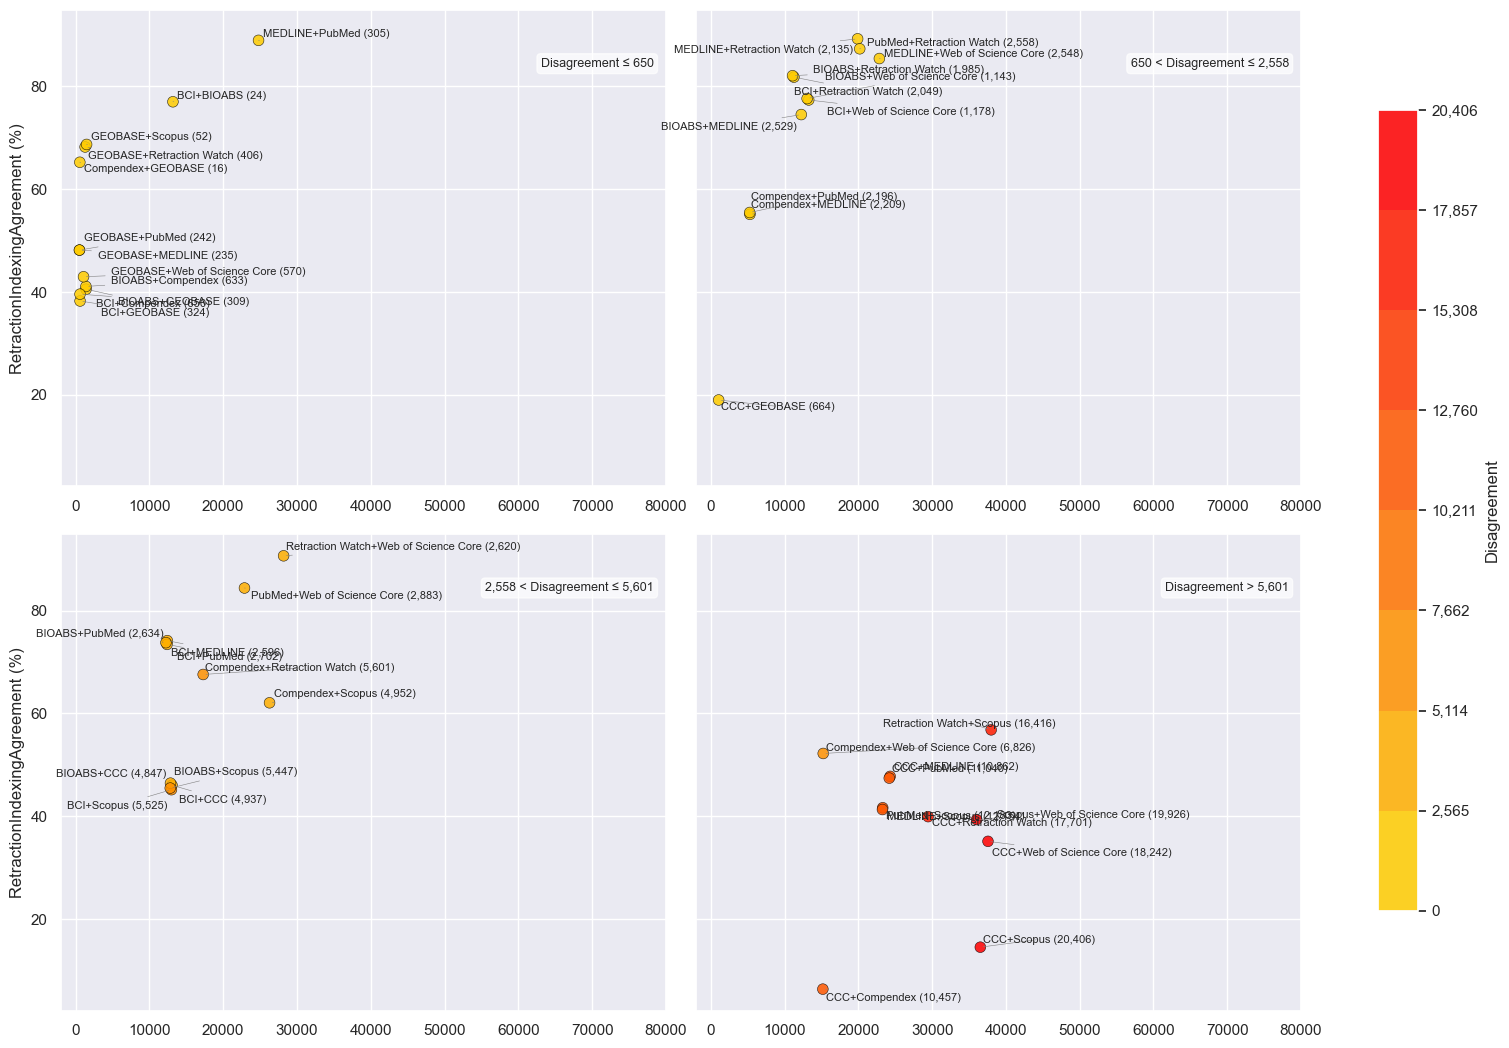

In [47]:
### ADJUSTING ---USE THIS
sns.set_style("darkgrid")
from matplotlib.colors import ListedColormap, BoundaryNorm, LinearSegmentedColormap
import numpy as np
from adjustText import adjust_text

def truncate_colormap(cmap, minval=0.0, maxval=1.0, n=100):
    if isinstance(cmap, str):
        cmap = plt.get_cmap(cmap)
    return LinearSegmentedColormap.from_list(
        f'trunc({cmap.name},{minval:.2f},{maxval:.2f})',
        cmap(np.linspace(minval, maxval, n)))


q25 = df_pairwise2_ria['total_disagreement'].quantile(0.25)
q50 = df_pairwise2_ria['total_disagreement'].quantile(0.50)
q75 = df_pairwise2_ria['total_disagreement'].quantile(0.75)

quartiles = [
    ('Disagreement ≤ {:,.0f}'.format(q25),                   df_pairwise2_ria[df_pairwise2_ria.total_disagreement <= q25]),
    ('{:,.0f} < Disagreement ≤ {:,.0f}'.format(q25, q50),   df_pairwise2_ria[(df_pairwise2_ria.total_disagreement > q25) & (df_pairwise2_ria.total_disagreement <= q50)]),
    ('{:,.0f} < Disagreement ≤ {:,.0f}'.format(q50, q75),   df_pairwise2_ria[(df_pairwise2_ria.total_disagreement > q50) & (df_pairwise2_ria.total_disagreement <= q75)]),
    ('Disagreement > {:,.0f}'.format(q75),                  df_pairwise2_ria[df_pairwise2_ria.total_disagreement > q75]),
]

manual_offsets = {
    # 'Source1+Source2': (dx, dy),
    "Compendex+GEOBASE": (3,-1),
    "GEOBASE+Scopus": (3,2), "GEOBASE+MEDLINE": (13,-0.2),"GEOBASE+PubMed": (3,5),
    "GEOBASE+Web of Science Core": (20,0.125),
    "BIOABS+GEOBASE": (27,-2),
    "BCI+GEOBASE": (15,-5),  "BCI+Compendex": (7,-7), "BCI+BIOABS": (3,1),
    "Crossref+GEOBASE": (3,2),
    "CCC+GEOBASE": (1.5,-1),
    "BIOABS+Compendex": (18,0.75),
    "PubMed+Web of Science Core": (-2,1),
    "MEDLINE+Web of Science Core": (3,0),

    # Q2
    "BIOABS+Retraction Watch": (15,0.5),
    "MEDLINE+PubMed": (3,1),"MEDLINE+Retraction Watch": (-3,-4),
    "BCI+Retraction Watch": (0.02,-7),
    "PubMed+Retraction Watch": (5,1),
    "Compendex+PubMed": (1,8),
    "Compendex+MEDLINE": (1,3),
    "BCI+Web of Science Core": (13,-5),
    "BIOABS+Web of Science Core": (13,12),
    "PubMed+Web of Science Core": (5,-2),
    "BCI+PubMed": (7,-5),
    "BIOABS+PubMed": (-2,3),

    # Q3
    "BIOABS+CCC": (-3,3),
    "BCI+CCC": (5,-7),
    "GEOBASE+Retraction Watch": (2,-3),
    "MEDLINE+Scopus": (3,-3),
    "Compendex+Web of Science Core": (2,0.8), "Compendex+Scopus": (3,3),
    "PubMed+Scopus": (2.5,-1), 

    "BIOABS+MEDLINE": (-3,-5),
    "Compendex+Retraction Watch": (1,1),
    "BCI+MEDLINE": (3,-5),
    "Crossref+MEDLINE": (2,0),
    "BIOABS+Scopus": (3,8),
    "BCI+Scopus": (-3,-8),
    "Retraction Watch+Web of Science Core": (2,3),
    "CCC+Crossref": (2,-1), "CCC+Scopus": (2,2),

    # Q4
    "BIOABS+Crossref": (-1,5),
    "BCI+Crossref": (-5,-3),
    "Scopus+Web of Science Core": (15,0),
    "CCC+PubMed": (2,3),"CCC+Web of Science Core": (3,-5), "CCC+Retraction Watch": (3,-1),
    "CCC+Compendex": (2,-3),"CCC+MEDLINE": (3,3),
    "Crossref+Scopus": (-0.2,-3),"Crossref+Web of Science Core": (0.2,3),"Crossref+Retraction Watch": (0.2,3),
    "Compendex+Crossref": (-1,-3),
}

fig, axes = plt.subplots(2, 2, figsize=(20, 13), sharex=True, sharey=True,
                         gridspec_kw={'wspace': 0.05, 'hspace': 0.1})
axes = axes.flatten()

vmin, vmax = df_pairwise2_ria.total_disagreement.min(), df_pairwise2_ria.total_disagreement.max()

# ---- Discrete cmap built from a truncated continuous one (drops pale yellow low end).
n_bins = 8
base_cmap = truncate_colormap('autumn_r', 0.2, 1.0)            # try 'plasma', 'magma', 'YlOrRd_r' too
cmap = ListedColormap(base_cmap(np.linspace(0, 1, n_bins)))    # sample n_bins colors from it
boundaries = np.linspace(vmin, vmax, n_bins + 1)
norm = BoundaryNorm(boundaries, ncolors=n_bins)

for i, (ax, (title, subset)) in enumerate(zip(axes, quartiles)):
    
    if i % 2 == 0:
        ax.set_ylabel('RetractionIndexingAgreement (%)')
        ax.yaxis.set_label_position('left')
        ax.tick_params(labelright=False, labelleft=True)

    sc = ax.scatter(subset.pairwise_covered, subset['RetractionIndexingAgreement_SOURCE(%)'],
                    c=subset.total_disagreement, cmap=cmap, norm=norm,
                    s=60, alpha=0.85,
                    edgecolor='black', linewidth=0.4)
    

    auto_texts = []
    auto_texts = []
    for _, row in subset.iterrows():
        key   = f"{row.source1}+{row.source2}"
        label = f"{key} ({row.total_disagreement:,.0f})"          # one-line label
        # label = f"{key}\n({row.total_disagreement:,.0f})"       # ...or two-line label

        if key in manual_offsets:
            dx, dy = manual_offsets[key]
            ha = 'left' if dx >= 0 else 'right'
            va = 'bottom' if dy >= 0 else 'top'
            ax.annotate(
                label,
                xy=(row.pairwise_covered, row['RetractionIndexingAgreement_SOURCE(%)']),
                xytext=(dx, dy), textcoords='offset points',
                fontsize=8, ha=ha, va=va,
                arrowprops=dict(arrowstyle='-', color='gray', lw=0.4),
            )
        else:
            auto_texts.append(
                ax.text(row.pairwise_covered, row['RetractionIndexingAgreement_SOURCE(%)'], label, fontsize=8)
            )

    adjust_text(auto_texts, ax=ax,
                arrowprops=dict(arrowstyle='-', color='gray', lw=0.4),
                expand_points=(1.5, 1.5),
                expand_text=(1.2, 1.4))

    ax.text(0.98, 0.90,
            f'{title}',
            transform=ax.transAxes,
            fontsize=9, va='top', ha='right',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

for ax in axes:
    ax.tick_params(labelbottom=True)
    ax.set_xlim(-2000, 80000)
    # ax.set_xlabel('Co-covered items (# DOIs)')


cbar = fig.colorbar(sc, ax=axes.tolist(), label='Disagreement', shrink=0.8,
                    ticks=boundaries, spacing='uniform')
cbar.ax.set_yticklabels(['0'] + [f'{b:,.0f}' for b in boundaries[1:]])

# fig.suptitle('Coverage vs Agreement, by Disagreement Quartile', fontsize=13, y=0.90)
plt.savefig(result_dir+"pairswise_RIA_Scores_in_quartiles.png", dpi=300,bbox_inches="tight")
plt.show()

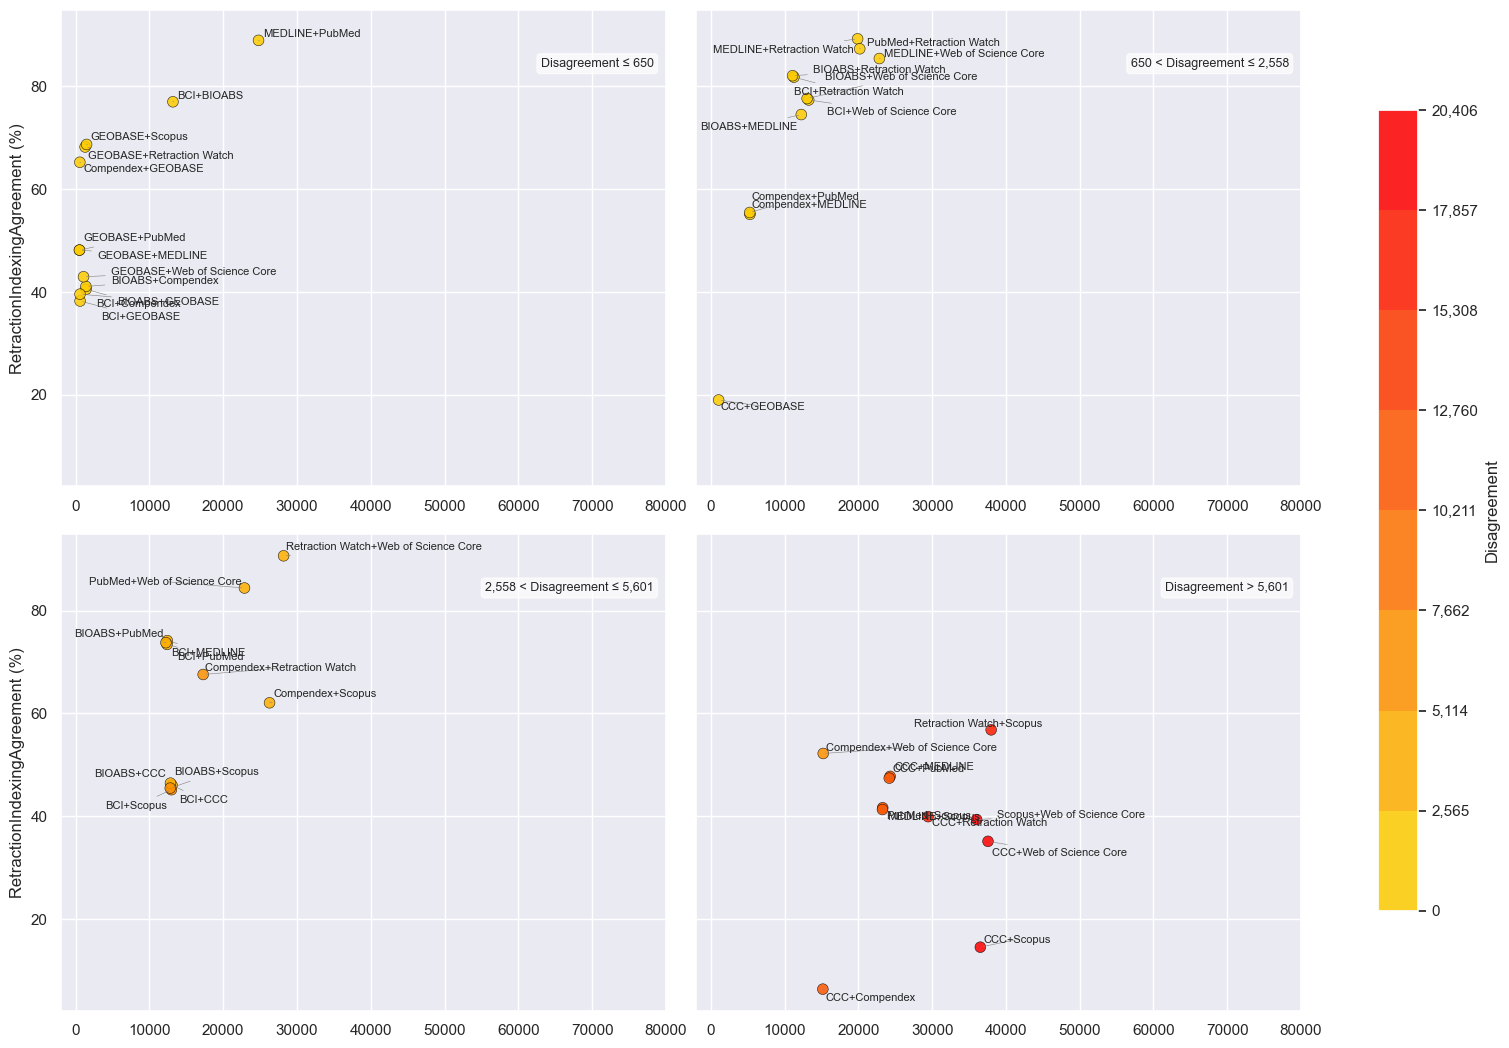

In [48]:
### ADJUSTING ---USE THIS
sns.set_style("darkgrid")
from matplotlib.colors import ListedColormap, BoundaryNorm, LinearSegmentedColormap
import numpy as np
from adjustText import adjust_text

def truncate_colormap(cmap, minval=0.0, maxval=1.0, n=100):
    if isinstance(cmap, str):
        cmap = plt.get_cmap(cmap)
    return LinearSegmentedColormap.from_list(
        f'trunc({cmap.name},{minval:.2f},{maxval:.2f})',
        cmap(np.linspace(minval, maxval, n)))


q25 = df_pairwise2_ria['total_disagreement'].quantile(0.25)
q50 = df_pairwise2_ria['total_disagreement'].quantile(0.50)
q75 = df_pairwise2_ria['total_disagreement'].quantile(0.75)

quartiles = [
    ('Disagreement ≤ {:,.0f}'.format(q25),                  df_pairwise2_ria[df_pairwise2_ria.total_disagreement <= q25]),
    ('{:,.0f} < Disagreement ≤ {:,.0f}'.format(q25, q50),   df_pairwise2_ria[(df_pairwise2_ria.total_disagreement > q25) & (df_pairwise2_ria.total_disagreement <= q50)]),
    ('{:,.0f} < Disagreement ≤ {:,.0f}'.format(q50, q75),   df_pairwise2_ria[(df_pairwise2_ria.total_disagreement > q50) & (df_pairwise2_ria.total_disagreement <= q75)]),
    ('Disagreement > {:,.0f}'.format(q75),                  df_pairwise2_ria[df_pairwise2_ria.total_disagreement > q75]),
]

manual_offsets = {
    # Q1
    "Compendex+GEOBASE": (3,-1),
    "GEOBASE+Scopus": (3,2), "GEOBASE+MEDLINE": (13,-0.2), "GEOBASE+PubMed": (3,5),
    "GEOBASE+Web of Science Core": (20,0.125),
    "BIOABS+GEOBASE": (27,-2),
    "BCI+GEOBASE": (15,-8),  "BCI+Compendex": (7,-7), "BCI+BIOABS": (3,1),
    "Crossref+GEOBASE": (3,2),
    "CCC+GEOBASE": (1.5,-1),
    "BIOABS+Compendex": (18,0.75),
    "PubMed+Web of Science Core": (-2,1),
    "MEDLINE+Web of Science Core": (3,0),

    # Q2
    "BIOABS+Retraction Watch": (15,0.5),
    "MEDLINE+PubMed": (3,1), "MEDLINE+Retraction Watch": (-3,-4),
    "BCI+Retraction Watch": (0.02,-7),
    "PubMed+Retraction Watch": (5,1),
    "Compendex+PubMed": (1,8),
    "Compendex+MEDLINE": (1,3),
    "BCI+Web of Science Core": (13,-5),
    "BIOABS+Web of Science Core": (13,12),
    "BCI+PubMed": (7,-5),
    "BIOABS+PubMed": (-2,3),

    # Q3
    "BIOABS+CCC": (-3,3),
    "BCI+CCC": (5,-7),
    "GEOBASE+Retraction Watch": (2,-3),
    "MEDLINE+Scopus": (3,-3),
    "Compendex+Web of Science Core": (2,0.8), "Compendex+Scopus": (3,3),
    "PubMed+Scopus": (2.5,-1),
    "BIOABS+MEDLINE": (-3,-5),
    "Compendex+Retraction Watch": (1,1),
    "BCI+MEDLINE": (3,-5),
    "Crossref+MEDLINE": (2,0),
    "BIOABS+Scopus": (3,8),
    "BCI+Scopus": (-3,-8),
    "Retraction Watch+Web of Science Core": (2,3),
    "CCC+Crossref": (2,-1), "CCC+Scopus": (2,2),

    # Q4
    "BIOABS+Crossref": (-1,5),
    "BCI+Crossref": (-5,-3),
    "Scopus+Web of Science Core": (15,0),
    "CCC+PubMed": (2,3), "CCC+Web of Science Core": (3,-5), "CCC+Retraction Watch": (3,-1),
    "CCC+Compendex": (2,-3), "CCC+MEDLINE": (3,3),
    "Crossref+Scopus": (-0.2,-3), "Crossref+Web of Science Core": (0.2,3), "Crossref+Retraction Watch": (0.2,3),
    "Compendex+Crossref": (-1,-3),
}

fig, axes = plt.subplots(2, 2, figsize=(20, 13), sharex=True, sharey=True,
                         gridspec_kw={'wspace': 0.05, 'hspace': 0.1})
axes = axes.flatten()

vmin, vmax = df_pairwise2_ria.total_disagreement.min(), df_pairwise2_ria.total_disagreement.max()

# ---- Discrete cmap built from a truncated continuous one (drops pale yellow low end).
n_bins = 8
base_cmap = truncate_colormap('autumn_r', 0.2, 1.0)
cmap = ListedColormap(base_cmap(np.linspace(0, 1, n_bins)))
boundaries = np.linspace(vmin, vmax, n_bins + 1)
norm = BoundaryNorm(boundaries, ncolors=n_bins)

for i, (ax, (title, subset)) in enumerate(zip(axes, quartiles)):

    if i % 2 == 0:
        ax.set_ylabel('RetractionIndexingAgreement (%)')
        ax.yaxis.set_label_position('left')
        ax.tick_params(labelright=False, labelleft=True)

    sc = ax.scatter(subset.pairwise_covered, subset['RetractionIndexingAgreement_SOURCE(%)'],
                    c=subset.total_disagreement, cmap=cmap, norm=norm,
                    s=60, alpha=0.85,
                    edgecolor='black', linewidth=0.4)

    auto_texts = []
    for _, row in subset.iterrows():
        key = f"{row.source1}+{row.source2}"

        if key in manual_offsets:
            dx, dy = manual_offsets[key]
            ha = 'left' if dx >= 0 else 'right'
            va = 'bottom' if dy >= 0 else 'top'
            ax.annotate(
                key,
                xy=(row.pairwise_covered, row['RetractionIndexingAgreement_SOURCE(%)']),
                xytext=(dx, dy), textcoords='offset points',
                fontsize=8, ha=ha, va=va,
                arrowprops=dict(arrowstyle='-', color='gray', lw=0.4),
            )
        else:
            auto_texts.append(
                ax.text(row.pairwise_covered, row['RetractionIndexingAgreement_SOURCE(%)'],
                        key, fontsize=8)
            )

    adjust_text(auto_texts, ax=ax,
                arrowprops=dict(arrowstyle='-', color='gray', lw=0.4),
                expand_points=(1.5, 1.5),
                expand_text=(1.2, 1.4))

    ax.text(0.98, 0.90,
            f'{title}',
            transform=ax.transAxes,
            fontsize=9, va='top', ha='right',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

for ax in axes:
    ax.tick_params(labelbottom=True)
    ax.set_xlim(-2000, 80000)
    # ax.set_xlabel('Co-covered items (# DOIs)')

cbar = fig.colorbar(sc, ax=axes.tolist(), label='Disagreement', shrink=0.8,
                    ticks=boundaries, spacing='uniform')
cbar.ax.set_yticklabels(['0'] + [f'{b:,.0f}' for b in boundaries[1:]])

# fig.suptitle('Coverage vs Agreement, by Disagreement Quartile', fontsize=13, y=0.90)
plt.savefig(result_dir+"pairswise_RIA_Scores_in_quartiles-2.png", dpi=300, bbox_inches="tight")
plt.show()


/var/folders/yk/fnf1_8ns45l37dy9skp83h5r0000gn/T/ipykernel_76076/3141911889.py:157: UserWarning: Adding colorbar to a different Figure <Figure size 1000x600 with 1 Axes> than <Figure size 1000x600 with 2 Axes> which fig.colorbar is called on.
  cbar = fig_var.colorbar(sc, ax=ax, label='Disagreement', shrink=0.8,
/var/folders/yk/fnf1_8ns45l37dy9skp83h5r0000gn/T/ipykernel_76076/3141911889.py:157: UserWarning: Adding colorbar to a different Figure <Figure size 1000x600 with 1 Axes> than <Figure size 1000x600 with 2 Axes> which fig.colorbar is called on.
  cbar = fig_var.colorbar(sc, ax=ax, label='Disagreement', shrink=0.8,
/var/folders/yk/fnf1_8ns45l37dy9skp83h5r0000gn/T/ipykernel_76076/3141911889.py:157: UserWarning: Adding colorbar to a different Figure <Figure size 1000x600 with 1 Axes> than <Figure size 1000x600 with 2 Axes> which fig.colorbar is called on.
  cbar = fig_var.colorbar(sc, ax=ax, label='Disagreement', shrink=0.8,


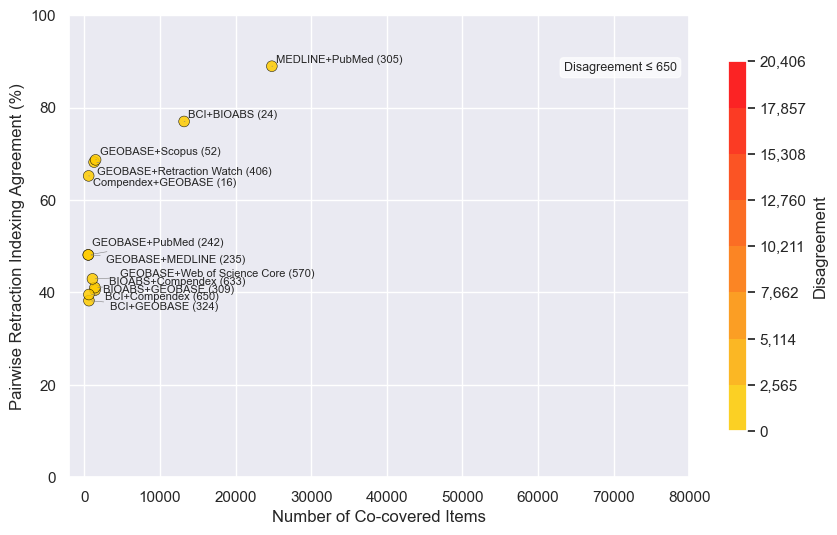

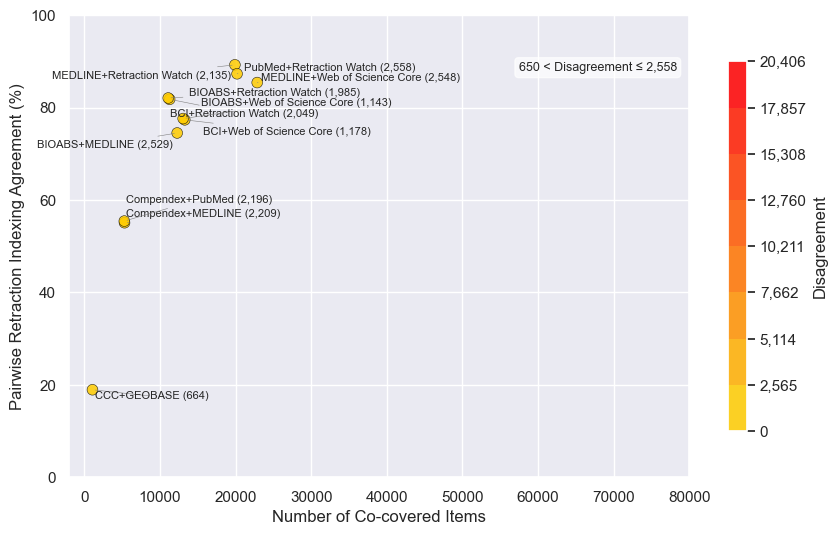

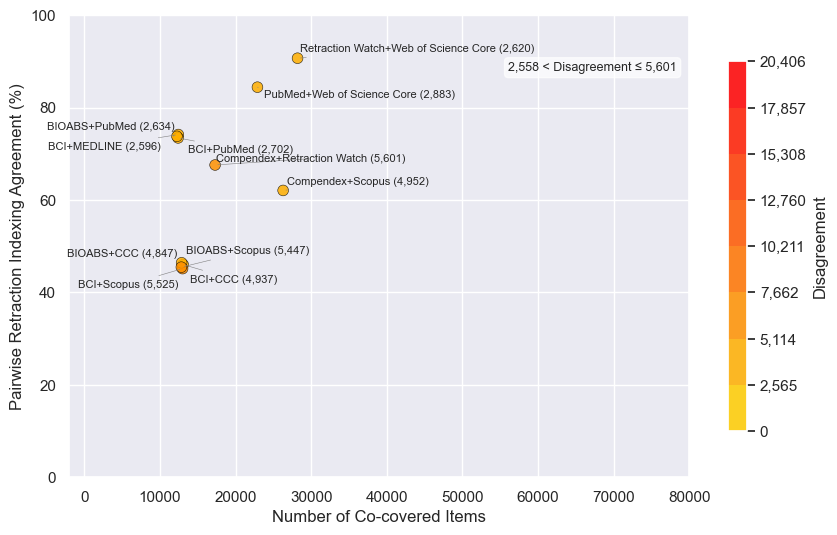

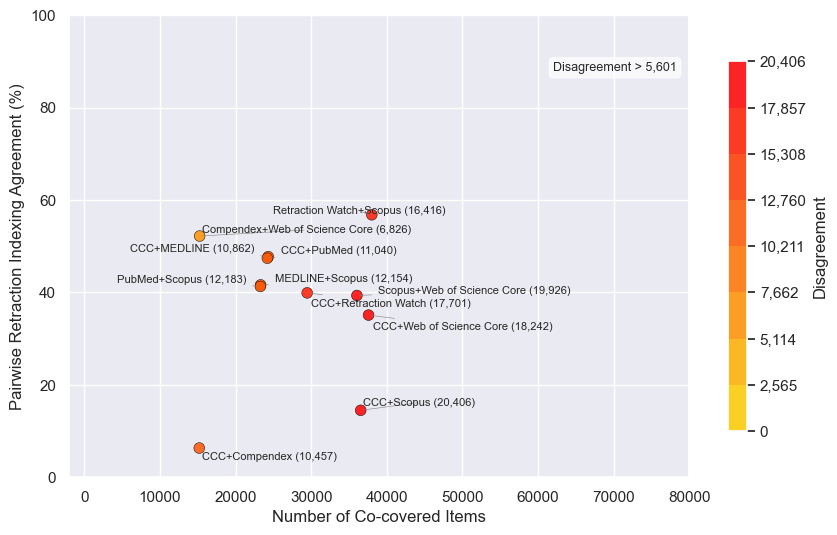

In [49]:
### Final for paper
### ADJUSTING ---USE THIS
sns.set_style("darkgrid")
from matplotlib.colors import ListedColormap, BoundaryNorm, LinearSegmentedColormap
import numpy as np
from adjustText import adjust_text

def truncate_colormap(cmap, minval=0.0, maxval=1.0, n=100):
    if isinstance(cmap, str):
        cmap = plt.get_cmap(cmap)
    return LinearSegmentedColormap.from_list(
        f'trunc({cmap.name},{minval:.2f},{maxval:.2f})',
        cmap(np.linspace(minval, maxval, n)))


q25 = df_pairwise2_ria['total_disagreement'].quantile(0.25)
q50 = df_pairwise2_ria['total_disagreement'].quantile(0.50)
q75 = df_pairwise2_ria['total_disagreement'].quantile(0.75)

quartiles = [
    ('Disagreement ≤ {:,.0f}'.format(q25),                   df_pairwise2_ria[df_pairwise2_ria.total_disagreement <= q25]),
    ('{:,.0f} < Disagreement ≤ {:,.0f}'.format(q25, q50),   df_pairwise2_ria[(df_pairwise2_ria.total_disagreement > q25) & (df_pairwise2_ria.total_disagreement <= q50)]),
    ('{:,.0f} < Disagreement ≤ {:,.0f}'.format(q50, q75),   df_pairwise2_ria[(df_pairwise2_ria.total_disagreement > q50) & (df_pairwise2_ria.total_disagreement <= q75)]),
    ('Disagreement > {:,.0f}'.format(q75),                  df_pairwise2_ria[df_pairwise2_ria.total_disagreement > q75]),
]

manual_offsets = {
    # 'Source1+Source2': (dx, dy),
    "Compendex+GEOBASE": (3,-1),
    "GEOBASE+Scopus": (3,2), 
    "GEOBASE+MEDLINE": (13,-0.2),
    "GEOBASE+PubMed": (3,5),
    "GEOBASE+Web of Science Core": (20,0.125),
    "BIOABS+GEOBASE": (10, 0), ###
    "BCI+GEOBASE": (15,-1),  
    "BCI+Compendex": (7,-1), 
    "BCI+BIOABS": (3,1),
    "CCC+GEOBASE": (1.5,-1),
    "BIOABS+Compendex": (10,0.75),
    "PubMed+Web of Science Core": (-2,1),
    "MEDLINE+Web of Science Core": (3,0),

    # Q2
    "BIOABS+Retraction Watch": (15,0.5),
    "MEDLINE+PubMed": (3,1),
    "MEDLINE+Retraction Watch": (-3,-4),
    "BCI+Retraction Watch": (0.02,-7),
    "PubMed+Retraction Watch": (5,1),
    "Compendex+PubMed": (1,12), ###
    "Compendex+MEDLINE": (1,3),
    "BCI+Web of Science Core": (13,-5),
    "BIOABS+Web of Science Core": (13,8), ###
    "PubMed+Web of Science Core": (5,-2),
    "BCI+PubMed": (7,-5), ###
    "BIOABS+PubMed": (-2,3),

    # Q3
    "BIOABS+CCC": (-3,3),
    "BCI+CCC": (5,-7),
    "GEOBASE+Retraction Watch": (2,-3),
    "MEDLINE+Scopus": (10,1), ###
    "Compendex+Web of Science Core": (2,0.8), "Compendex+Scopus": (3,3),
    "PubMed+Scopus": (-10,1), ### 

    "BIOABS+MEDLINE": (-3,-5), 
    "Compendex+Retraction Watch": (1,1),
    "BCI+MEDLINE": (-13,-5), ###
    "BIOABS+Scopus": (3,8),
    "BCI+Scopus": (-3,-8),
    "Retraction Watch+Web of Science Core": (2,3),
    "CCC+Scopus": (2,2),

    # Q4
    "BIOABS+Crossref": (-1,5),
    "BCI+Crossref": (-5,-3),
    "Scopus+Web of Science Core": (15,0),
    "CCC+PubMed": (10,2), ###
    "CCC+Web of Science Core": (3,-5), 
    "CCC+Retraction Watch": (3,-4),
    "CCC+Compendex": (2,-3),
    "CCC+MEDLINE": (-10,2),
}

fig1, ax1 = plt.subplots(figsize=(10, 6))

fig2, ax2 = plt.subplots(figsize=(10, 6))

fig3, ax3 = plt.subplots(figsize=(10, 6))

fig4, ax4 = plt.subplots(figsize=(10, 6))

axes = [ax1, ax2, ax3, ax4]
figs = [fig1, fig2, fig3, fig4]

vmin, vmax = df_pairwise2_ria.total_disagreement.min(), df_pairwise2_ria.total_disagreement.max()

# ---- Discrete cmap built from a truncated continuous one (drops pale yellow low end).
n_bins = 8
base_cmap = truncate_colormap('autumn_r', 0.2, 1.0)            # try 'plasma', 'magma', 'YlOrRd_r' too
cmap = ListedColormap(base_cmap(np.linspace(0, 1, n_bins)))    # sample n_bins colors from it
boundaries = np.linspace(vmin, vmax, n_bins + 1)
norm = BoundaryNorm(boundaries, ncolors=n_bins)

for i, (ax, (title, subset)) in enumerate(zip(axes, quartiles)):
    
    ax.set_ylabel('Pairwise Retraction Indexing Agreement (%)')
    ax.yaxis.set_label_position('left')
    ax.tick_params(labelright=False, labelleft=True)

    sc = ax.scatter(subset.pairwise_covered, subset['RetractionIndexingAgreement_SOURCE(%)'],
                    c=subset.total_disagreement, cmap=cmap, norm=norm,
                    s=60, alpha=0.85,
                    edgecolor='black', linewidth=0.4)
    
    auto_texts = []
    for _, row in subset.iterrows():
        key   = f"{row.source1}+{row.source2}"
        label = f"{key} ({row.total_disagreement:,.0f})"          # one-line label
        # label = f"{key}\n({row.total_disagreement:,.0f})"       # ...or two-line label

        if key in manual_offsets:
            dx, dy = manual_offsets[key]
            ha = 'left' if dx >= 0 else 'right'
            va = 'bottom' if dy >= 0 else 'top'
            ax.annotate(
                label,
                xy=(row.pairwise_covered, row['RetractionIndexingAgreement_SOURCE(%)']),
                xytext=(dx, dy), textcoords='offset points',
                fontsize=8, ha=ha, va=va,
                arrowprops=dict(arrowstyle='-', color='gray', lw=0.4),
            )
        else:
            auto_texts.append(
                ax.text(row.pairwise_covered, row['RetractionIndexingAgreement_SOURCE(%)'], label, fontsize=8)
            )

    adjust_text(auto_texts, ax=ax,
                arrowprops=dict(arrowstyle='-', color='gray', lw=0.4),
                expand_points=(1.5, 1.5),
                expand_text=(1.2, 1.4))

    ax.text(0.98, 0.90,
            f'{title}',
            transform=ax.transAxes,
            fontsize=9, va='top', ha='right',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

for ax in axes:
    ax.tick_params(labelbottom=True)
    ax.set_xlim(-2000, 80000)
    ax.set_xlabel('Number of Co-covered Items')
    ax.set_ylim(0, 100)

for fig_item in figs:
    fig_var = plt.figure(fig_item)
    ax = fig_var.gca()
    cbar = fig_var.colorbar(sc, ax=ax, label='Disagreement', shrink=0.8,
                        ticks=boundaries, spacing='uniform')
    cbar.ax.set_yticklabels(['0'] + [f'{b:,.0f}' for b in boundaries[1:]])

    # fig.suptitle('Coverage vs Agreement, by Disagreement Quartile', fontsize=13, y=0.90)
    plt.savefig(result_dir+f"NEW_pairswise_RIA_Scores_in_quartiles_{figs.index(fig_item)}.png", dpi=300,bbox_inches="tight")
plt.show()

## Section 3: Calculation of RetractionIndexAgreement by Item

In [50]:
"""
Recall:
v = unique retraction indexing agreement scores from unionlist3_adjusted, stored as an array
c = count of items with unique retraction indexing agreement score, stored as an array
"""
v, c = np.unique(unionlist3_adjusted['RetractionIndexingAgreement_ITEM(%)'], return_counts=True)
print(v)
print(c)

[ 10.          11.11111111  12.5         14.28571429  16.66666667
  20.          22.22222222  25.          28.57142857  30.
  33.33333333  37.5         40.          42.85714286  44.44444444
  50.          55.55555556  57.14285714  60.          62.5
  66.66666667  70.          71.42857143  75.          77.77777778
  80.          83.33333333  85.71428571  87.5         88.88888889
  90.         100.        ]
[    1    10   102   244   184   635     3  1699   242     5  2243   170
  1715   489    18  7224    90  1058  2173   776  2961    45   861  3202
   263  4372  3265  1204  3534   137    11 19660]


/var/folders/yk/fnf1_8ns45l37dy9skp83h5r0000gn/T/ipykernel_76076/1979030636.py:11: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x=v, y=c,  ax=ax3, orient='h', color="#1f77b4", ci= None) #errorbar=None


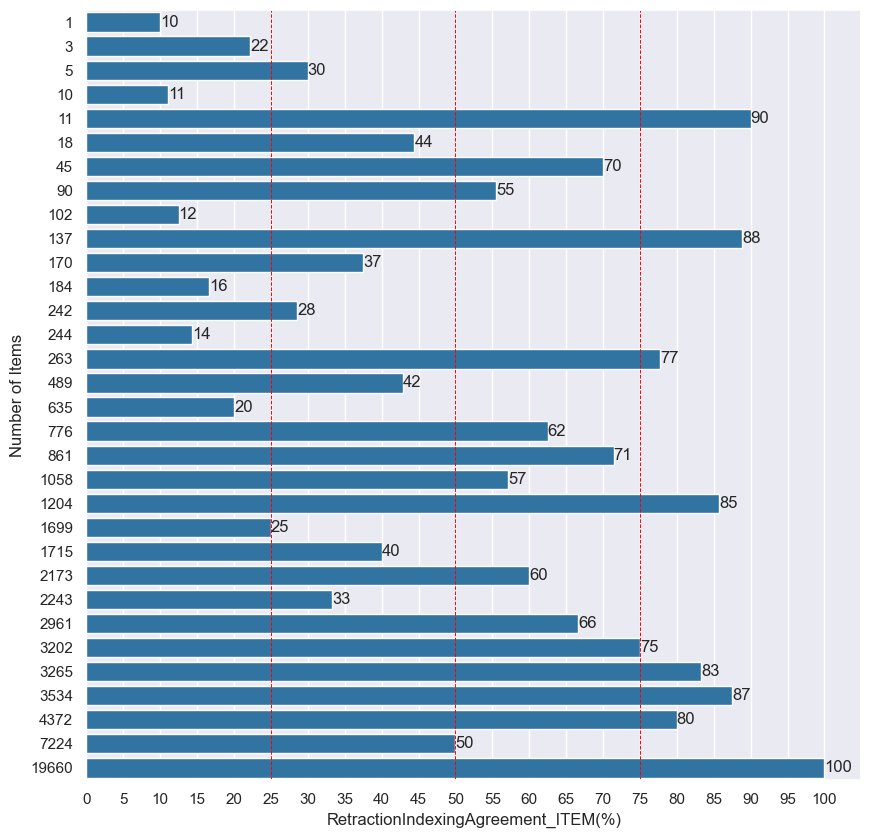

In [51]:
"""
Overall Retraction Indexing Agreement by Items
"""

sns.set_theme()

# Create a figure and axis
fig3, ax3 = plt.subplots(figsize = (10, 10))

# Use Seaborn's barplot with 'counts' on the y-axis and 'unique RetractionIndexingAgreement scores' on the x-axis
sns.barplot(x=v, y=c,  ax=ax3, orient='h', color="#1f77b4", ci= None) #errorbar=None

ax3.set_xticks(range(0, 101,5))

# Display the numbers on the bars
for p in ax3.patches:
    ax3.text(p.get_width(), p.get_y() + p.get_height() / 2, f'{int(p.get_width())}',
            ha='left',va='center')

# Define the positions for vertical dashed lines
vertical_lines = [25,50,75]

# Plot vertical dashed lines at the specified positions
for line in vertical_lines:
    ax3.axvline(x=line, color='red', linestyle='--', linewidth=0.7)

# Set plot labels and title
ax3.set_xlabel('RetractionIndexingAgreement_ITEM(%)')
ax3.set_ylabel('Number of Items') #Number of DOIs
# ax3.set_title('RetractionIndexingAgreement Score By Item')

# Save to folder
plt.savefig(result_dir+'indexing_agreement_score_by_items.png')
plt.show()



In [52]:
"""
Mapping Color to the Count of Items in Retraction Indexing Agreement by Items
"""

items_score_df= pd.DataFrame(v,c).reset_index()
items_score_df= items_score_df.rename(columns={'index':'noDOIs',0: 'RIA_Score(%)'})


cmap03_0 = {
    'red': 24,
    'orange': 49,
    '#1f77b4': 74, #blue
    'green': 100}

def get_color2(value):
    for color, threshold in cmap03_0.items():
        if value <= threshold:
            return color

# # Use the colormap to assign colors based on the percentages
# overview_RIA_source['Color'] = overview_RIA_source['RetractionIndexingAgreement_SOURCE(%)'].apply(get_color)

# # Assigning color to Sources
# mycolor_01_1 = dict(zip(overview_RIA_source['Source'], overview_RIA_source['Color']))

items_score_df['Fraction_in_Unionlist(%)'] = round((items_score_df['noDOIs'] / len(unionlist_indexed)) * 100, 2)

# Use the colormap to assign colors based on the percentages
items_score_df['Color']= items_score_df['RIA_Score(%)'].apply(get_color2)

items_score_df

,noDOIs,RIA_Score(%),Fraction_in_Unionlist(%),Color
0,1,10.000000,0.00,red
1,10,11.111111,0.02,red
2,102,12.500000,0.17,red
3,244,14.285714,0.42,red
4,184,16.666667,0.31,red
5,635,20.000000,1.08,red
6,3,22.222222,0.01,red
7,1699,25.000000,2.90,orange
8,242,28.571429,0.41,orange
9,5,30.000000,0.01,orange


In [53]:
"""
Fetching RetractionIndexingAgreement_ITEM(%) for Each Source
"""
sources_ria_df= pd.DataFrame(v, columns=['RIA_Score'])

for source in sources_indexed:
    #print(source)
    filter_source= unionlist3_adjusted[unionlist3_adjusted['source_old'].str.contains(source)]
    
    ria_score, nDOI = np.unique(filter_source['RetractionIndexingAgreement_ITEM(%)'], return_counts=True)
    
    tempo_df= pd.DataFrame({'RIA_Score': ria_score, source: nDOI})#columns=['RIA_Score',source]
    
    sources_ria_df= pd.merge(sources_ria_df,tempo_df,on='RIA_Score',how='left')


sources_ria_df= sources_ria_df.fillna(0.0)
sources_ria_df.set_index('RIA_Score', inplace= True)

sources_ria_df_= sources_ria_df.transpose()
sources_ria_df_ 

RIA_Score,10.000000,11.111111,12.500000,14.285714,16.666667,20.000000,22.222222,25.000000,28.571429,30.000000,...,71.428571,75.000000,77.777778,80.000000,83.333333,85.714286,87.500000,88.888889,90.000000,100.000000
BCI,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,191.0,1102.0,253.0,26.0,129.0,784.0,3527.0,133.0,10.0,3355.0
BIOABS,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,177.0,1071.0,253.0,24.0,122.0,757.0,3526.0,136.0,11.0,3332.0
CCC,0.0,0.0,0.0,0.0,1.0,0.0,0.0,13.0,10.0,2.0,...,304.0,536.0,258.0,658.0,2278.0,97.0,1996.0,21.0,10.0,5299.0
Compendex,0.0,0.0,0.0,1.0,1.0,0.0,0.0,502.0,4.0,0.0,...,375.0,502.0,18.0,3171.0,641.0,465.0,141.0,116.0,9.0,9307.0
GEOBASE,0.0,0.0,0.0,0.0,0.0,0.0,1.0,3.0,1.0,0.0,...,4.0,12.0,2.0,88.0,91.0,45.0,15.0,14.0,9.0,548.0
Medline,0.0,0.0,0.0,2.0,1.0,2.0,2.0,8.0,177.0,3.0,...,786.0,1583.0,258.0,1118.0,3057.0,1110.0,3521.0,137.0,11.0,5457.0
PubMed,0.0,4.0,6.0,10.0,3.0,9.0,2.0,6.0,171.0,3.0,...,789.0,1534.0,257.0,1117.0,3047.0,1104.0,3482.0,135.0,10.0,6086.0
Retraction Watch,1.0,6.0,94.0,111.0,129.0,453.0,1.0,756.0,54.0,5.0,...,736.0,2674.0,262.0,3622.0,2728.0,665.0,3408.0,137.0,11.0,14920.0
Scopus,0.0,0.0,2.0,119.0,48.0,143.0,0.0,248.0,36.0,0.0,...,100.0,1376.0,17.0,3501.0,978.0,1003.0,1588.0,130.0,7.0,15754.0
WoS_Core,0.0,0.0,0.0,1.0,1.0,28.0,0.0,285.0,31.0,2.0,...,843.0,2735.0,263.0,4167.0,3254.0,1194.0,3534.0,137.0,11.0,5604.0


In [54]:
# Unindexing the RIA_Score and renaming to Source
sources_ria_df_.columns
sources_ria_df_.reset_index(inplace=True)
sources_ria_df_.rename(columns={'index':'Source'}, inplace=True)
sources_ria_df_

"""
Normalizing the raw count into percentage
"""
row_sums = sources_ria_df_.iloc[:, 1:].sum(axis=1)
numeric_df = sources_ria_df_.iloc[:, 1:].apply(pd.to_numeric, errors='coerce')
result_item_score = pd.concat([sources_ria_df_['Source'], (numeric_df.div(row_sums, axis=0))*100], axis=1)

result_item_score 

,Source,10.0,11.111111,12.5,14.285714,16.666667,20.0,22.222222,25.0,28.571429,...,71.428571,75.0,77.777778,80.0,83.333333,85.714286,87.5,88.888889,90.0,100.0
0,BCI,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.855450,10.705265,2.457742,0.252574,1.253157,7.616087,34.262677,1.292015,0.097144,32.591801
1,BIOABS,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.741098,10.535117,2.488688,0.236081,1.200079,7.446390,34.684242,1.337793,0.108204,32.775920
2,CCC,0.000000,0.000000,0.000000,0.000000,0.007543,0.000000,0.000000,0.098061,0.075432,...,2.293128,4.043147,1.946142,4.963416,17.183375,0.731689,15.056197,0.158407,0.075432,39.971336
3,Compendex,0.000000,0.000000,0.000000,0.005190,0.005190,0.000000,0.000000,2.605626,0.020762,...,1.946434,2.605626,0.093429,16.459047,3.327105,2.413578,0.731859,0.602097,0.046714,48.307900
4,GEOBASE,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.096246,0.288739,0.096246,...,0.384986,1.154957,0.192493,8.469682,8.758422,4.331088,1.443696,1.347449,0.866218,52.743022
5,Medline,0.000000,0.000000,0.000000,0.008967,0.004484,0.008967,0.008967,0.035868,0.793580,...,3.524032,7.097382,1.156743,5.012554,13.706062,4.976686,15.786406,0.614240,0.049319,24.466463
6,PubMed,0.000000,0.017570,0.026355,0.043925,0.013178,0.039533,0.008785,0.026355,0.751120,...,3.465694,6.738118,1.128876,4.906439,13.383994,4.849337,15.294738,0.592990,0.043925,26.732847
7,Retraction Watch,0.002309,0.013853,0.217035,0.256286,0.297846,1.045924,0.002309,1.745515,0.124680,...,1.699337,6.173951,0.604927,8.362772,6.298631,1.535407,7.868671,0.316317,0.025398,34.448523
8,Scopus,0.000000,0.000000,0.006475,0.385263,0.155400,0.462963,0.000000,0.802901,0.116550,...,0.323750,4.454804,0.055038,11.334499,3.166278,3.247216,5.141155,0.420875,0.022663,51.003626
9,WoS_Core,0.000000,0.000000,0.000000,0.003129,0.003129,0.087612,0.000000,0.891768,0.096999,...,2.637755,8.557840,0.822929,13.038581,10.181795,3.736037,11.057918,0.428674,0.034419,17.534967


/var/folders/yk/fnf1_8ns45l37dy9skp83h5r0000gn/T/ipykernel_76076/1960082765.py:11: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x=items_score_df['RIA_Score(%)'],
/var/folders/yk/fnf1_8ns45l37dy9skp83h5r0000gn/T/ipykernel_76076/1960082765.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=items_score_df['RIA_Score(%)'],


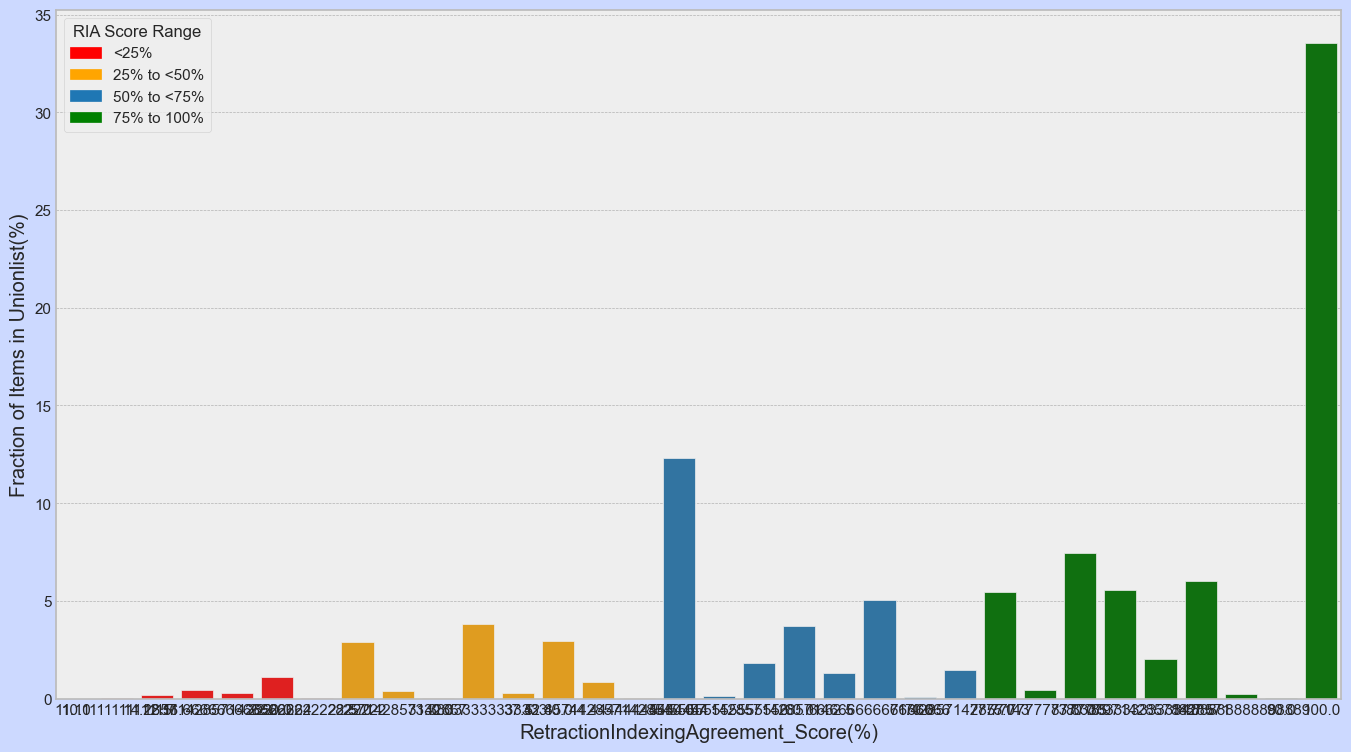

In [55]:
"""
Retraction Indexing Agreement by Items: Fraction of Items in the Union list  (Coloring)
"""

plt.style.use('bmh')
fig3_01_1, ax3_01_1 = plt.subplots(figsize=(14, 8))

mycolor_3_01_1 = dict(zip(items_score_df['RIA_Score(%)'].astype(str), items_score_df['Color']))

# Create the bar plot
sns.barplot(x=items_score_df['RIA_Score(%)'],
            y=items_score_df['Fraction_in_Unionlist(%)'],
            ax=ax3_01_1, 
            color="#1f77b4", 
            palette=mycolor_3_01_1,
            ci=None)

#Add custom legend
legend_labels = {
    'red': '<25%',
    'orange': '25% to <50%',
    '#1f77b4': '50% to <75%',
    'green': '75% to 100%'
}


legend_handles = [mpatches.Patch(color=color, label=label) for color, label in legend_labels.items()]

ax3_01_1.legend(handles=legend_handles, title="RIA Score Range", loc="upper left")


# Set labels and title
ax3_01_1.set_xlabel("RetractionIndexingAgreement_Score(%)")
ax3_01_1.set_ylabel("Fraction of Items in Unionlist(%)")

fig3_01_1.patch.set_facecolor('#ccd9ff') 
plt.tight_layout(pad=2.0)

# Save to folder
plt.savefig(result_dir+'indexing_agreement_score_by_items_inUnionlist_colored.png')
plt.show()




In [56]:
"""
Grouping RIA score: '<25%' '25% to <50%' '50% to <75%' '75% to <100%' '100%'
"""
less_than_25=items_score_df[items_score_df['RIA_Score(%)']<25].iloc[:,:-1]
btw_25_50=items_score_df[(items_score_df['RIA_Score(%)']>=25) & (items_score_df['RIA_Score(%)']<50)].iloc[:,:-1]
btw_50_75=items_score_df[(items_score_df['RIA_Score(%)']>=50) & (items_score_df['RIA_Score(%)']<75)].iloc[:,:-1]
greater_than_75=items_score_df[(items_score_df['RIA_Score(%)']>=75) & (items_score_df['RIA_Score(%)']<100)].iloc[:,:-1]
is_100=items_score_df[items_score_df['RIA_Score(%)']==100].iloc[:,:-1]


table3_01_2= pd.DataFrame([less_than_25.sum(),btw_25_50.sum(),btw_50_75.sum(),greater_than_75.sum(),is_100.sum()]).drop(['RIA_Score(%)'],axis=1)

table3_01_2['noDOIs']= table3_01_2['noDOIs'].astype(int)

table3_01_2['RIA_Score(%)'] = ["<25%",'25% to <50%','50% to <75%','75% to <100%', '100%']
table3_01_2['Color']= ['red','orange','#1f77b4','green','#00FF00']
table3_01_2

,noDOIs,Fraction_in_Unionlist(%),RIA_Score(%),Color
0,1179,2.01,<25%,red
1,6581,11.23,25% to <50%,orange
2,15188,25.92,50% to <75%,#1f77b4
3,15988,27.27,75% to <100%,green
4,19660,33.55,100%,#00FF00


/var/folders/yk/fnf1_8ns45l37dy9skp83h5r0000gn/T/ipykernel_76076/4270591856.py:11: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(y=table3_01_2['Fraction_in_Unionlist(%)'], x=table3_01_2['RIA_Score(%)'],
/var/folders/yk/fnf1_8ns45l37dy9skp83h5r0000gn/T/ipykernel_76076/4270591856.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=table3_01_2['Fraction_in_Unionlist(%)'], x=table3_01_2['RIA_Score(%)'],


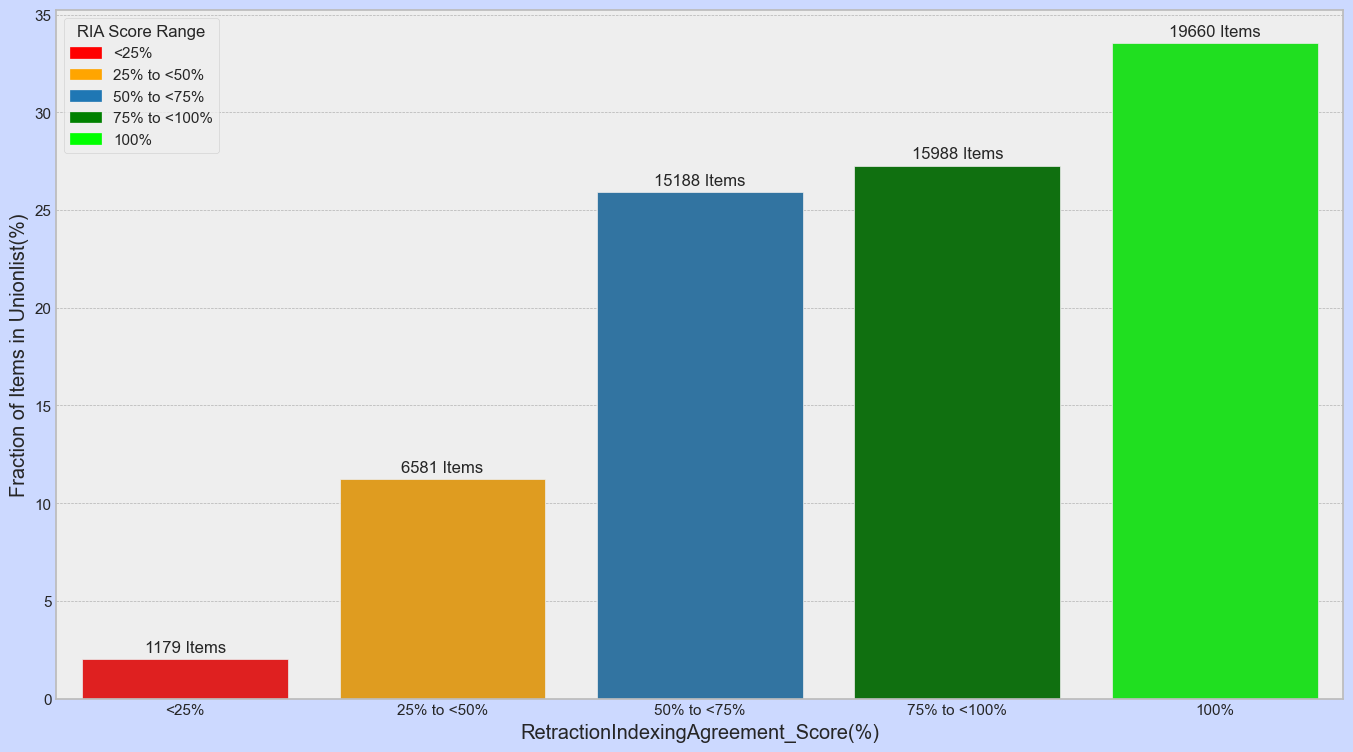

In [57]:
"""
Retraction Indexing Agreement by Items (in Group)
"""

plt.style.use('bmh')
fig3_01_2, ax3_01_2 = plt.subplots(figsize=(14, 8))

mycolor_3_01_2 = dict(zip(table3_01_2['RIA_Score(%)'], table3_01_2['Color']))

# Create the bar plot
sns.barplot(y=table3_01_2['Fraction_in_Unionlist(%)'], x=table3_01_2['RIA_Score(%)'],
            ax=ax3_01_2, color="#1f77b4",palette=mycolor_3_01_2, ci=None)

#Add custom legend
legend_labels = {
    'red': '<25%',
    'orange': '25% to <50%',
    '#1f77b4': '50% to <75%',
    'green': '75% to <100%',
    '#00FF00':'100%'
}

legend_handles = [mpatches.Patch(color=color, label=label) for color, label in legend_labels.items()]

ax3_01_2.legend(handles=legend_handles, title="RIA Score Range", loc="upper left")

# Label bars with noDOIs values
for bar, noDOIs in zip(ax3_01_2.patches, table3_01_2['noDOIs']):
    ax3_01_2.annotate(f"{noDOIs} Items", #f"{noDOIs} / {len(unionlist3)}"
                      xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                      xytext=(0, 3),  # 3 points vertical offset
                      textcoords="offset points",
                      ha='center', va='bottom')

# Set labels and title
ax3_01_2.set_xlabel("RetractionIndexingAgreement_Score(%)")
ax3_01_2.set_ylabel("Fraction of Items in Unionlist(%)")

fig3_01_2.patch.set_facecolor('#ccd9ff') 
plt.tight_layout(pad=2.0)

# Save to folder
plt.savefig(result_dir+'indexing_agreement_score_by_items_inUnionlist_colored2.png')
plt.show()




In [58]:
result_item_score.columns[1:]

Index([              10.0,  11.11111111111111,               12.5,
       14.285714285714285, 16.666666666666664,               20.0,
        22.22222222222222,               25.0,  28.57142857142857,
                     30.0,  33.33333333333333,               37.5,
                     40.0, 42.857142857142854,  44.44444444444444,
                     50.0,  55.55555555555556,  57.14285714285714,
                     60.0,               62.5,  66.66666666666666,
                     70.0,  71.42857142857143,               75.0,
        77.77777777777779,               80.0,  83.33333333333334,
        85.71428571428571,               87.5,  88.88888888888889,
                     90.0,              100.0],
      dtype='object')

In [59]:
result_item_score

,Source,10.0,11.111111,12.5,14.285714,16.666667,20.0,22.222222,25.0,28.571429,...,71.428571,75.0,77.777778,80.0,83.333333,85.714286,87.5,88.888889,90.0,100.0
0,BCI,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.855450,10.705265,2.457742,0.252574,1.253157,7.616087,34.262677,1.292015,0.097144,32.591801
1,BIOABS,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.741098,10.535117,2.488688,0.236081,1.200079,7.446390,34.684242,1.337793,0.108204,32.775920
2,CCC,0.000000,0.000000,0.000000,0.000000,0.007543,0.000000,0.000000,0.098061,0.075432,...,2.293128,4.043147,1.946142,4.963416,17.183375,0.731689,15.056197,0.158407,0.075432,39.971336
3,Compendex,0.000000,0.000000,0.000000,0.005190,0.005190,0.000000,0.000000,2.605626,0.020762,...,1.946434,2.605626,0.093429,16.459047,3.327105,2.413578,0.731859,0.602097,0.046714,48.307900
4,GEOBASE,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.096246,0.288739,0.096246,...,0.384986,1.154957,0.192493,8.469682,8.758422,4.331088,1.443696,1.347449,0.866218,52.743022
5,Medline,0.000000,0.000000,0.000000,0.008967,0.004484,0.008967,0.008967,0.035868,0.793580,...,3.524032,7.097382,1.156743,5.012554,13.706062,4.976686,15.786406,0.614240,0.049319,24.466463
6,PubMed,0.000000,0.017570,0.026355,0.043925,0.013178,0.039533,0.008785,0.026355,0.751120,...,3.465694,6.738118,1.128876,4.906439,13.383994,4.849337,15.294738,0.592990,0.043925,26.732847
7,Retraction Watch,0.002309,0.013853,0.217035,0.256286,0.297846,1.045924,0.002309,1.745515,0.124680,...,1.699337,6.173951,0.604927,8.362772,6.298631,1.535407,7.868671,0.316317,0.025398,34.448523
8,Scopus,0.000000,0.000000,0.006475,0.385263,0.155400,0.462963,0.000000,0.802901,0.116550,...,0.323750,4.454804,0.055038,11.334499,3.166278,3.247216,5.141155,0.420875,0.022663,51.003626
9,WoS_Core,0.000000,0.000000,0.000000,0.003129,0.003129,0.087612,0.000000,0.891768,0.096999,...,2.637755,8.557840,0.822929,13.038581,10.181795,3.736037,11.057918,0.428674,0.034419,17.534967


In [60]:
"""
RIA by Items: Recategorizing the result into ranges by Source
"""
col_index = result_item_score.columns[1:]	


index_0_to_49= [i for i in col_index if i < 50]
index_50_to_74 = [i for i in col_index if 50 <= i < 75]
index_75_to_99 = [i for i in col_index if 75 <= i < 100]
index_100 = [i for i in col_index if i == 100]

result_item_category= pd.DataFrame({'Source': result_item_score['Source'],
                                '< 50%':result_item_score[index_0_to_49].sum(axis=1),
                                '50% to <75%':result_item_score[index_50_to_74].sum(axis=1),
                                '75% to <100%':result_item_score[index_75_to_99].sum(axis=1),
                                '100%':result_item_score[index_100].sum(axis=1)})

result_item_category.sort_values(by='Source', ascending =True, inplace=True)
result_item_category= result_item_category.round(2)


result_item_category.replace('Medline', 'MEDLINE', inplace =True)
result_item_category.replace('WoS_Core', 'Web of Science Core', inplace =True)
result_item_category

,Source,< 50%,50% to <75%,75% to <100%,100%
0,BCI,0.31,9.16,57.94,32.59
1,BIOABS,0.25,8.94,58.04,32.78
2,CCC,1.34,14.53,44.16,39.97
3,Compendex,4.26,21.15,26.28,48.31
4,GEOBASE,7.41,13.28,26.56,52.74
5,MEDLINE,3.99,23.14,48.40,24.47
6,PubMed,3.91,22.42,46.94,26.73
7,Retraction Watch,11.14,23.23,31.19,34.45
8,Scopus,5.89,15.27,27.84,51.00
9,Web of Science Core,6.72,27.89,47.86,17.53


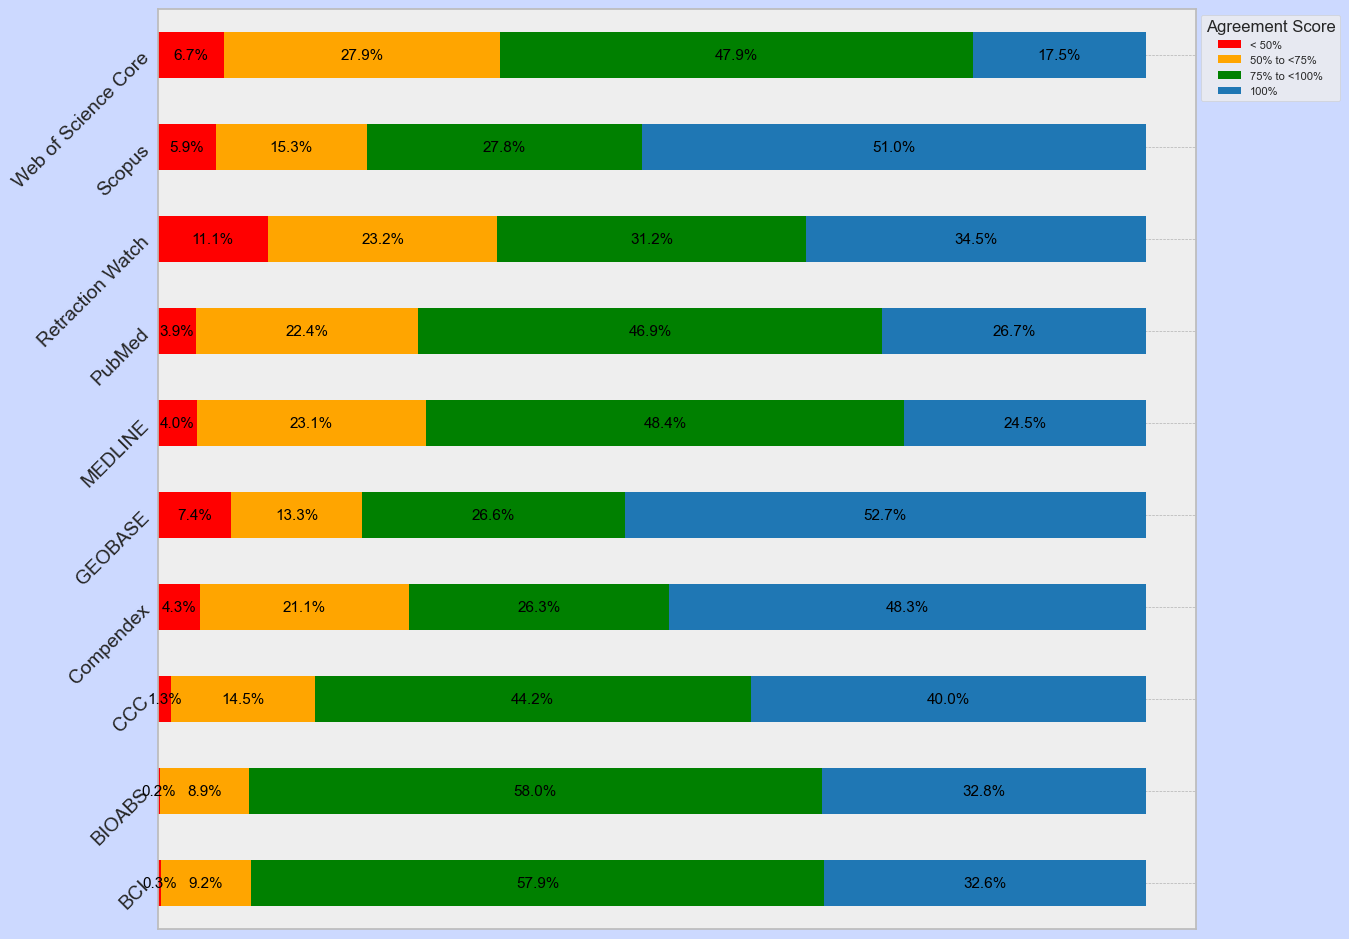

In [61]:
"""
Retraction Indexing Agreemene by Items per Source (horizontal)
"""

plt.style.use('bmh')
fig3_1, ax3_1 =  plt.subplots(figsize=(14, 10))
# plt.subplots_adjust(left=0.8)

# Plot the horizontal stacked bar graph
result_item_category.plot(
    x='Source',
    kind='barh',
    stacked=True,
    #title='Percentage of RetractionIndexingAgreement_DOI in Sources',
    mark_right=True,
    legend=True,
    fontsize=14,
    color=['#ff0000', 'orange', 'green', "#1f77b4"],   # '#ff8000 -red
    ax=ax3_1)

# Loop through each bar to remove white lines
for patch in ax3_1.patches:
    patch.set_edgecolor('none')

# Place the legend outside the plot
ax3_1.legend(loc='upper left', bbox_to_anchor=(1, 1), title='Agreement Score', fontsize=8)

for p in ax3_1.patches:
    width = p.get_width()
    label_x = p.get_x() + width / 2
    label_y = p.get_y() + p.get_height() / 2
    ax3_1.text(label_x, label_y, f'{width:.1f}%', ha='center', va='center', color='black', fontsize=11)

# Set the background color of the figure
fig3_1.patch.set_facecolor('#ccd9ff')

# Rotate the y-axis labels
plt.setp(ax3_1.get_yticklabels(), rotation=45)

# Set the background color of the figure
fig3_1.patch.set_facecolor('#ccd9ff')

# Adjust layout to add space between y-axis labels and the graph
plt.tight_layout(pad=3.0)


# Add space between y-axis scale label and the graph
plt.subplots_adjust(left=0.12,bottom=0.03)

# Remove the number scale on the x-axis
plt.xticks([])

# Remove 'Source Label'
ax3_1.set_ylabel('') 

# Save to folder    
plt.savefig(result_dir+'perecent_DOIs_RIA_in_sources.png')
plt.show()




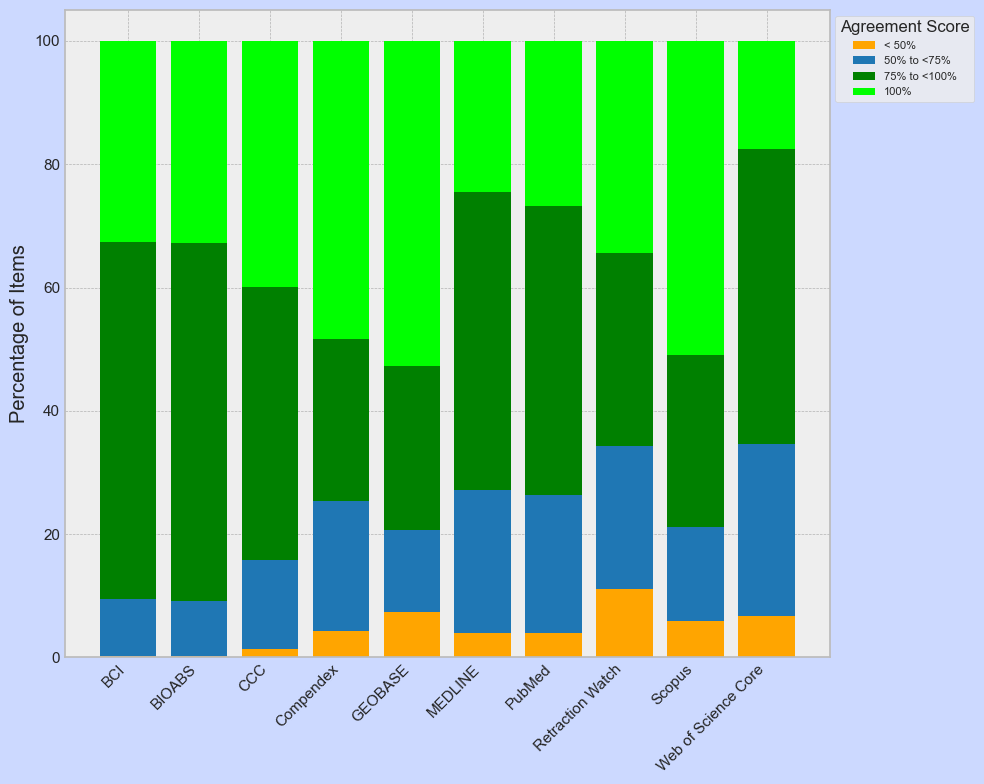

In [62]:
"""
Retraction Indexing Agreemene by Items per Source (Vertical)
"""

plt.style.use('bmh')
fig3_2, ax3_2= plt.subplots(figsize=(10, 8))

"""
<25%: Light red or pink shades. Hexadecimal color code: #FFCCCC or #FFB6C1.
25% to <50%: Light orange or peach shades. Hexadecimal color code: #FFDAB9 or #FFA07A.
50% to <75%: Light yellow or gold shades. Hexadecimal color code: #FFFFCC or #FFD700.
75% to <100%: Light green or lime shades. Hexadecimal color code: #BDFCC9 or #ADFF2F.
100%: Bright green. Hexadecimal color code: #00FF00 or #7CFC00

"""

# Stack bars
bar1=ax3_2.bar(result_item_category['Source'], result_item_category['< 50%'], label='< 50%',color= 'orange' ) #orange
bar2= ax3_2.bar(result_item_category['Source'], result_item_category['50% to <75%'], bottom=result_item_category['< 50%'], label='50% to <75%',color='#1f77b4')
bar3= ax3_2.bar(result_item_category['Source'], result_item_category['75% to <100%'], bottom=result_item_category['< 50%'] + result_item_category['50% to <75%'], label='75% to <100%', color='green')
bar4= ax3_2.bar(result_item_category['Source'], result_item_category['100%'], bottom=result_item_category['< 50%'] + result_item_category['50% to <75%'] + result_item_category['75% to <100%'], label='100%',color='#00FF00')

# Rotate x-axis labels for better visibility
plt.xticks(rotation=45, ha='right')

# # Add text annotations
# for bar in [bar1, bar2, bar3, bar4]:
#     for rect in bar:
#         height = rect.get_height()
#         ax3_2.annotate(f'{height:.2f}%', xy=(rect.get_x() + rect.get_width() / 2, height), xytext=(0, 2),
#                        textcoords="offset points", ha='center', va='bottom')

# Loop through each bar to remove white lines
for patch in ax3_2.patches:
    patch.set_edgecolor('none')

# Add legend
ax3_2.legend(title='Agreement Score', bbox_to_anchor=(1, 1), fontsize=8)

# Set labels and title
ax3_2.set_ylabel('Percentage of Items')
# ax3_2.set_xlabel('Source')
# ax3_2.set_title('Stacked Percentage by Source')

# Set the background color of the figure
fig3_2.patch.set_facecolor('#ccd9ff')

plt.tight_layout()

# Save to folder
plt.savefig(result_dir+'perecent_DOIs_RIA_in_sources2.png')

plt.show()




## RIA vs coverage scatter plot

In [63]:
base_df = unionlist3_adjusted.loc[:,['DOI', 'source_new', 'source_old', 'RetractionIndexingAgreement_ITEM(%)']]
base_df['source_new'] = base_df.source_new.apply(ast.literal_eval) # change from string to list
base_df['source_old'] = base_df.source_old.apply(ast.literal_eval) # change from string to list
base_df

,DOI,source_new,source_old,RetractionIndexingAgreement_ITEM(%)
0,10.1001/archdermatol.2012.1796,"[CCC, Medline, PubMed, Scopus, WoS_Core]","[CCC, WoS_Core]",40.0
1,10.1001/archdermatol.2012.418,"[CCC, Medline, PubMed, Retraction Watch]","[Medline, PubMed, Retraction Watch]",75.0
2,10.1001/archinte.165.15.1737,"[BCI, BIOABS, CCC, Medline, PubMed, Retraction...","[BCI, BIOABS, CCC, Medline, PubMed, Retraction...",87.5
3,10.1001/archinte.165.15.1743,"[BCI, BIOABS, CCC, Medline, PubMed, Retraction...","[BCI, BIOABS, CCC, Medline, PubMed, Retraction...",87.5
4,10.1001/archinte.165.18.2142,"[BCI, BIOABS, CCC, Medline, PubMed, Retraction...","[BCI, BIOABS, CCC, Medline, PubMed, Retraction...",87.5
...,...,...,...,...
58591,nodoi_95,[PubMed],[PubMed],100.0
58592,nodoi_96,[PubMed],[PubMed],100.0
58593,nodoi_97,[PubMed],[PubMed],100.0
58594,nodoi_98,[PubMed],[PubMed],100.0


In [64]:
count_sources_covering_item = base_df.source_new.apply(len)
count_sources_indexing_item = base_df.source_old.apply(len)
base_df['count_sources_covering_item'] = count_sources_covering_item
base_df['count_sources_indexing_item'] = count_sources_indexing_item

# Check that values still make sense
for index, row in base_df.iterrows():
    if float(row['count_sources_indexing_item']/row['count_sources_covering_item'])*100 == float(row['RetractionIndexingAgreement_ITEM(%)']):
        continue
    else:
        print(f"Error at Row {index}, count indexing / count covering != RIA")

base_df

,DOI,source_new,source_old,RetractionIndexingAgreement_ITEM(%),count_sources_covering_item,count_sources_indexing_item
0,10.1001/archdermatol.2012.1796,"[CCC, Medline, PubMed, Scopus, WoS_Core]","[CCC, WoS_Core]",40.0,5,2
1,10.1001/archdermatol.2012.418,"[CCC, Medline, PubMed, Retraction Watch]","[Medline, PubMed, Retraction Watch]",75.0,4,3
2,10.1001/archinte.165.15.1737,"[BCI, BIOABS, CCC, Medline, PubMed, Retraction...","[BCI, BIOABS, CCC, Medline, PubMed, Retraction...",87.5,8,7
3,10.1001/archinte.165.15.1743,"[BCI, BIOABS, CCC, Medline, PubMed, Retraction...","[BCI, BIOABS, CCC, Medline, PubMed, Retraction...",87.5,8,7
4,10.1001/archinte.165.18.2142,"[BCI, BIOABS, CCC, Medline, PubMed, Retraction...","[BCI, BIOABS, CCC, Medline, PubMed, Retraction...",87.5,8,7
...,...,...,...,...,...,...
58591,nodoi_95,[PubMed],[PubMed],100.0,1,1
58592,nodoi_96,[PubMed],[PubMed],100.0,1,1
58593,nodoi_97,[PubMed],[PubMed],100.0,1,1
58594,nodoi_98,[PubMed],[PubMed],100.0,1,1


In [65]:
x = base_df["count_sources_covering_item"]
y = base_df["RetractionIndexingAgreement_ITEM(%)"]

In [66]:
x

0        5
1        4
2        8
3        8
4        8
        ..
58591    1
58592    1
58593    1
58594    1
58595    1
Name: count_sources_covering_item, Length: 58596, dtype: int64

In [67]:
y

0         40.0
1         75.0
2         87.5
3         87.5
4         87.5
         ...  
58591    100.0
58592    100.0
58593    100.0
58594    100.0
58595    100.0
Name: RetractionIndexingAgreement_ITEM(%), Length: 58596, dtype: float64

In [68]:
# count the occurrences of each point
count_dictionary = Counter(zip(x,y))
count_dictionary

Counter({(3, 100.0): 5802,
         (5, 80.0): 4371,
         (2, 100.0): 4317,
         (1, 100.0): 3982,
         (8, 87.5): 3534,
         (6, 83.33333333333334): 3265,
         (4, 50.0): 3207,
         (8, 100.0): 2756,
         (2, 50.0): 2730,
         (5, 60.0): 2137,
         (4, 75.0): 2029,
         (3, 33.33333333333333): 1841,
         (5, 40.0): 1714,
         (3, 66.66666666666666): 1597,
         (4, 25.0): 1577,
         (6, 66.66666666666666): 1327,
         (6, 100.0): 1229,
         (7, 85.71428571428571): 1204,
         (8, 75.0): 1173,
         (7, 57.14285714285714): 1058,
         (6, 50.0): 892,
         (7, 71.42857142857143): 861,
         (8, 62.5): 776,
         (7, 100.0): 637,
         (5, 20.0): 635,
         (7, 42.857142857142854): 489,
         (5, 100.0): 455,
         (8, 50.0): 383,
         (6, 33.33333333333333): 327,
         (9, 77.77777777777779): 263,
         (7, 14.285714285714285): 244,
         (7, 28.57142857142857): 242,
         (9, 10

In [69]:
sum(count_dictionary.values())

58596

In [70]:
from mpl_toolkits.axes_grid1.inset_locator import zoomed_inset_axes
from mpl_toolkits.axes_grid1.inset_locator import mark_inset
from matplotlib.ticker import MaxNLocator
import matplotlib.ticker as tck

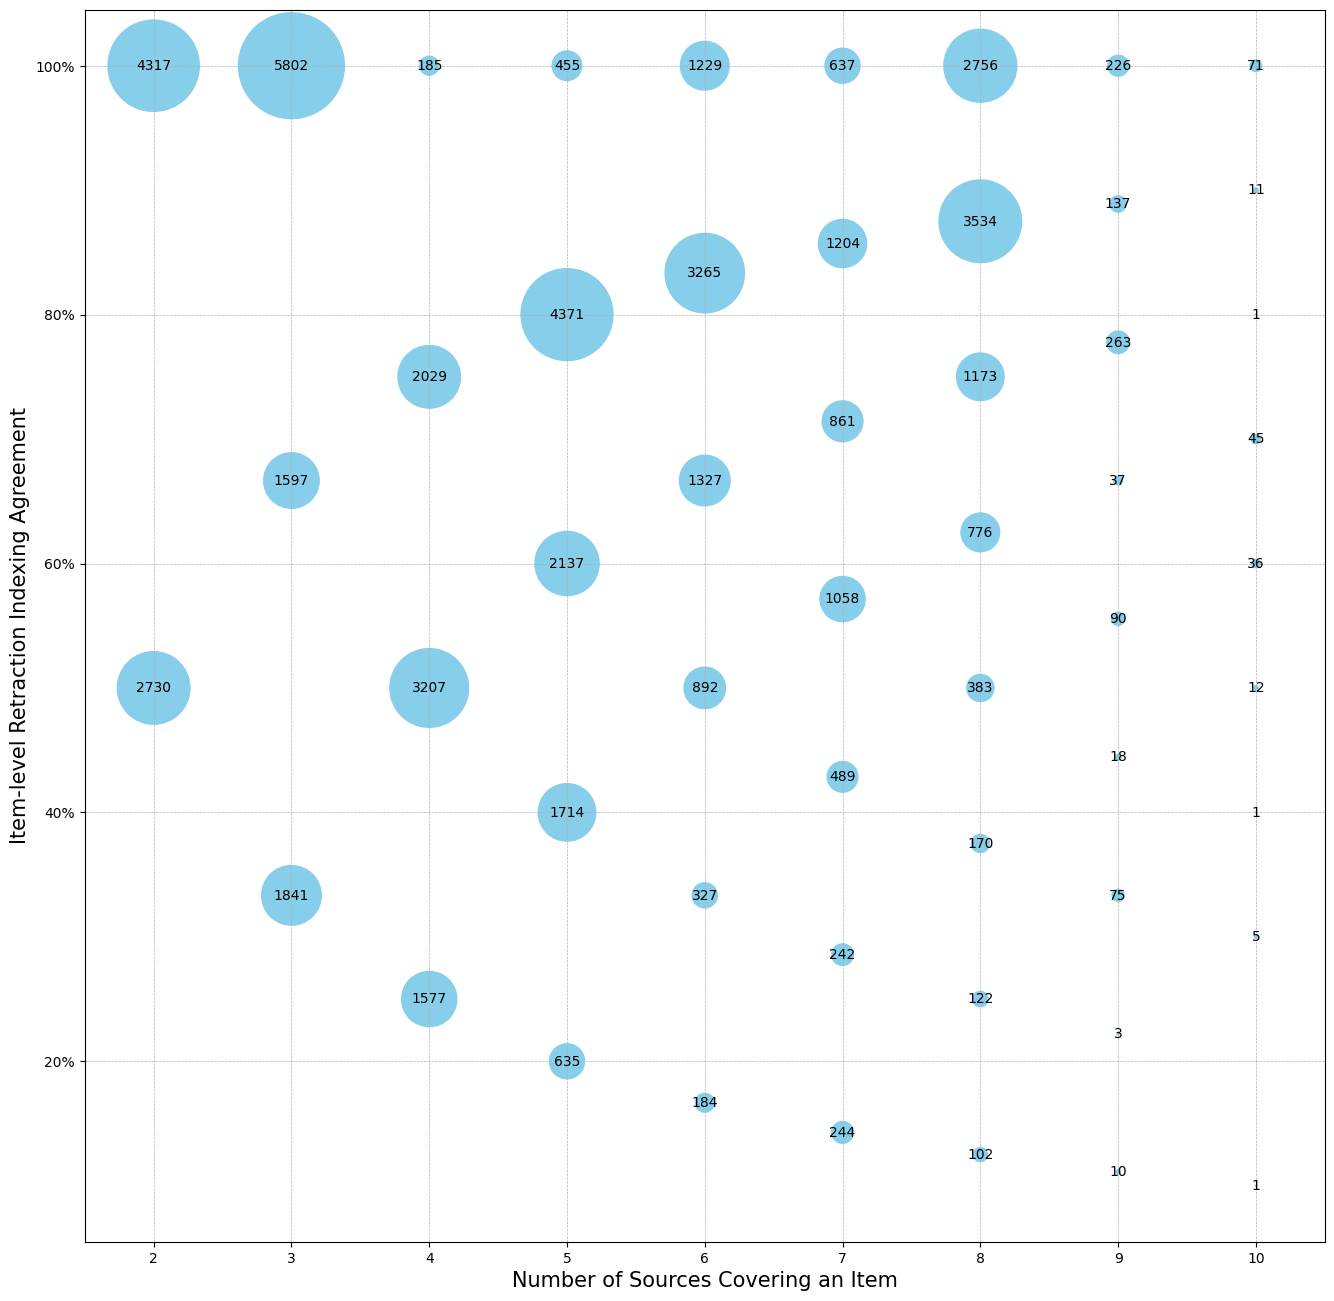

In [71]:
sns.reset_orig()

x_without_100 = []
y_without_100 = []
dot_size_without_100 = []

for key_coord, value_count in count_dictionary.items():
    if (key_coord[0]==1) & (key_coord[1]==100.0): # i.e. if RIA = 100% and source = 1, remove it from the sample
        continue
    else:
        x_without_100.append(key_coord[0])
        y_without_100.append(key_coord[1])
        dot_size_without_100.append(value_count)
    

plt.figure(figsize=(16,16))
plt.scatter(x_without_100,
            y_without_100,
            s=dot_size_without_100,
            alpha=1,
            color='skyblue')
plt.xlabel("Number of Sources Covering an Item", 
           fontsize=15)
plt.ylabel("Item-level Retraction Indexing Agreement",  # old label: \n(# of sources indexing an item / # of sources covering an item)
           fontsize=15)
plt.grid(linestyle='--', linewidth=0.5)
plt.xlim(left=min(x_without_100)-0.5, right=max(x_without_100)+0.5)
plt.gca().xaxis.set_major_locator(tck.MultipleLocator())
plt.gca().yaxis.set_major_formatter(tck.PercentFormatter())
for key_coord, value_count in count_dictionary.items():
    x_annotate = key_coord[0]
    y_annotate = key_coord[1]
    plt.annotate(value_count,
                 (x_annotate, y_annotate),
                  horizontalalignment='center',
                  verticalalignment='center',
                )
plt.savefig(result_dir+'RIA_vs_coverage_scatterplot.png')
plt.show()

## Section 4: Calculation of Publication and Retraction Year Distribution

In [72]:
"""
Calculating cummulative percentage
"""
cummlative_totalpubs= unionlist3.groupby(['Year'])['DOI'].agg('count').reset_index()\
                        .rename(columns={'DOI': 'No_of_DOIs'})
cummlative_totalpubs['DOICumulativeFreq']= cummlative_totalpubs['No_of_DOIs'].cumsum()

cummlative_totalpubs.max = cummlative_totalpubs['DOICumulativeFreq'].max()

cummlative_totalpubs['CumulativePercentage'] = (cummlative_totalpubs['DOICumulativeFreq'] / cummlative_totalpubs.max * 100).round(2)

cummlative_totalpubs

,Year,No_of_DOIs,DOICumulativeFreq,CumulativePercentage
0,1940,1,1,0.00
1,1942,1,2,0.00
2,1951,1,3,0.01
3,1959,1,4,0.01
4,1962,1,5,0.01
...,...,...,...,...
58,2020,3861,40300,68.78
59,2021,6767,47067,80.32
60,2022,10184,57251,97.70
61,2023,1202,58453,99.76


In [73]:
# Calculating Cummulative Frequency of the Time to Retraction

mask1=(unionlist3['TimetoRetraction']>=0) 

cumulative_retractiongap = unionlist3[mask1]['TimetoRetraction'].value_counts().sort_index().cumsum()
# print(cumulative_retractiongap)

cumulative_retractiongap= cumulative_retractiongap.reset_index().rename(
    columns={'count':'TimetoRetractionCumFreq'})

cumulative_retractiongap.max=  cumulative_retractiongap['TimetoRetractionCumFreq'].max()

cumulative_retractiongap['CumulativePercentage'] = (cumulative_retractiongap['TimetoRetractionCumFreq'] / cumulative_retractiongap.max * 100).round(2)

cumulative_retractiongap


,TimetoRetraction,TimetoRetractionCumFreq,CumulativePercentage
0,0,8378,21.28
1,1,21607,54.87
2,2,27772,70.52
3,3,31045,78.84
4,4,33178,84.25
5,5,34544,87.72
6,6,35624,90.46
7,7,36388,92.40
8,8,36986,93.92
9,9,37426,95.04


In [74]:
"""
Exploding Indexed Retracted Sources by year
"""
# Copying dataframe 
df = unionlist3.copy()

# Exploding Sources in 'source_old'
explode_source_old = df.explode('source_old')
df_explode_source_old= explode_source_old.groupby(['Year', 'source_old'])['DOI'].agg('count').reset_index()

df_explode_source_old.replace('Medline','MEDLINE', inplace=True)
df_explode_source_old.replace('WoS_Core','Web of Science Core', inplace=True)

df_explode_source_old

,Year,source_old,DOI
0,1940,Retraction Watch,1
1,1940,Scopus,1
2,1940,Web of Science Core,1
3,1942,Retraction Watch,1
4,1942,Scopus,1
...,...,...,...
394,2024,MEDLINE,63
395,2024,PubMed,66
396,2024,Retraction Watch,48
397,2024,Scopus,81


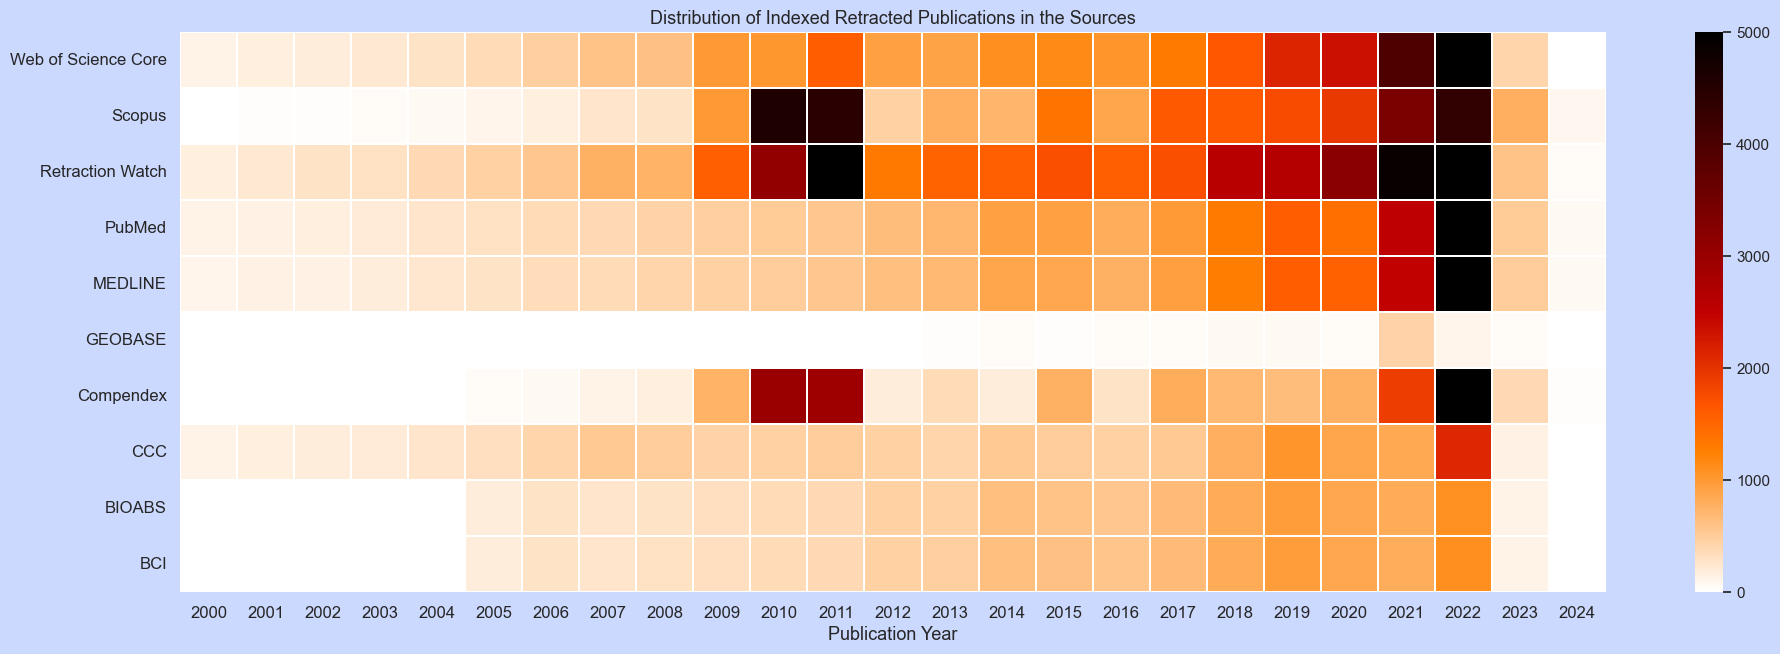

In [75]:
"""
Plotting retraction indexing distribution in sources using HeatMap
"""

# Filtering early year with low retracted publications: between 2000 and 2024
df_explode_source_old_rs = df_explode_source_old[(df_explode_source_old['Year']>=2000)] 
df_explode_source_old_rs

sns.set_theme()

# Pivot the data
pivot_data03 = df_explode_source_old_rs.pivot_table(index='source_old', columns='Year', values='DOI', aggfunc='sum', fill_value=0)
pivot_data03.sort_values(by='source_old',ascending=False, inplace=True)

# Create the heatmap using seaborn
fig04= plt.figure(figsize=(18, 7))

# Update the heatmap with the new color bar
ax04= sns.heatmap(pivot_data03, annot=False, fmt='d', cmap='gist_heat_r', linewidths=0.05,vmin=0, vmax=5000, robust=True, )

ax04.set_xlabel('')
ax04.set_ylabel('')

# Set the font size of x-axis and y-axis labels
ax04.tick_params(axis='x', labelsize=12.)  # Font size for x-axis labels
ax04.tick_params(axis='y', labelsize=12.)  # Font size for y-axis labels

ax04.set_title('Distribution of Indexed Retracted Publications in the Sources', size=13)

# Set labels and title
ax04.set_xlabel('Publication Year', size=13)

# Remove the space outside the plot
plt.subplots_adjust(left=0.1, right=1.09, top=0.9, bottom=0.1)

# Rotate the y-axis labels
plt.setp(ax04.get_xticklabels(), rotation=360)
plt.setp(ax04.get_yticklabels(), rotation=360)

fig04.patch.set_facecolor('#ccd9ff')  # Set the background color of the figure

# Save to folder
plt.savefig(result_dir+'indexed_per_sources_distribution_heatmap.png')
plt.show()

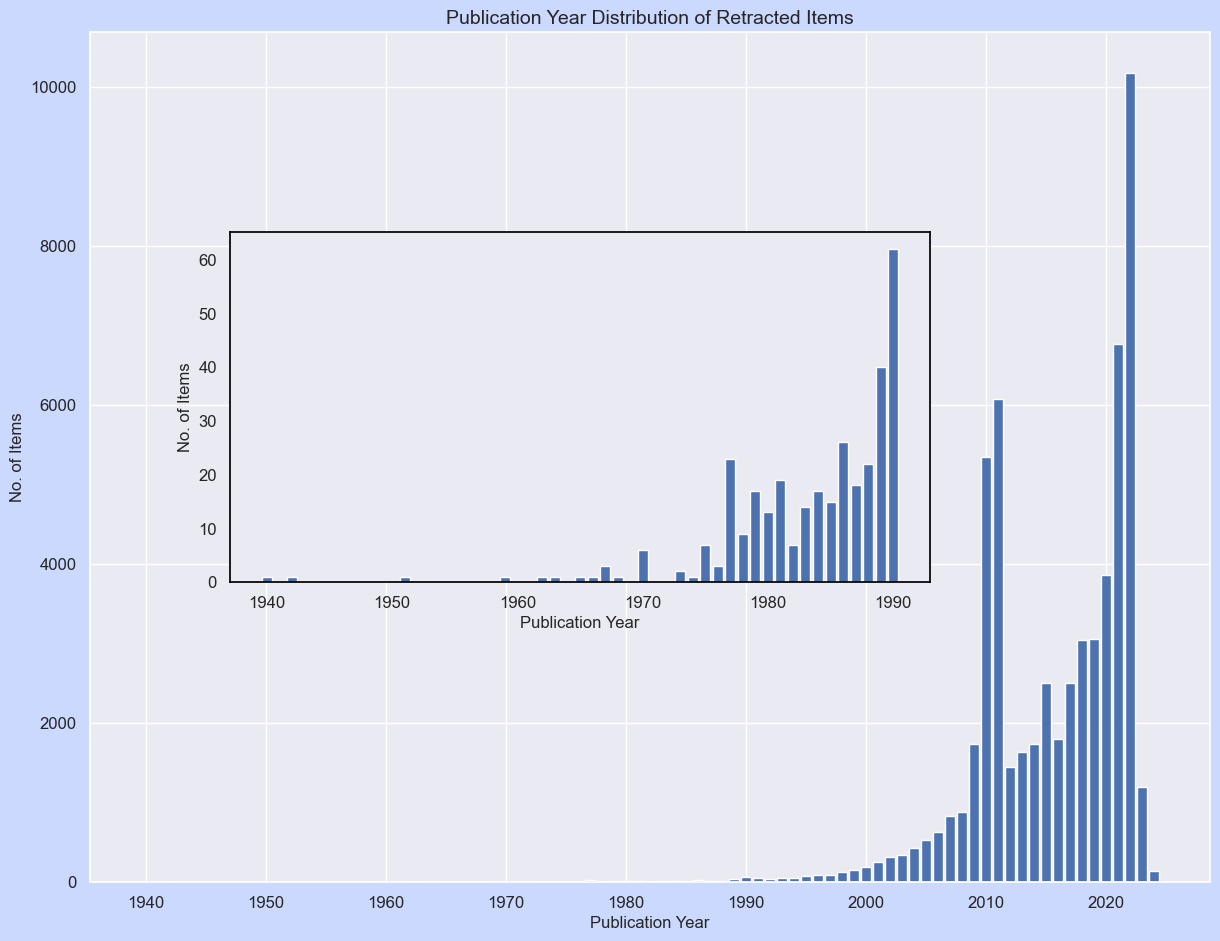

In [76]:
"""
Plotting Distribution of Total Retracted Publication
"""
fig04_0, ax04_0 = plt.subplots(figsize=(14, 10))

# Set the font size of x-axis and y-axis labels
ax04_0.tick_params(axis='x', labelsize=12.)  # Font size for x-axis labels
ax04_0.tick_params(axis='y', labelsize=12.) 

plt.bar(cummlative_totalpubs.Year, cummlative_totalpubs.No_of_DOIs) #(values, counts)
ax04_0.set_xticks(range(1940, 2024, 10))
plt.xlabel("Publication Year")
plt.ylabel("No. of Items")
plt.title("Publication Year Distribution of Retracted Items", size=14)

 # Add subplot inside highlighting retracted publication before 1991
sumDOIYear1= cummlative_totalpubs[cummlative_totalpubs['Year']<1991]
ax04_0 = fig04_0.add_axes([0.2, 0.4, 0.5, 0.35],  frameon=True,)  
for spine in ax04_0.spines.values():
    spine.set_edgecolor('black')
    
ax04_0.bar(sumDOIYear1.Year, sumDOIYear1.No_of_DOIs)
ax04_0.set_xticks(range(1940, 1991,10))
#ax0.xaxis.set_major_locator(MaxNLocator(integer=True))

# # Add labels and title
ax04_0.set_xlabel("Publication Year")
ax04_0.set_ylabel("No. of Items")

# Set the font size of x-axis and y-axis labels
ax04_0.tick_params(axis='x', labelsize=12.)  # Font size for x-axis labels
ax04_0.tick_params(axis='y', labelsize=12.) 

ax04_0.grid(False)

fig04_0.patch.set_facecolor('#ccd9ff') 

# Remove the space outside the plot
plt.subplots_adjust(left=0.1, right=0.9, top=0.95, bottom=0.1)

# Saving
plt.savefig(result_dir+'distribution_all_indexed_retracted_pubyear.png')

# Display the plot
plt.show()

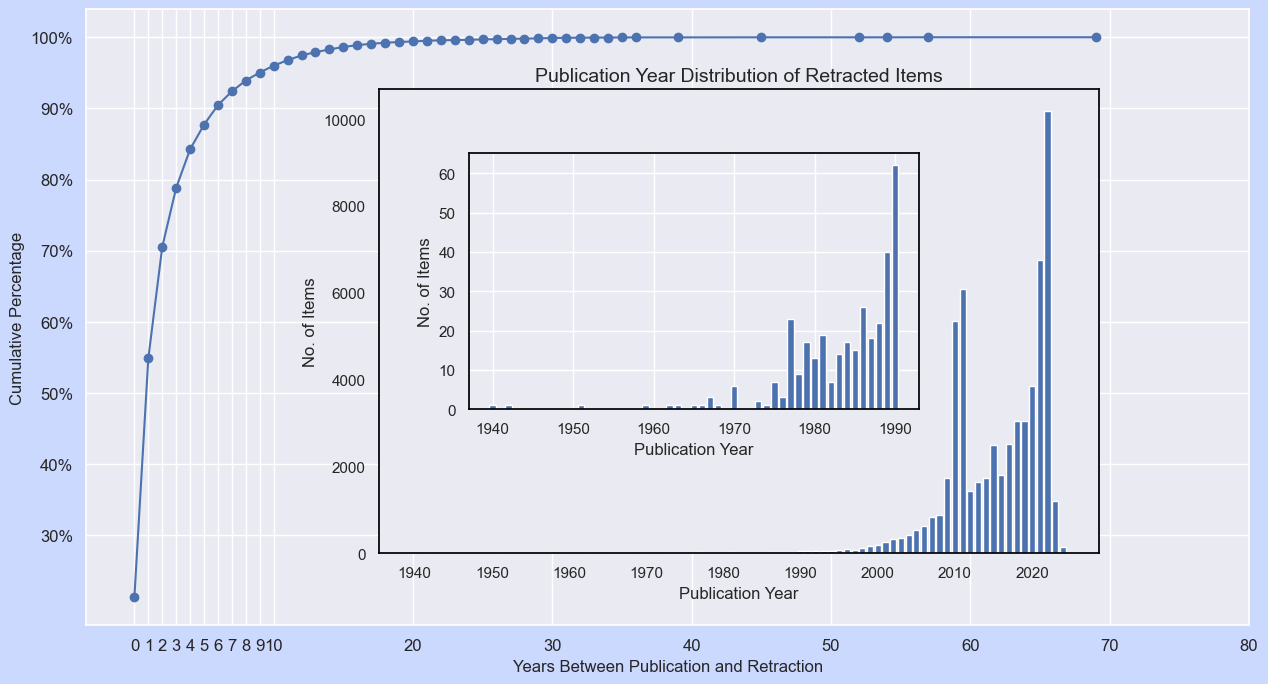

In [77]:
# Using this adjusted one
"""
Plotting Cumulative Time Between Publication Year and Retraction Year, 
And Plotting Distribution of Publication Year
"""

from matplotlib.ticker import PercentFormatter
fig05, ax05 = plt.subplots(figsize=(15,8))

"""
Plotting Cummulative data of Retraction Year
"""
ax05.plot(cumulative_retractiongap['TimetoRetraction'],cumulative_retractiongap['CumulativePercentage'], marker='o', linestyle='-')

#Set x- & y-axes ticks 
ax05.set_yticks(range(30, 110,10))
ax05.set_xticks([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 20, 30, 40, 50, 60, 70, 80])

# Set y-axis ticks at intervals of 10%
ax05.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))

#Customize the plot
# ax05.set_title('Cumulative Plot of Years Between Publication and Retraction', size=14)
ax05.set_xlabel('Years Between Publication and Retraction')
ax05.set_ylabel('Cumulative Percentage')

# Set the font size of x-axis and y-axis labels
ax05.tick_params(axis='x', labelsize=12.)  # Font size for x-axis labels
ax05.tick_params(axis='y', labelsize=12.) 


"""
The Larger Bar Chart
"""
#[0.3, 0.2, 0.55, 0.6]
ax05_0= fig05.add_axes([0.32, 0.2, 0.48, 0.58],  frameon=True,)  # [left, bottom, width, height]
for spine in ax05_0.spines.values():
    spine.set_edgecolor('black')

#Plotting bar for the Large Bar Chart
ax05_0.bar(cummlative_totalpubs.Year, cummlative_totalpubs.No_of_DOIs)
ax05_0.grid(False)

ax05_0.set_xticks(range(1940, 2024, 10))

# Add Title
ax05_0.set_title("Publication Year Distribution of Retracted Items", size=14)

# Add labels and title
ax05_0.set_xlabel("Publication Year")
ax05_0.set_ylabel("No. of Items")



fig05.patch.set_facecolor('#ccd9ff') 
ax05_0.set_xticks(range(1940, 2024, 10))

"""
The Smaller Bar Chart
"""
 # First new axes
sumDOIYear2= cummlative_totalpubs[cummlative_totalpubs['Year']<1991]
ax05_1 = fig05.add_axes([0.38, 0.38, 0.3, 0.32],  frameon=True)  
for spine1 in ax05_1.spines.values():
    spine1.set_edgecolor('black')
    
ax05_1.bar(sumDOIYear2.Year, sumDOIYear2.No_of_DOIs)
ax05_1.set_xticks(range(1940, 1991,10))

# Add labels and title
ax05_1.set_xlabel("Publication Year")
ax05_1.set_ylabel("No. of Items")

# Save to folder
plt.savefig(result_dir+'distribution_all_indexed_pubyear_and_retractedyear.png')
plt.show()



In [78]:
def check_source(sources_col: pd.Series, source: str)-> int:
    """
    This function takes either indexed column (source_old) or covered column (source_new) and checks
    if a given source is present for each item record. If it's present return 1 else return 0
    
    :param sources_col: the column to search to search in
    :param source: name of the source to check in the 'sources_col' column
    :return: 1 or 0
    """
    return sources_col.apply(lambda sources: 1 if source in sources else 0)

In [79]:
"""
Preparing the dataset for indexing & coverage of retracted publications by year graph
"""
sources_stats = unionlist3_adjusted[['DOI','Year']].copy() #pd.DataFrame()
# copied 'DOI' and 'Year' columns to append with each source's indexing and coverage check result

for source in sources_indexed:
    
    if source == 'Retraction Watch':
        continue # We do not need Retraction Watch since it indexes retracted papers only
    #print(source)
    source_= re.sub(r'\s', '', source).lower()
    indexed= source_+'_idx' # Adding 'idx' to source column with indexed items
    covered= source_+'_cov'# Adding 'cov' to source column with covered items
    #print(source, index, covered)
    
    # Checking indexing and coverage for each item
    sources_stats[indexed]=  check_source(unionlist3_adjusted['source_old'], source)
    sources_stats[covered]=  check_source(unionlist3_adjusted['source_new'], source)

# sources_stats= sources_stats[sources_stats['Year']<2024] # Filtered out year 2024

sources_stats

,DOI,Year,bci_idx,bci_cov,bioabs_idx,bioabs_cov,ccc_idx,ccc_cov,compendex_idx,compendex_cov,geobase_idx,geobase_cov,medline_idx,medline_cov,pubmed_idx,pubmed_cov,scopus_idx,scopus_cov,wos_core_idx,wos_core_cov
0,10.1001/archdermatol.2012.1796,2012,0,0,0,0,1,1,0,0,0,0,0,1,0,1,0,1,1,1
1,10.1001/archdermatol.2012.418,2012,0,0,0,0,0,1,0,0,0,0,1,1,1,1,0,0,0,0
2,10.1001/archinte.165.15.1737,2005,1,1,1,1,1,1,0,0,0,0,1,1,1,1,0,1,1,1
3,10.1001/archinte.165.15.1743,2005,1,1,1,1,1,1,0,0,0,0,1,1,1,1,0,1,1,1
4,10.1001/archinte.165.18.2142,2005,1,1,1,1,1,1,0,0,0,0,1,1,1,1,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58591,nodoi_95,1990,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0
58592,nodoi_96,1990,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0
58593,nodoi_97,1990,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0
58594,nodoi_98,1990,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0


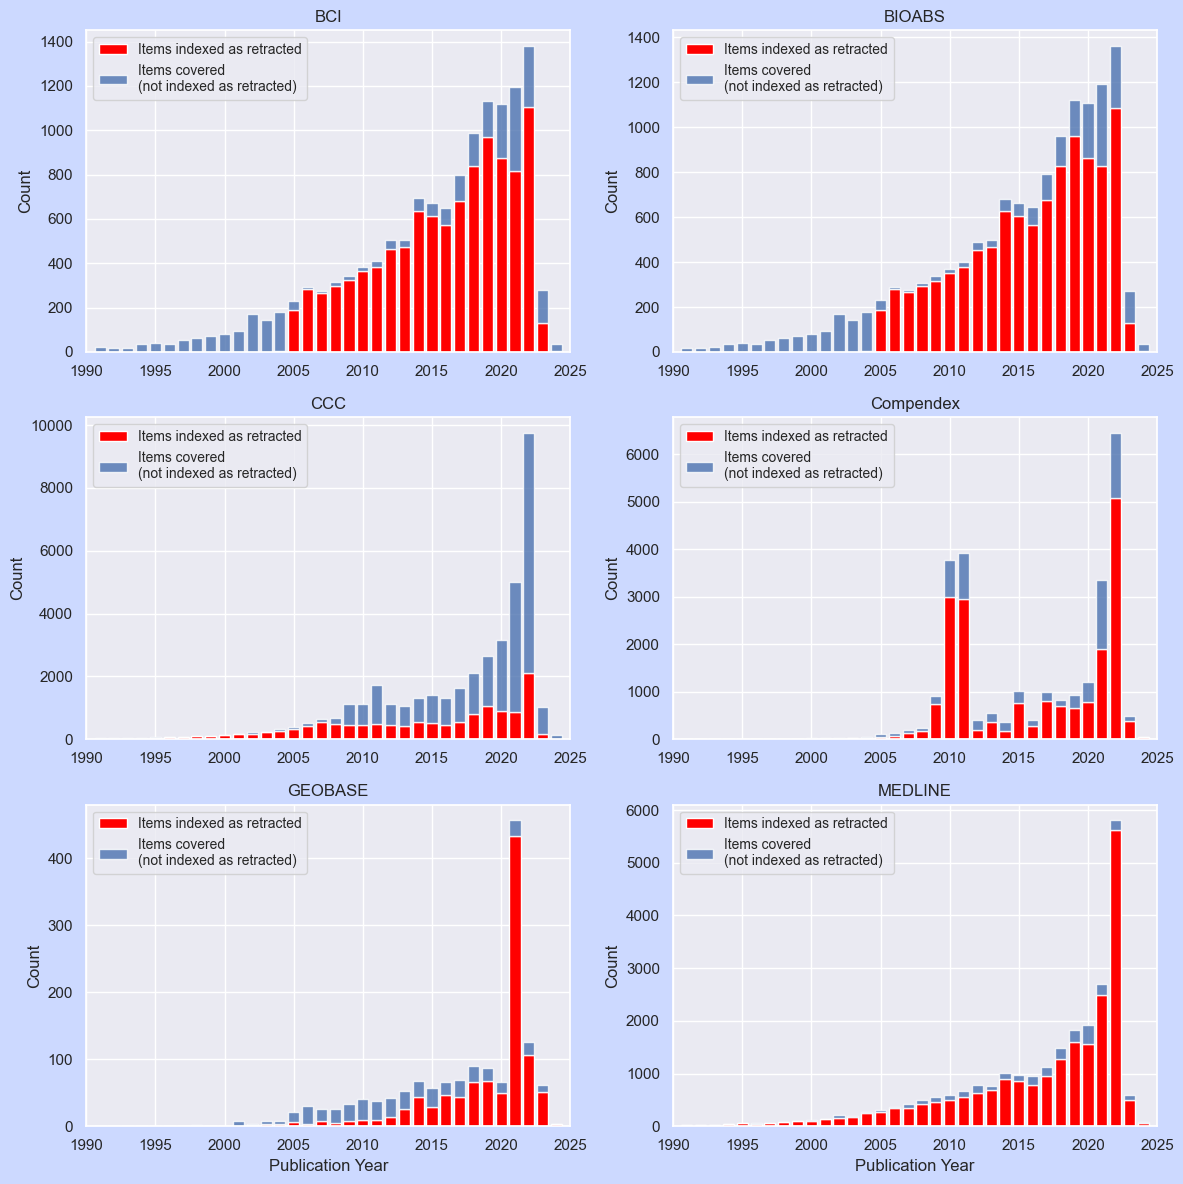

In [80]:
"""
Plotting Distribution of indexing & coverage of retracted publications by year -1 
"""
sns.set_theme()
fig06, axes = plt.subplots(nrows=3, ncols=2, figsize=(12, 12))


for i in range(len(sources_indexed[:6])): # For visibility can only show 6 subplots per figure
    source=sources_indexed[i].split()
    source= ''.join(source)
    source = sources_indexed[i].lower()
    
    source_= sources_indexed[i]
    
    if source_ == 'Medline':
        source_= 'MEDLINE'
    
    source = source.lower()
    indexed = source + '_idx'  # Adding 'idx' to source column with indexed items
    covered = source + '_cov'

    

    f_sources_stats= sources_stats[(sources_stats['Year'] > 1990)] 
    i_data = f_sources_stats.groupby(['Year'])[indexed].agg('sum').reset_index()[indexed]
    c_data = f_sources_stats.groupby(['Year'])[covered].agg('sum').reset_index()[covered]
    x_data = f_sources_stats.groupby(['Year']).agg('count').reset_index()['Year']

    y1 = i_data
    y2 = c_data - i_data # To avoid double-counting items indexed as retracted

    ax = axes[i//2, i%2]  # Get the appropriate subplot

    ax.bar(x_data, y1, label=f'Items indexed as retracted', color='red')  # crimson
    ax.bar(x_data, y2, bottom=y1, label=f'Items covered \n(not indexed as retracted)', alpha=0.8) #f'Items covered'

#   ax.set_xlabel('Publication Year')
    ax.set_ylabel('Count')
    ax.set_title(f'{source_}')
    
    # Set x-axis limits
    ax.set_xlim(1990, 2025)
    ax.legend(loc='upper left',  fontsize=10)
    
    # Only set x-axis label for subplots in the last row
    if i > 3:
        ax.set_xlabel('Publication Year')

# fig06.suptitle('Publication year and retraction year distribution of retracted publications')  
# ax05.grid(True)
fig06.patch.set_facecolor('#ccd9ff') 

plt.tight_layout()

# Save to folder
plt.savefig(result_dir+'distribution_of_indexed_and_covered_each_source1.png')
plt.show()



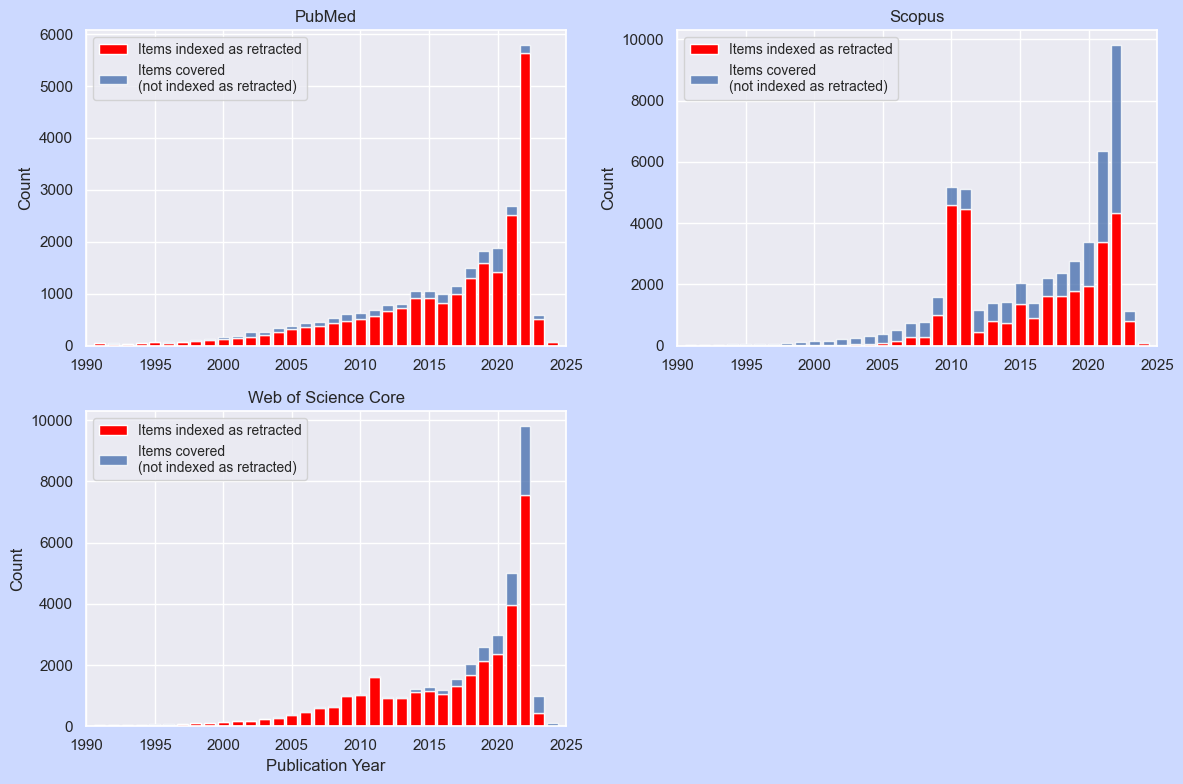

In [81]:
"""
Plotting Distribution of indexing & coverage of retracted publications by year -2
"""
sns.set_theme()
fig06_1, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))

sources_indexed2= sources_indexed[6:].copy()
sources_indexed2.remove('Retraction Watch') # Since all items in Retraction Watch are indexed as retracted

for i in range(len(sources_indexed2)):
    
    if sources_indexed2[i] == 'Retraction Watch':
        continue # We do not need Retraction Watch since it indexes retracted papers only. 
    
    source= sources_indexed2[i].split()
        
    source= ''.join(source)
    source = source.lower()
#    print(source)
    indexed = source + '_idx'  # Adding 'idx' to source column with indexed items
    covered = source + '_cov'
    
    source_= sources_indexed2[i]
    
    if source_ == 'Medline':
        source_= 'MEDLINE'
        
    if source_ == 'WoS_Core':
        source_= 'Web of Science Core'

    f_sources_stats= sources_stats[sources_stats['Year'] > 1990]
    i_data = f_sources_stats.groupby(['Year'])[indexed].agg('sum').reset_index()[indexed]
    c_data = f_sources_stats.groupby(['Year'])[covered].agg('sum').reset_index()[covered]
    x_data = f_sources_stats.groupby(['Year']).agg('count').reset_index()['Year']

    y1 = i_data
    y2 = c_data - i_data # To avoid double-counting items indexed as retracted

    ax = axes[i//2, i%2]  # Get the appropriate subplot

    ax.bar(x_data, y1, label=f'Items indexed as retracted', color='red')  # crimson {source_}
    ax.bar(x_data, y2, bottom=y1, label=f'Items covered \n(not indexed as retracted)', alpha=0.8) # in {source_} 

#     ax.set_xlabel('Publication Year')
    ax.set_ylabel('Count')
    ax.set_title(f'{source_}')
    
    # Only set x-axis label for subplots in the last row
    if i > 1:
        ax.set_xlabel('Publication Year')

    
    # Set x-axis limits
    ax.set_xlim(1990, 2025)
    ax.legend(loc='upper left',  fontsize=10)

# fig06_1.suptitle('Publication year and retraction year distribution of retracted publications')

#ax05.grid(True)
fig06_1.patch.set_facecolor('#ccd9ff') 
fig06_1.delaxes(axes[1, 1])

plt.tight_layout()

# Save to folder
plt.savefig(result_dir+'distribution_of_indexed_and_covered_each_source2.png')
plt.show()



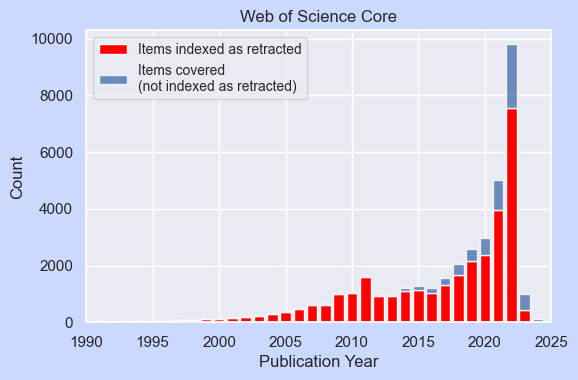

In [82]:
"""
Plotting Distribution of indexing & coverage of retracted publications by year -3
"""
sns.set_theme()
# Create a figure and axis
fig06_2, ax06_2 = plt.subplots(figsize=(6, 4))

source_= 'Web of Science Core'
indexed= 'wos_core_idx'
covered= 'wos_core_cov'

f_sources_stats= sources_stats[sources_stats['Year'] > 1990]
i_data = f_sources_stats.groupby(['Year'])[indexed].agg('sum').reset_index()[indexed]
c_data = f_sources_stats.groupby(['Year'])[covered].agg('sum').reset_index()[covered]
x_data = f_sources_stats.groupby(['Year']).agg('count').reset_index()['Year']

y1 = i_data
y2 = c_data - i_data # To avoid double-counting items indexed as retracted

# Create a stacked bar plot
ax06_2.bar(x_data, y1, label=f'Items indexed as retracted', color='red')  # crimson {source_}
ax06_2.bar(x_data, y2, bottom=y1, label=f'Items covered \n(not indexed as retracted) ', alpha=0.8) # in {source_}


ax06_2.set_xlabel('Publication Year')
ax06_2.set_ylabel('Count')
ax06_2.set_title(f'{source_}')

# Set x-axis limits
ax06_2.set_xlim(1990, 2025)
ax06_2.legend(loc='upper left',  fontsize=10)
fig06_2.subplots_adjust(bottom=0.15)

# ax06_2.set_xticks(range(x.min(), x.max(), 5))

fig06_2.patch.set_facecolor('#ccd9ff') 

# Save to folder
plt.savefig(result_dir+'distribution_of_indexed_and_covered_each_source3.png')
plt.show()


In [83]:
# copied 'DOI',and 'Year' columns to append with each sources result of indexing and coverage checking
"""
Plotting Distribution of coverage of retracted publications by for sources without indexing mechanism
"""

sources_covered_only= ['ADS', 'GeoRef', 'IEEE', 'Inspec', 'ScienceDirect', 'ZOOREC']

sources_stats2 = unionlist3[['DOI','Year']].copy() #pd.DataFrame()

for source in sources_covered_only:
    # print(source)
    source_= re.sub(r'\s', '', source).lower()
    covered= source_+'_cov'# Adding 'cov' to source column with covered items
    # print(source, covered)
    
    # Checking coverage for each item
    sources_stats2[covered]=  check_source(unionlist3['source_new'], source)

# sources_stats= sources_stats[sources_stats['Year']<2024] # Filtered out year 2024

sources_stats2

,DOI,Year,ads_cov,georef_cov,ieee_cov,inspec_cov,sciencedirect_cov,zoorec_cov
0,10.1001/archdermatol.2012.1796,2012,0,0,0,0,0,0
1,10.1001/archdermatol.2012.418,2012,0,0,0,0,0,0
2,10.1001/archinte.165.15.1737,2005,0,0,0,0,0,0
3,10.1001/archinte.165.15.1743,2005,0,0,0,0,0,0
4,10.1001/archinte.165.18.2142,2005,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...
58591,nodoi_95,1990,0,0,0,0,0,0
58592,nodoi_96,1990,0,0,0,0,0,0
58593,nodoi_97,1990,0,0,0,0,0,0
58594,nodoi_98,1990,0,0,0,0,0,0


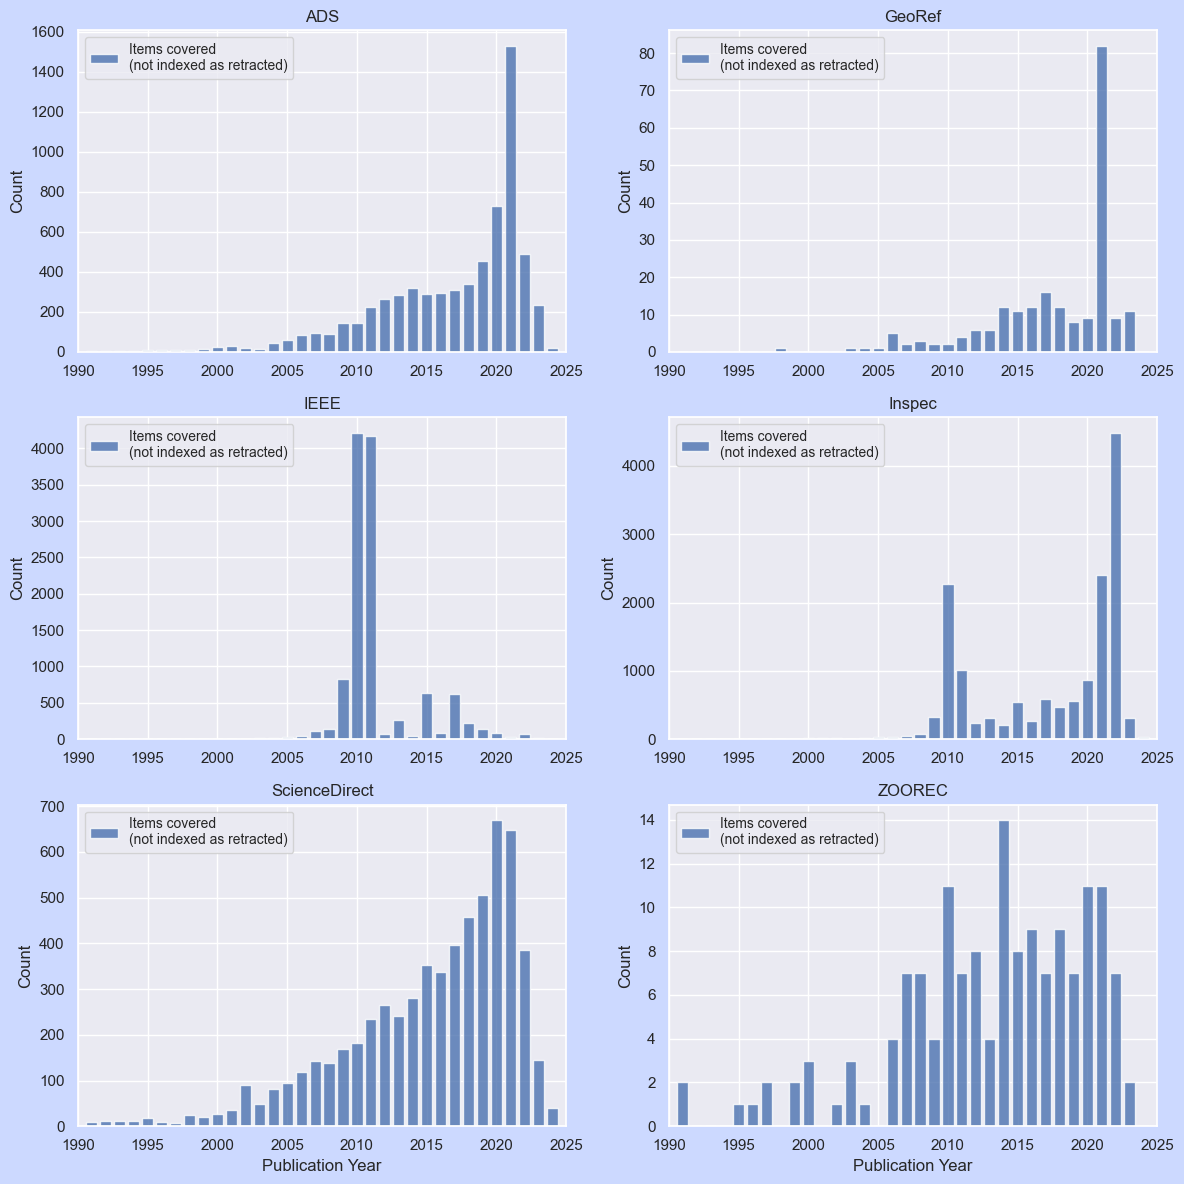

In [84]:
"""
Plotting Distribution of coverage of retracted publications by year -4
"""
sns.set_theme()
fig06_3, axes = plt.subplots(nrows=3, ncols=2, figsize=(12, 12))

for i in range(len(sources_covered_only)):
    
    source= sources_covered_only[i].split()
    source= ''.join(source)
    source = source.lower()
#     print(source)
    
    source_= sources_covered_only[i]

    covered = source + '_cov'

    f_sources_stats= sources_stats2[sources_stats['Year'] > 1990]
    c_data = f_sources_stats.groupby(['Year'])[covered].agg('sum').reset_index()[covered]
    x_data = f_sources_stats.groupby(['Year']).agg('count').reset_index()['Year']

 #   y1 = i_data
    y2 = c_data

    ax = axes[i//2, i%2]  # Get the appropriate subplot

#     ax.bar(x_data, y1, label=f'Items indexed as retracted', color='red')  # crimson {source_}
    ax.bar(x_data, y2, label=f'Items covered \n(not indexed as retracted)', alpha=0.8) # in {source_}

#     ax.set_xlabel('Publication Year')
    ax.set_ylabel('Count')
    ax.set_title(f'{source_}')
    
    # Set x-axis limits
    ax.set_xlim(1990, 2025)
    ax.legend(loc='upper left',  fontsize=10)
#     ax.set_xlabel('Publication Year')
    
    # Only set x-axis label for subplots in the last row
    if i > 3:
        ax.set_xlabel('Publication Year')


# fig06_3.suptitle('Publication year and retraction year distribution of retracted publications')

#ax05.grid(True)
fig06_3.patch.set_facecolor('#ccd9ff') 

fig06_3.subplots_adjust(hspace=0.4, wspace=0.7)
plt.tight_layout()

# Save to folder
plt.savefig(result_dir+'distribution_of_covered_only_each_source.png')
plt.show()

## Section 5: Intersection of Indexed Retracted Publication

In [85]:
"""
Computating the indexing status for sources
"""
unionlist3['source_new'] = unionlist3['source_new'].apply(str)
unionlist3['source_old'] = unionlist3['source_old'].apply(str)

compendex_doi= unionlist3[unionlist3['source_old'].str.contains('Compendex')]['DOI'].tolist()
geobase_doi= unionlist3[unionlist3['source_old'].str.contains('GEOBASE')]['DOI'].tolist()
pubmed_doi= unionlist3[unionlist3['source_old'].str.contains('PubMed')]['DOI'].tolist()
rw_doi= unionlist3[unionlist3['source_old'].str.contains('Retraction Watch')]['DOI'].tolist()
scopus_doi= unionlist3[unionlist3['source_old'].str.contains('Scopus')]['DOI'].tolist()

bci_doi= unionlist3[unionlist3['source_old'].str.contains('BCI')]['DOI'].tolist()
bioabs_doi= unionlist3[unionlist3['source_old'].str.contains('BIOABS')]['DOI'].tolist()
medline_doi= unionlist3[unionlist3['source_old'].str.contains('Medline')]['DOI'].tolist()
ccc_doi= unionlist3[unionlist3['source_old'].str.contains('CCC')]['DOI'].tolist()
woscore_doi= unionlist3[unionlist3['source_old'].str.contains('WoS_Core')]['DOI'].tolist()


In [86]:
"""
Computating the coverage status for sources
"""

compendex_doi_cov= unionlist3[unionlist3['source_new'].str.contains('Compendex')]['DOI'].tolist()
geobase_doi_cov= unionlist3[unionlist3['source_new'].str.contains('GEOBASE')]['DOI'].tolist()
pubmed_doi_cov= unionlist3[unionlist3['source_new'].str.contains('PubMed')]['DOI'].tolist()
rw_doi_cov= unionlist3[unionlist3['source_new'].str.contains('Retraction Watch')]['DOI'].tolist()
scopus_doi_cov= unionlist3[unionlist3['source_new'].str.contains('Scopus')]['DOI'].tolist()

bci_doi_cov= unionlist3[unionlist3['source_new'].str.contains('BCI')]['DOI'].tolist()
bioabs_doi_cov= unionlist3[unionlist3['source_new'].str.contains('BIOABS')]['DOI'].tolist()
medline_doi_cov= unionlist3[unionlist3['source_new'].str.contains('Medline')]['DOI'].tolist()
ccc_doi_cov= unionlist3[unionlist3['source_new'].str.contains('CCC')]['DOI'].tolist()
woscore_doi_cov= unionlist3[unionlist3['source_new'].str.contains('WoS_Core')]['DOI'].tolist()


/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  style

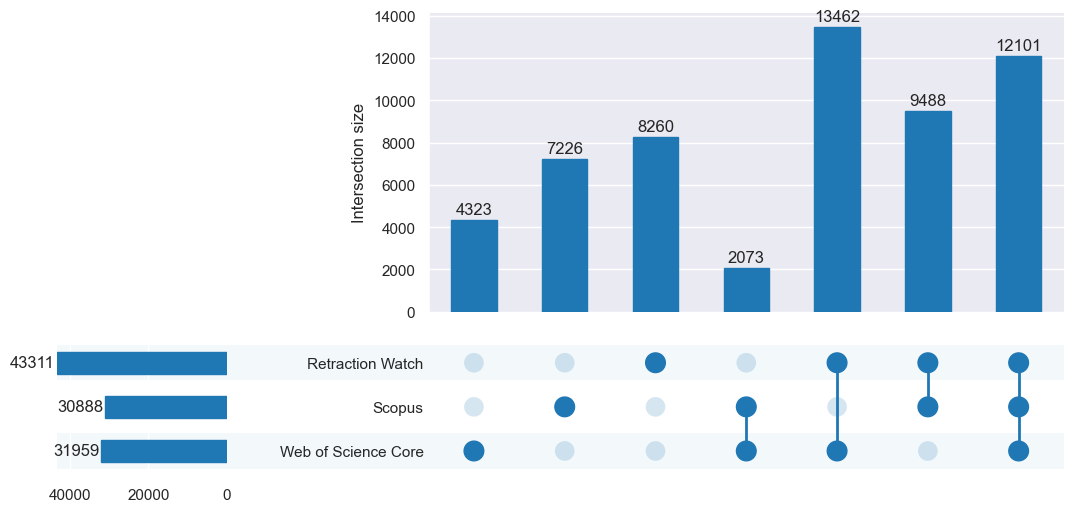

In [87]:
# Check current indexing status for STI2023 study
sns.set_theme()
from upsetplot import from_contents,plot
upset_sourceindexed_STI2023 = from_contents({
                                    'Retraction Watch': rw_doi, 
                                    'Scopus': scopus_doi,      
                                    'Web of Science Core': woscore_doi})


fig = plt.figure(figsize=(13, 6))
plot(upset_sourceindexed_STI2023, fig=fig, subset_size='count',show_counts=True,facecolor="#1f77b4",sort_categories_by='-input',element_size=None)

# plt.suptitle('Current indexing status of overlap of retracted items across databases in Schneider et al. (2023)', size=13)

# Saving
plt.savefig(result_dir+'indexed_sources_intersection_status_of_STI2023.png')
plt.show()



/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  style

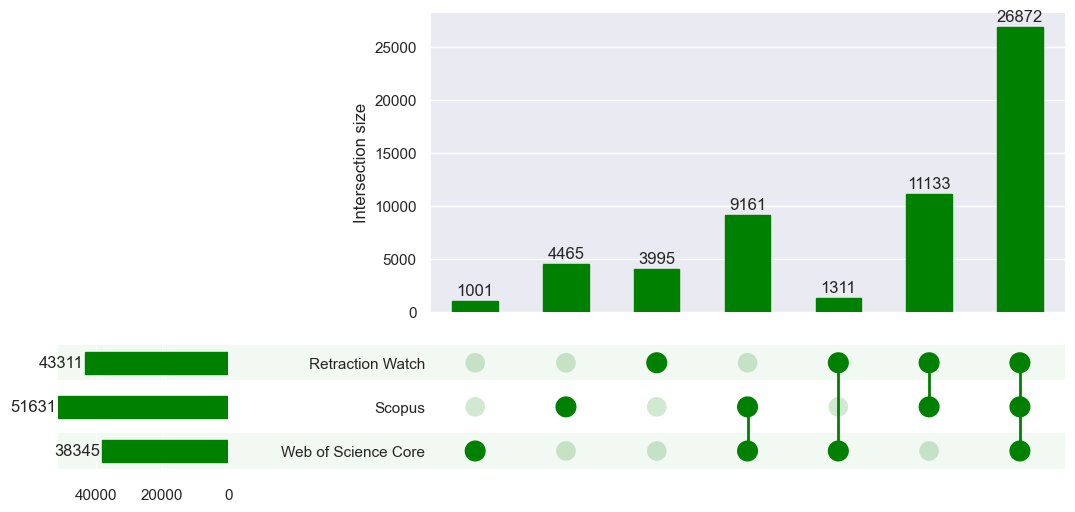

In [88]:
# Check current coverage status for STI2023 study
sns.set_theme()

upset_sourcecovered_STI2023 = from_contents({
                                    'Retraction Watch': rw_doi_cov, 
                                    'Scopus': scopus_doi_cov,      
                                    'Web of Science Core': woscore_doi_cov})


fig = plt.figure(figsize=(13, 6))
plot(upset_sourcecovered_STI2023, fig=fig, subset_size='count',show_counts=True,facecolor="green",sort_categories_by='-input',element_size=None)

# plt.suptitle('Current coverage (supposed indexed) status of overlap of retracted items across databases in Schneider et al. (2023)', size=13)

# Saving
plt.savefig(result_dir+'coverage_sources_intersection_status_of_STI2023.png')
plt.show()



/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  style

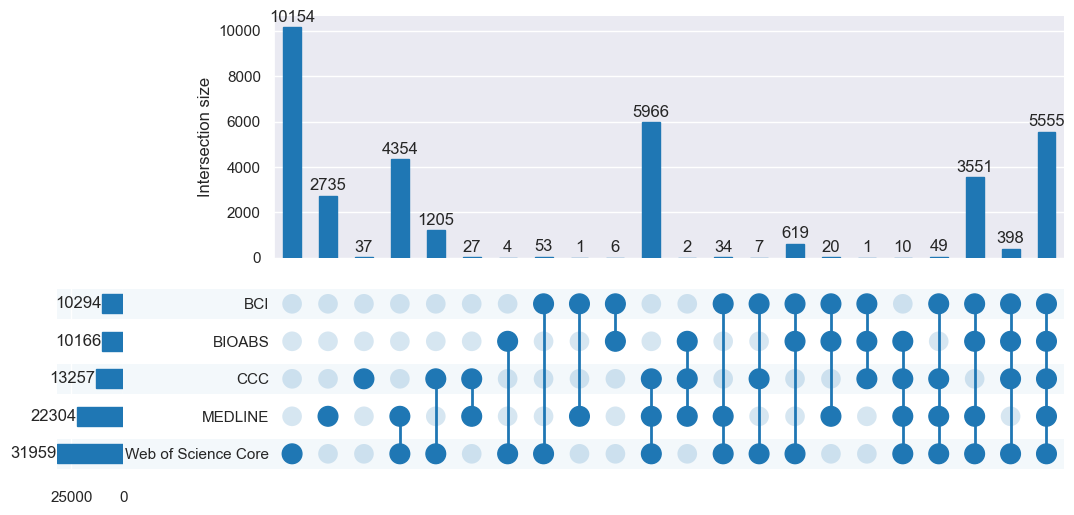

In [89]:
# Intersections of indexing retracted publications in Web of Science Platform

# plt.style.use('bmh')
sns.set_theme()

upset_sourceindexed1 = from_contents({'BCI': bci_doi,
                                    'BIOABS': bioabs_doi, 
                                    'CCC': ccc_doi,
                                    'MEDLINE': medline_doi,       
                                    'Web of Science Core': woscore_doi})


fig = plt.figure(figsize=(13, 6))
plot(upset_sourceindexed1, fig=fig, subset_size='count',show_counts=True,facecolor="#1f77b4",sort_categories_by='-input',element_size=None)

# plt.suptitle('Overlap of retracted items across databases on the Web of Science Platform', size=13)

# Saving
plt.savefig(result_dir+'indexed_sources_intersection_in_WoS.png')
plt.show()

/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  style

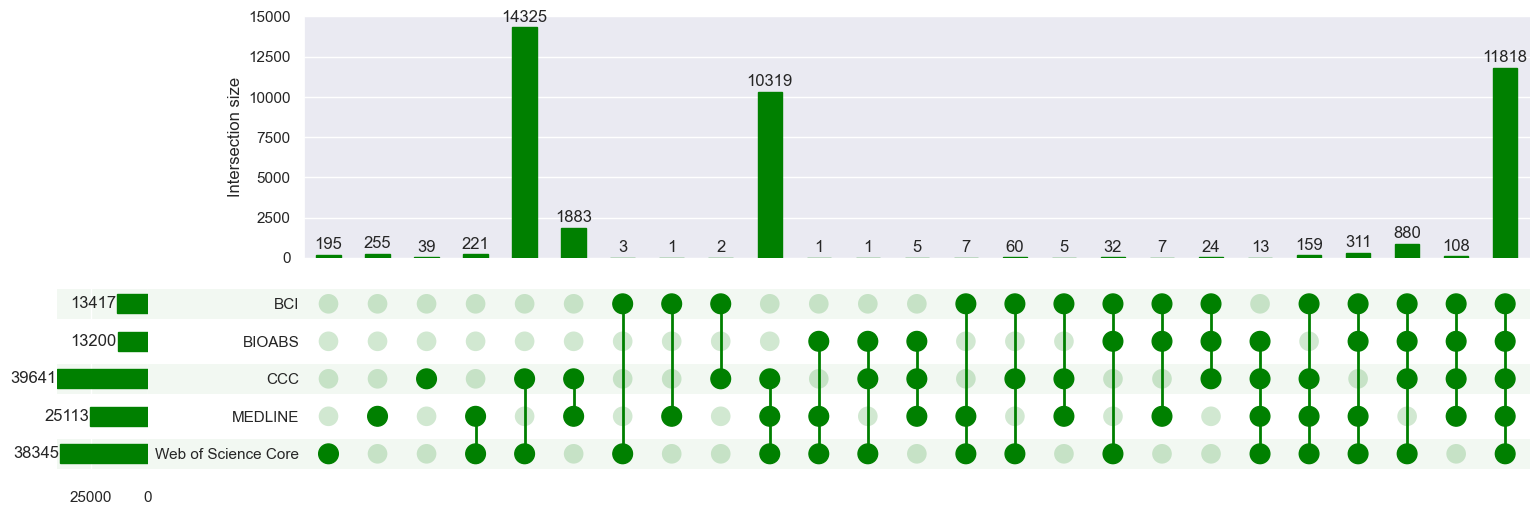

In [90]:
# Intersections of indexing retracted publications in Web of Science Platform

# plt.style.use('bmh')
sns.set_theme()

upset_sourcecovereded1 = from_contents({'BCI': bci_doi_cov,
                                    'BIOABS': bioabs_doi_cov, 
                                    'CCC': ccc_doi_cov,
                                    'MEDLINE': medline_doi_cov,       
                                    'Web of Science Core': woscore_doi_cov})


fig = plt.figure(figsize=(19, 6))
plot(upset_sourcecovereded1, fig=fig, subset_size='count',show_counts=True,facecolor="green",sort_categories_by='-input',element_size=None)

# plt.suptitle('Overlap of coverage status of retracted items across databases on the Web of Science Platform', size=13)

# Saving
plt.savefig(result_dir+'coverage_sources_intersection_in_WoS.png')
plt.show()


/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  style

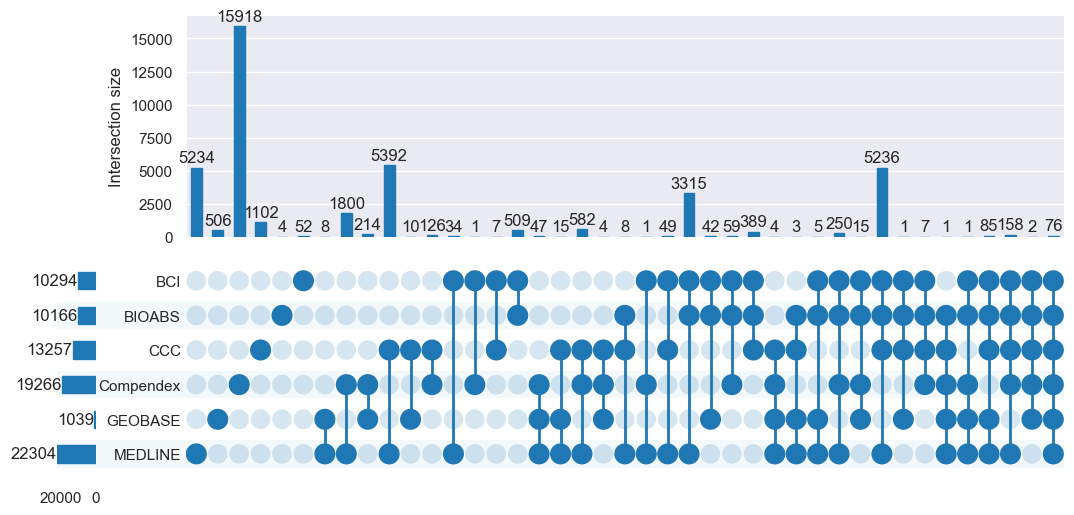

In [91]:
# Intersections of indexing retracted publications in Subject-Specific Databases

sns.set_theme()
upset_sourceindexed2 = from_contents({'BCI': bci_doi,
                                    'BIOABS': bioabs_doi, 
                                    'CCC': ccc_doi,
                                    'Compendex': compendex_doi,
                                    'GEOBASE': geobase_doi, 
                                    'MEDLINE': medline_doi,       
                                    })


fig = plt.figure(figsize=(13, 6))
plot(upset_sourceindexed2, fig=fig, subset_size='count',show_counts=True,facecolor="#1f77b4",sort_categories_by='-input',element_size=None)

# plt.suptitle('Overlap of retracted items across subject-specific databases', size=13)

# Saving
plt.savefig(result_dir+'overlap_between-subject_sources.png')
plt.show()


/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are 

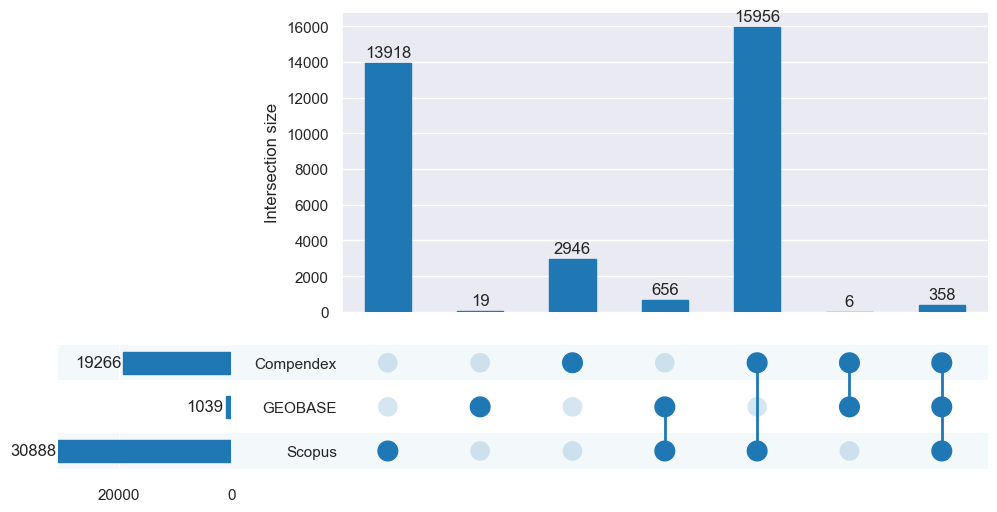

In [92]:
# Intersections indexed retracted items of Elsevier databases
sns.set_theme()

upset_sourceindexed3 = from_contents({'Compendex': compendex_doi,
                                        'GEOBASE': geobase_doi, 
                                        'Scopus': scopus_doi,})

fig = plt.figure(figsize=(12, 6))
plot(upset_sourceindexed3, fig=fig, subset_size='count',show_counts=True,facecolor="#1f77b4",sort_categories_by='-input',element_size=None)

# plt.suptitle('Overlap of retracted items across Elsevier databases', size=13)

# fig.patch.set_facecolor('#ccd9ff') 

# Saving
plt.savefig(result_dir+'indexed_sources_intersection_in_Elsevier.png')
plt.show()
             


/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  style

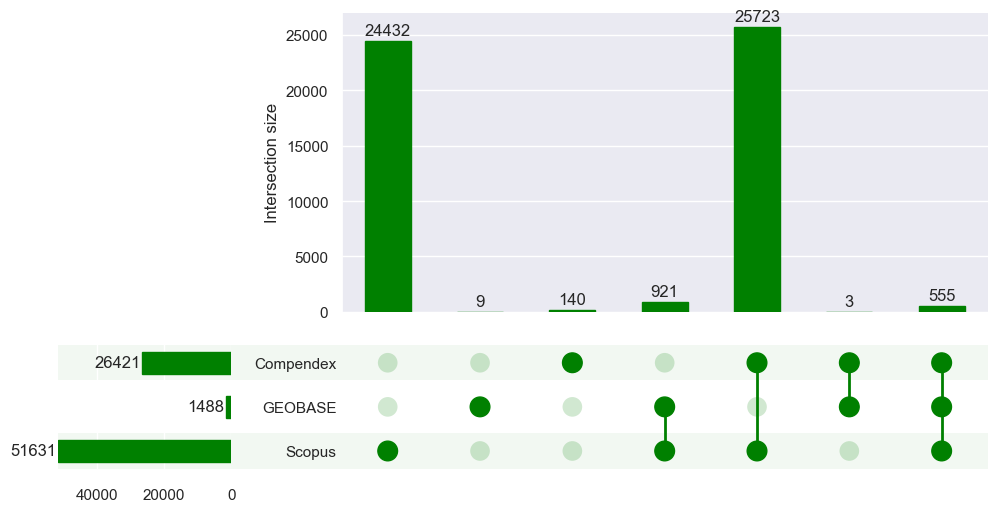

In [93]:
# Intersections coverage status of indexed retracted items of Elsevier databases
sns.set_theme()

upset_sourceindexed3 = from_contents({'Compendex': compendex_doi_cov,
                                        'GEOBASE': geobase_doi_cov, 
                                        'Scopus': scopus_doi_cov,})

fig = plt.figure(figsize=(12, 6))
plot(upset_sourceindexed3, fig=fig, subset_size='count',show_counts=True,facecolor="green",sort_categories_by='-input',element_size=None)

# plt.suptitle('Overlap of coverage status of retracted items across Elsevier databases', size=13)

# fig.patch.set_facecolor('#ccd9ff') 

# Saving
plt.savefig(result_dir+'coverage_sources_intersection_in_Elsevier.png')
plt.show()



/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  style

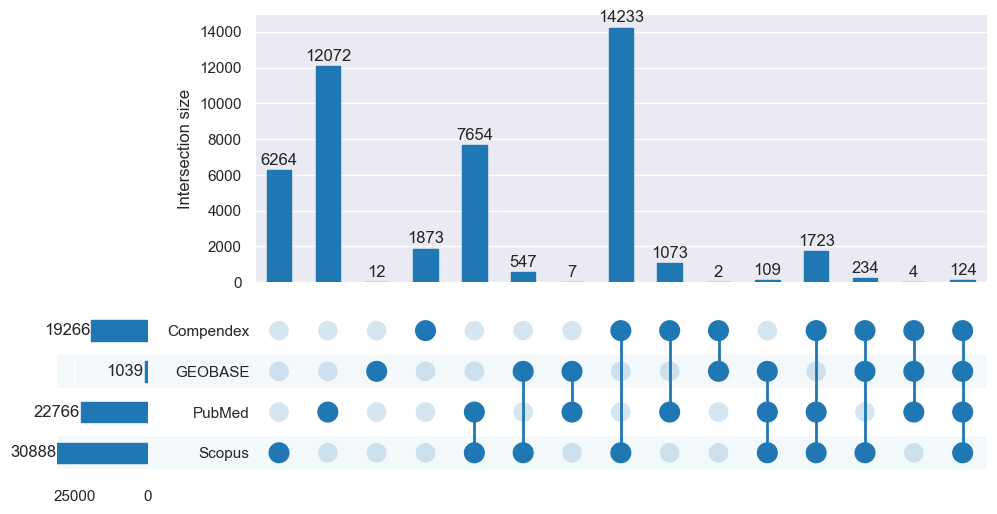

In [94]:
# Intersections of indexed retracted items of Elsevier and PubMed databases

sns.set_theme()

upset_sourceindexed4 = from_contents({'Compendex': compendex_doi,
                                    'GEOBASE': geobase_doi, 
                                    'PubMed': pubmed_doi,
                                    'Scopus': scopus_doi,})

fig = plt.figure(figsize=(12, 6))
plot(upset_sourceindexed4, fig=fig, subset_size='count',show_counts=True,facecolor="#1f77b4",sort_categories_by='-input',element_size=None)

# plt.suptitle('Overlap of retracted items across databases of Elsevier and PubMed', size=13)

# fig.patch.set_facecolor('#ccd9ff') 

# Saving
plt.savefig(result_dir+'indexed_sources_intersection_in_Elsevier_and_PubMed.png')
plt.show()



/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  style

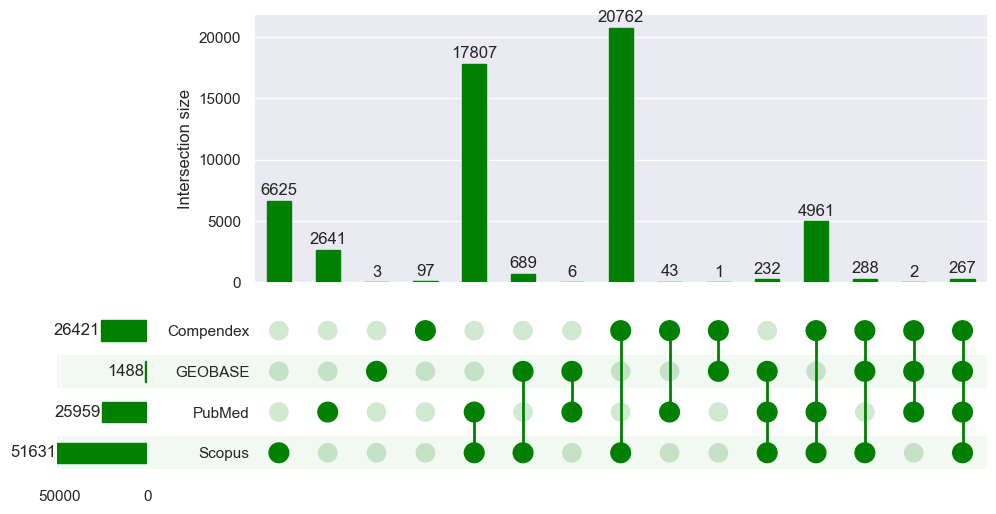

In [95]:
# Intersections coverage status of indexed retracted items of Elsevier and PubMed databases

sns.set_theme()

upset_sourcecovered4 = from_contents({'Compendex': compendex_doi_cov,
                                    'GEOBASE': geobase_doi_cov, 
                                    'PubMed': pubmed_doi_cov,
                                    'Scopus': scopus_doi_cov,})

fig = plt.figure(figsize=(12, 6))
plot(upset_sourcecovered4, fig=fig, subset_size='count',show_counts=True,facecolor="green",sort_categories_by='-input',element_size=None)

# plt.suptitle('Overlap of retracted items across databases of Elsevier and PubMed', size=13)

# fig.patch.set_facecolor('#ccd9ff') 

# Saving
plt.savefig(result_dir+'covered_sources_intersection_in_Elsevier_and_PubMed.png')

plt.show() 



/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  style

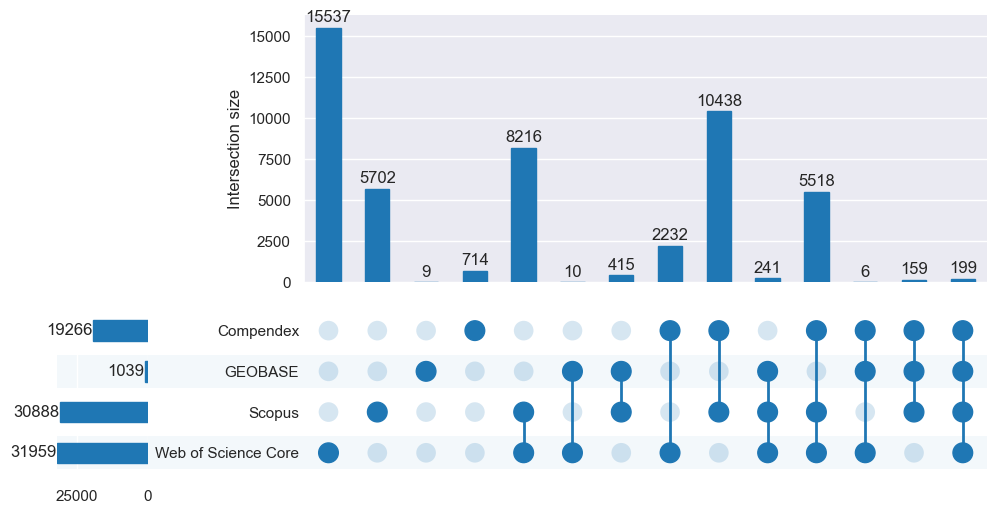

In [96]:
# Intersections of indexed retracted items of Elsevier and Web of Science Core databases
sns.set_theme()

upset_sourceindexed5 = from_contents({'Compendex': compendex_doi,
                                    'GEOBASE': geobase_doi, 
                                    'Scopus': scopus_doi,
                                     'Web of Science Core': woscore_doi})

fig = plt.figure(figsize=(12, 6))
plot(upset_sourceindexed5, fig=fig, subset_size='count',show_counts=True,facecolor="#1f77b4",sort_categories_by='-input',element_size=None)

# plt.suptitle('Overlap of retracted items across databases of Elsevier and Web of Science Core', size=13)

# fig.patch.set_facecolor('#ccd9ff') 

# Saving
plt.savefig(result_dir+'indexed_sources_intersection_in_Elsevier_and_WoS.png')
plt.show()



/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  style

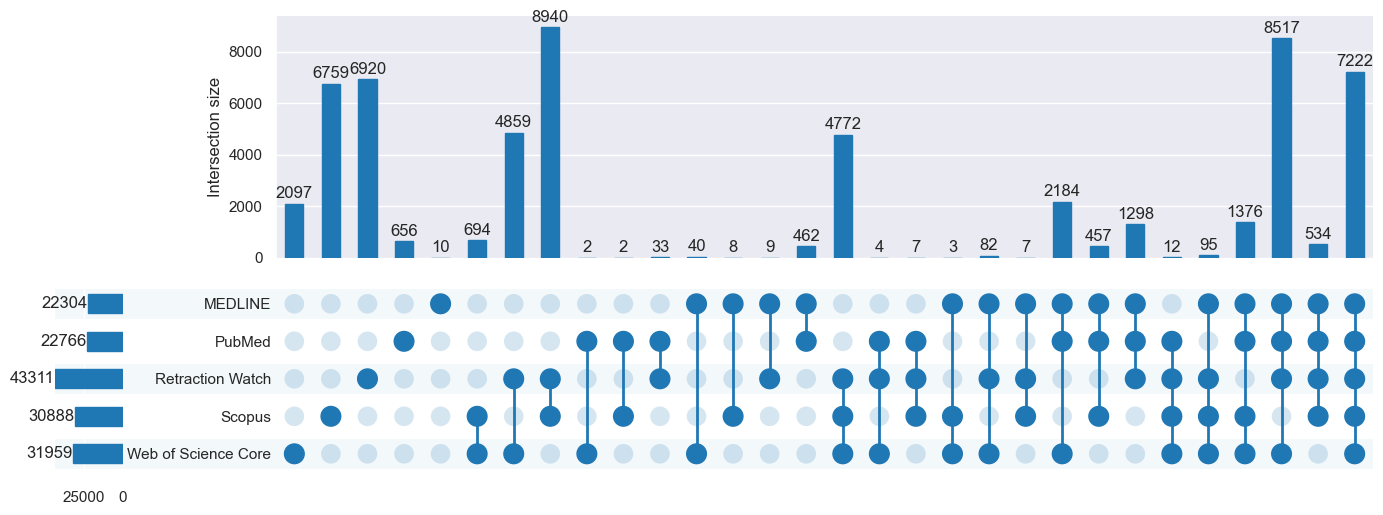

In [97]:
# Intersections of Multidisciplinary Sources Vs. PubMed
sns.set_theme()

upset_sourceindexed2 = from_contents({
                                    'MEDLINE': medline_doi,
                                    'PubMed': pubmed_doi, 
                                    'Retraction Watch': rw_doi,       
                                    'Scopus': scopus_doi, 
                                    'Web of Science Core': woscore_doi})

fig = plt.figure(figsize=(17,6))
plot(upset_sourceindexed2, fig=fig, subset_size='count',show_counts=True,facecolor="#1f77b4",sort_categories_by='-input',element_size=None)

# plt.suptitle('Overlap of retracted items across multidisciplinary and PubMed sources', size=13)

# fig1_1.patch.set_facecolor('#ccd9ff') 

# Saving
plt.savefig(result_dir+'indexed_sources_intersection_multidisc+pubmed.png')

plt.show()

/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  style

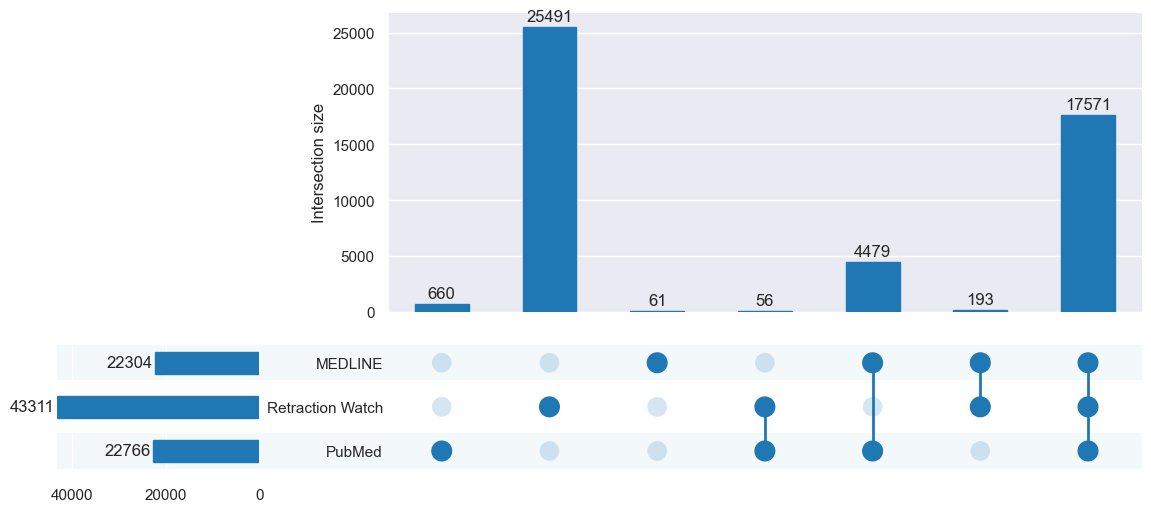

In [98]:
# Intersections of Multidisciplinary Sources Vs. MEDLINE and PubMed
sns.set_theme()

upset_sourceindexed2 = from_contents({
                                    'MEDLINE': medline_doi,
                                    'Retraction Watch': rw_doi,       
                                    'PubMed': pubmed_doi, 
                                    })

fig = plt.figure(figsize=(14, 6))
plot(upset_sourceindexed2, fig=fig, subset_size='count',show_counts=True,facecolor="#1f77b4",sort_categories_by='-input',element_size=None)


# plt.suptitle('Overlap of retracted items across multidisciplinary, MEDLINE and PubMed sources', size=13)


# Saving
plt.savefig(result_dir+'indexed_sources_intersection_multidisc_and_Medline+PubMed.png')
plt.show()




/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/Users/malikslam/anaconda3/envs/is557/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  style

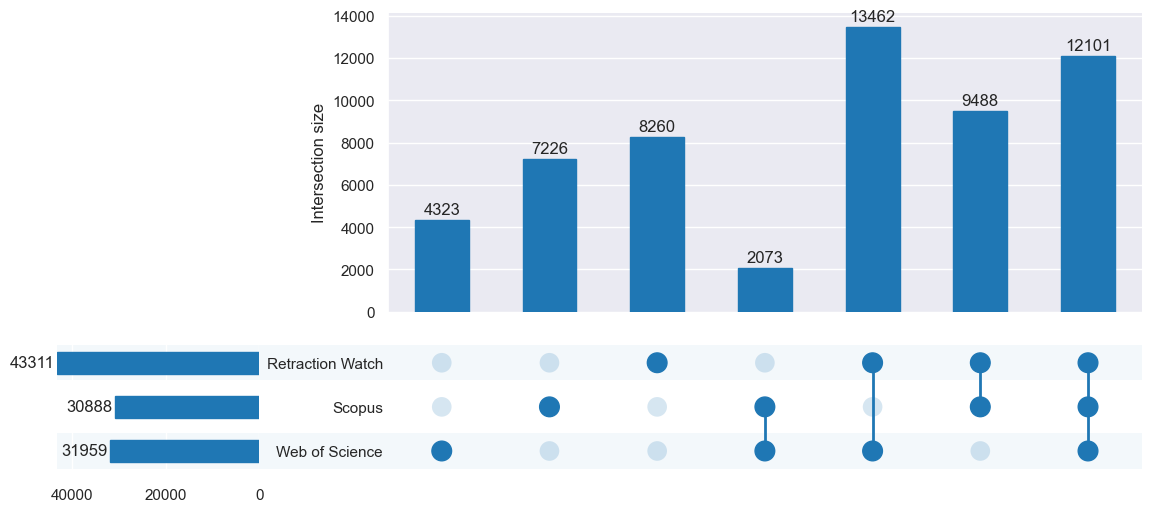

In [99]:
# Intersections of Major Multidisciplinary Sources
sns.set_theme()

upset_sourceindexed2 = from_contents({
                                    'Retraction Watch': rw_doi,       
                                    'Scopus': scopus_doi, 
                                    'Web of Science': woscore_doi})

fig = plt.figure(figsize=(14, 6))
plot(upset_sourceindexed2, fig=fig, subset_size='count',show_counts=True,facecolor="#1f77b4",sort_categories_by='-input',element_size=None)


# plt.suptitle('Overlap of retracted items across major multidisciplinary sources', size=13)

# Saving
plt.savefig(result_dir+'indexed_sources_intersection_multidisc.png')
plt.show()



## Section 6: Journal Categorization Distribution

In [100]:
# Replace uncategorized fill items with "notcategorized"
unionlist3_adjusted['MainCategory']= unionlist3_adjusted['MainCategory'].fillna('notcategorized')

In [101]:
cat = ['General', 'Health Science', 'Life Science', 'Physical Science', 'Social Science','notcategorized']
cat_3 = ['General', 'Health \nScience', 'Life \nScience', 'Physical \nScience', 'Social \nScience', 'Not \nCategorized']

count=[]
for i in cat:
    counts = unionlist3_adjusted.MainCategory.str.count(i).sum()
    count.append(counts)

df_field = pd.DataFrame({'Fields of Study': cat_3, 'Count': count}).sort_values('Count', ascending=False)#.set_index(df.columns[0])
df_field

,Fields of Study,Count
3,Physical \nScience,38387
2,Life \nScience,33281
1,Health \nScience,32924
4,Social \nScience,22166
5,Not \nCategorized,2183
0,General,1677


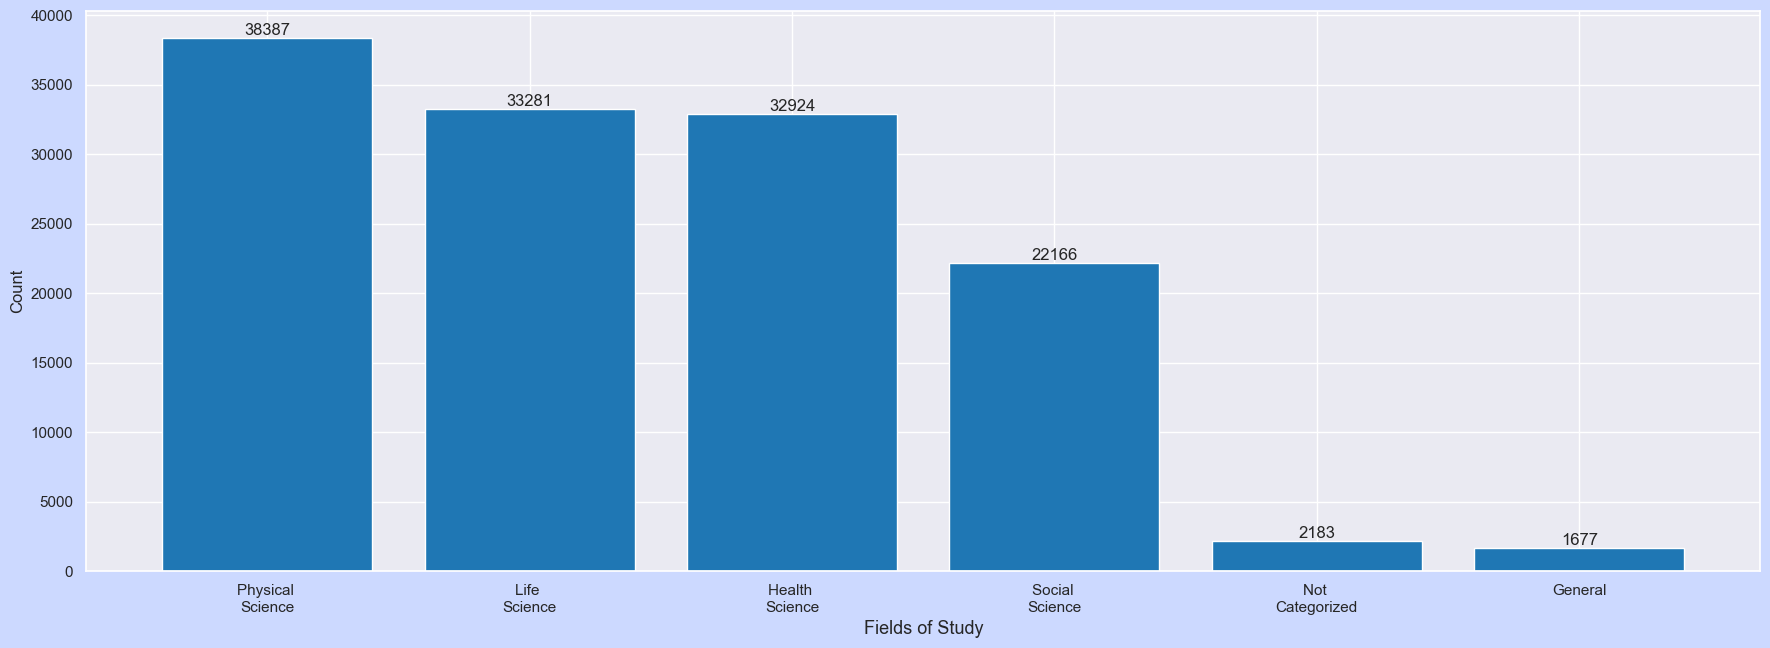

In [102]:
"""
Journal & Conference paper MainCategory Counts plot
"""
sns.set_theme()

# Create the figure and axis
fig07 = plt.figure(figsize=(18, 7))
ax07 = fig07.add_subplot(111)

# Plotting the bar chart
bars = ax07.bar(df_field['Fields of Study'], df_field['Count'], color='#1f77b4')

# Adding labels and title
ax07.set_xlabel('Fields of Study', fontsize=13)
ax07.set_ylabel('Count')
# ax07.set_title('Count of Fields of Study')

# Rotating x-axis labels for better readability
plt.xticks(rotation=0)

#  Adding labels to bars
for bar in bars:
    yval = bar.get_height()
    ax07.text(bar.get_x() + bar.get_width()/2, yval, int(yval), va='bottom', ha='center')


fig07.patch.set_facecolor('#ccd9ff')

# Remove the space outside the plot
plt.subplots_adjust(left=0.05, right=0.98, top=0.9, bottom=0.1)


# Saving
plt.savefig(result_dir+'journalandconferencecategory_count.png')
# Show plot
plt.show()



## Section 7: Investigating 100% RetractionIndexingAgreement

In [103]:
"""
Investigating number source across 100% RetractionIndexingAgreement
"""

def ria100_distribution(source):
    """
    It finds the distribution of 100% RetractionIndexingAgreement_ITEM(%) for a given source: finding out
    how many databases also index retracted IDs alongside
    :param source: database to check 
    :return: dataframe of indexed sources distribution
    """
    
    df100 = unionlist3_adjusted[unionlist3_adjusted['RetractionIndexingAgreement_ITEM(%)']==100].copy()
    s100= df100[df100.source_new.apply(lambda x: source in x )].copy()
    s100['size_source_old']= s100['source_old'].apply(lambda x: len(list(x.split(','))))
    s_count= dict(Counter(s100['size_source_old']))

    df = pd.DataFrame(s_count.items(), columns=['Category', 'Count'])
    
    df['LogCount'] = np.log(df['Count'] + 1)
    
    # Calculate the percentage of log count
    total_log_count = df['LogCount'].sum()
    df['LogCountPercentage'] = (df['LogCount'] / total_log_count) * 100
    
    # Compute the percentage
    total_count = df['Count'].sum()
    df['Percentage'] = (df['Count'] / total_count) * 100
    df.reset_index(drop='na', inplace=True)
    return df
    

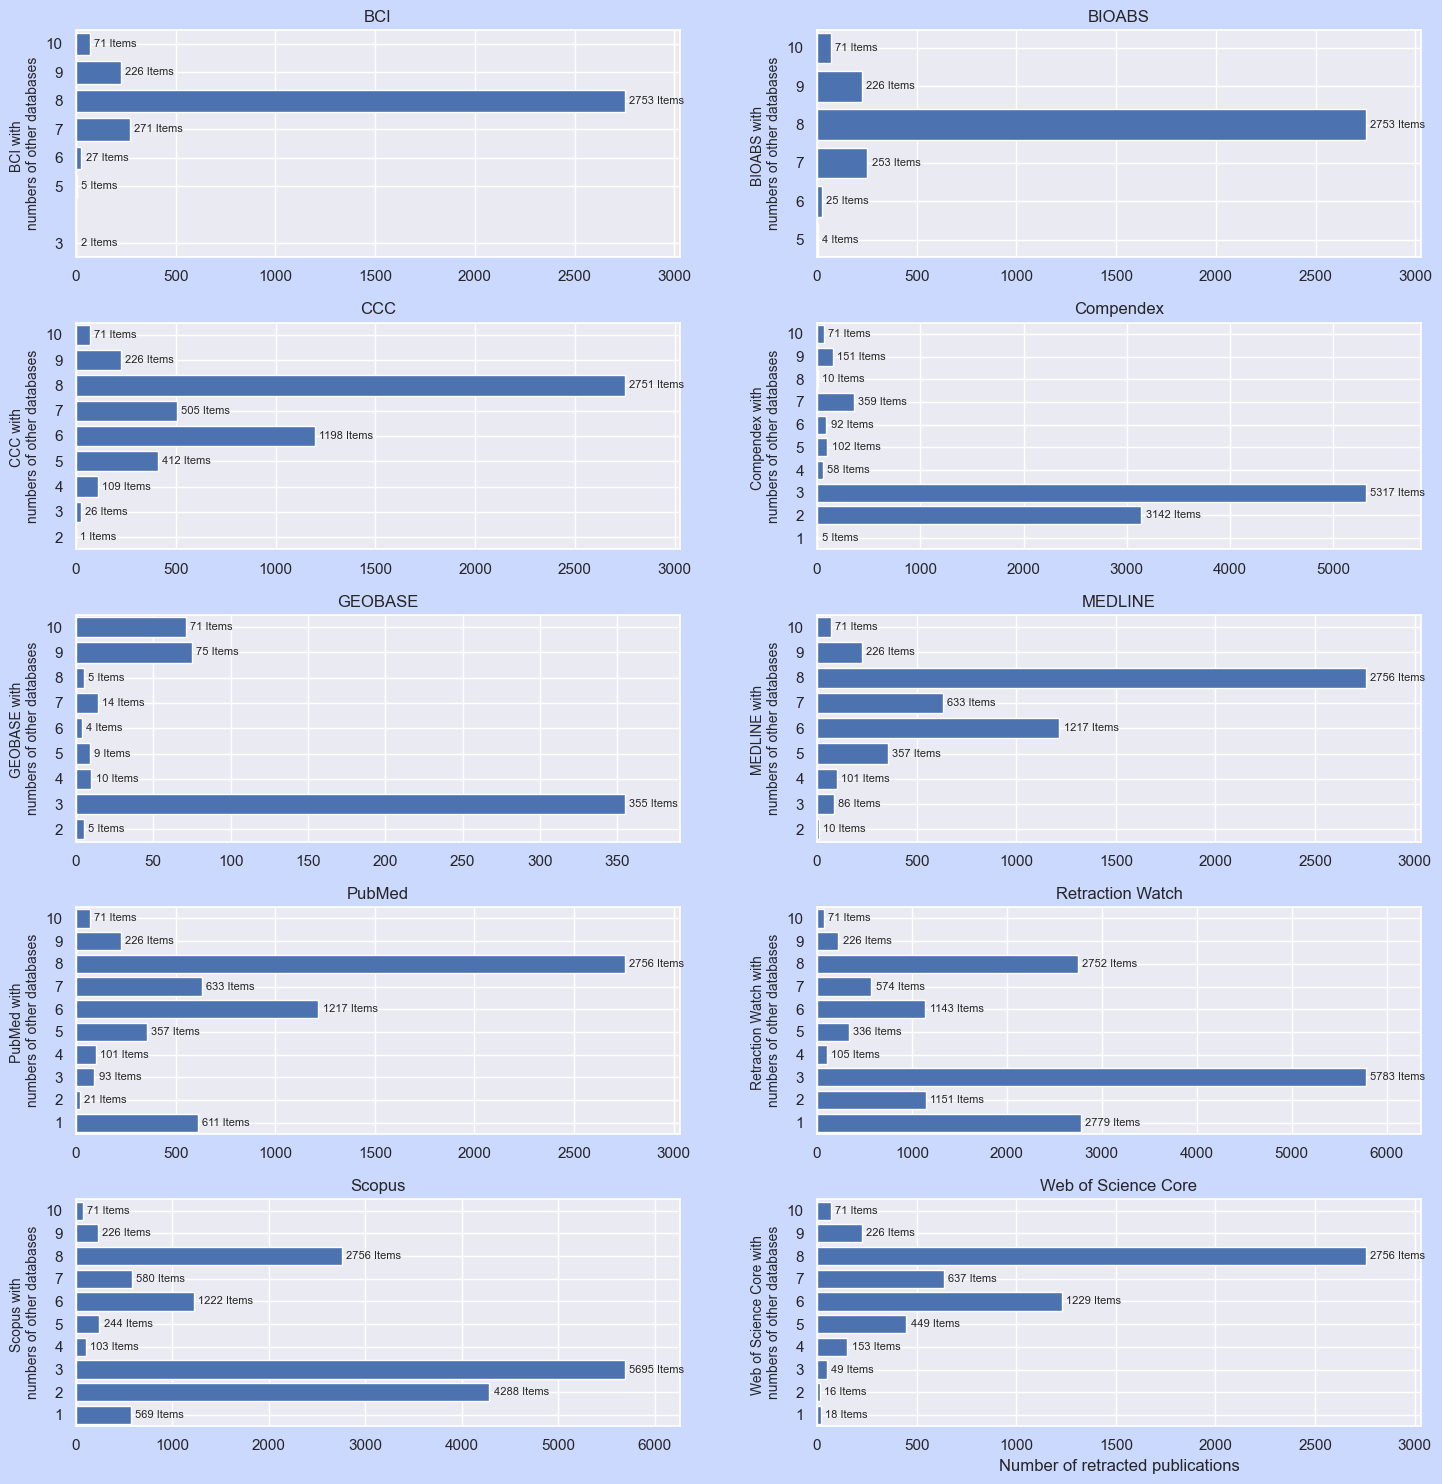

In [104]:
"""
Plotting shared # of IDs per source across 100% RetractionIndexingAgreement -All
"""

fig08, ax08 = plt.subplots(nrows=5, ncols=2,figsize=(15, 15))

for i, ax in enumerate(ax08.flat):  # Flatten the 3x2 array of axes
    if i < len(sources_indexed[:]):
        source = sources_indexed[i]
        df = ria100_distribution(source)

        # Define the desired order of categories

        # Create the bar plot          
        bars = ax.barh(df['Category'], df['Count'], align='center')

        # Annotate each bar with the count
        for bar, noDOIs in zip(bars, df['Count']):
            ax.annotate(f'{noDOIs} Items',
                        xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                        xytext=(3, 0),  # 5 points horizontal offset
                        textcoords='offset points',fontsize=8,
                        ha='left', va='center',) #rotation=90
        
        if source == 'Medline':
            source= source.upper()
        if source== 'WoS_Core':
            source='Web of Science Core'
                
        ax.set_title(f'{source}')
        ax.set_ylabel(f"{source} with \nnumbers of other databases", fontsize=10)
        
        # Set the y-axis labels to the correct order
        ax.set_yticks(df['Category'])
        ax.set_yticklabels(df['Category'])
        ax.margins(y=0.01,x=0.1)  #ax.margins(0.2)  
        
        # Only set x-axis label for subplots in the last row
        if i > 8:
            ax.set_xlabel('Number of retracted publications')
            
    else:
        fig08.delaxes(ax)

# Adjust margins to fit the annotations
plt.subplots_adjust(left=0.2, right=0.3,) # bottom=0.1, wspace=0.2, hspace=1

# fig08.suptitle('100% Retraction Indexing Agreement: Number of IDs co-indexed with other databases') 
fig08.patch.set_facecolor('#ccd9ff') 

plt.tight_layout()

# Save to folder
plt.savefig(result_dir+'distribution_of_RIA100_by_source_all.png')

# Show the plot
plt.show()

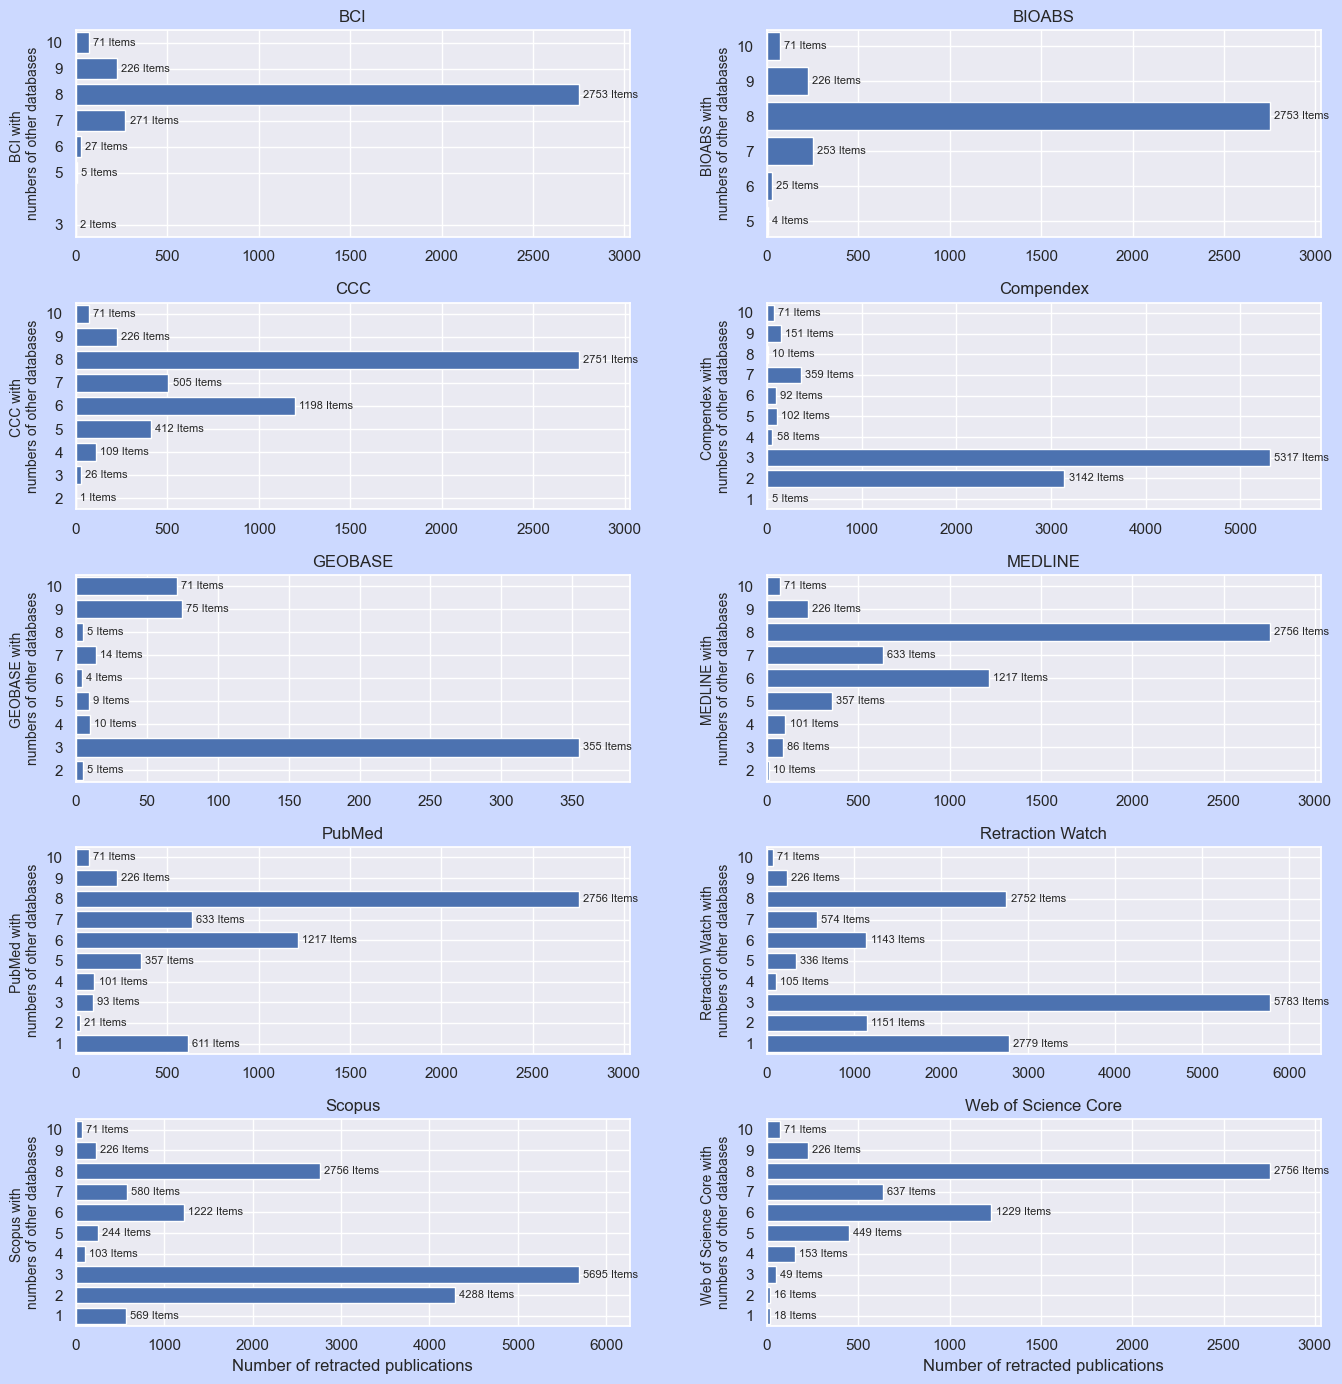

In [105]:
"""
Plotting shared # of IDs per source across 100% RetractionIndexingAgreement -1
"""

fig08_0, ax08_0 = plt.subplots(nrows=5, ncols=2, figsize=(14, 14))

for i, ax in enumerate(ax08_0.flat):  # Flatten the 3x2 array of axes
    if i < len(sources_indexed[:10]):
        source = sources_indexed[i]
        df = ria100_distribution(source)

        # Create the bar plot
        bars = ax.barh(df['Category'], df['Count'], align='center')

        # Annotate each bar with the count
        for bar, noDOIs in zip(bars, df['Count']):
            ax.annotate(f'{noDOIs} Items',
                        xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                        xytext=(3, 0),  # 5 points horizontal offset
                        textcoords='offset points',fontsize=8,
                        ha='left', va='center',) #rotation=90
        
        if source == 'Medline':
            source= source.upper()
        if source == 'WoS_Core':
            source= 'Web of Science Core'
        ax.set_title(f'{source}')
        ax.set_ylabel(f"{source} with \nnumbers of other databases", fontsize=10)
        # Set the y-axis labels to the correct order
        ax.set_yticks(df['Category'])
        ax.set_yticklabels(df['Category'])
        ax.margins(y=0.01,x=0.1)  #ax.margins(0.2)  
        
            # Only set x-axis label for subplots in the last row
        if i > 7:
            ax.set_xlabel('Number of retracted publications')
        
# Adjust margins to fit the annotations
plt.subplots_adjust(left=0.2, right=0.3,) # bottom=0.1, wspace=0.2, hspace=1

# fig08_0.suptitle('100% Retraction Indexing Agreement: Number of IDs co-indexed with other databases') 
fig08_0.patch.set_facecolor('#ccd9ff') 

plt.tight_layout()

# Save to folder
plt.savefig(result_dir+'distribution_of_RIA100_by_source1.png')

# Show the plot
plt.show()

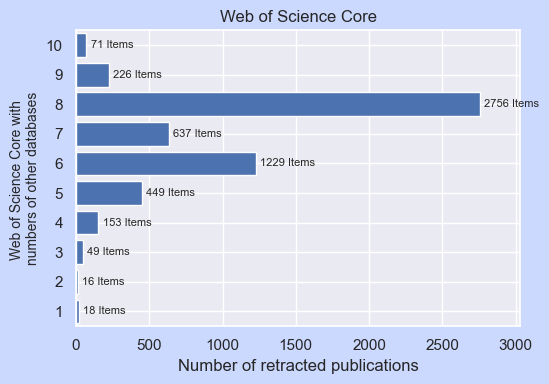

In [107]:
"""
Plotting shared # of IDs per source across 100% RetractionIndexingAgreement -2
"""

fig08_1, ax08_1 = plt.subplots(nrows=1, ncols=1, figsize=(6, 4))
df_ws = ria100_distribution('WoS_Core')

bars = ax08_1.barh(df_ws['Category'], df_ws['Count'], align='center')

# Annotate each bar with the count
for bar, noDOIs in zip(bars, df_ws['Count']):
    ax08_1.annotate(f'{noDOIs} Items',
    xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
    xytext=(3, 0),  # 5 points horizontal offset
    textcoords='offset points',fontsize=8,
    ha='left', va='center',) #rotation=90
        
source= 'Web of Science Core'
ax08_1.set_title(f'{source}')
ax08_1.set_ylabel(f"{source} with \nnumbers of other databases", fontsize=10)
        
# Set the y-axis labels to the correct order
ax08_1.set_yticks(df['Category'])
ax08_1.set_yticklabels(df['Category'])
ax08_1.margins(y=0.01,x=0.1)  #ax.margins(0.2)  
ax08_1.set_xlabel('Number of retracted publications')
        
# Adjust margins to fit the annotations
plt.subplots_adjust(left=0.2, right=0.3,) # bottom=0.1, wspace=0.2, hspace=1

# fig08_1.suptitle('100% Retraction Indexing Agreement: Number of IDs Co-Indexed with Other Databases') 
fig08_1.patch.set_facecolor('#ccd9ff') 

plt.tight_layout()

# Save to folder
plt.savefig(result_dir+'distribution_of_RIA100_by_source2.png')

plt.show()



### END